In [9]:
%load_ext autoreload
%autoreload 2
import numpy as np
import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
from sklearn.linear_model import Lasso, Ridge, LinearRegression, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPClassifier
import warnings
from sklearn.exceptions import ConvergenceWarning   # For part D4 so it will run
warnings.simplefilter("ignore", ConvergenceWarning)
import seaborn as sns
import time

# ==============================================================================

import plot_params
from config import SEED, K_FOLDS, FIGURES_PATH, RESULTS_PATH, DATA_PATH
from Data.data import load_mnist, train_val_split, one_hot, to_column
from Machine.network import NeuralNetwork, make_nn, NeuralNetClassifier
from Machine.optimizers import train
from Machine.metrics import (mse_score, accuracy, confusion_matrix, precision_recall_f1,
                             se, binomial_se)
import utils as u           # Reused functions from Project 1 + helper functions
import Data.plots as P

RERUN = True               # load saved results when they exist
COL = plot_params.COL       # our latex template column width in inches

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part b)** Neural network

</div>

Runge data from Project 1, with a validation split of the training data for
tuning

In [7]:
runge_x_train, runge_x_test, runge_y_train, runge_y_test = u.create_dataset(rescale=False)

# (n, 1) for the network and sklearn
runge_X_train, runge_X_test = to_column(runge_x_train), to_column(runge_x_test)
runge_Y_train, runge_Y_test = to_column(runge_y_train), to_column(runge_y_test)

# Split 25% of train set for validation
runge_X_fit, runge_X_val, runge_Y_fit, runge_Y_val = train_val_split(
    runge_X_train, runge_Y_train, val_size=0.25, seed=SEED, stratify=False)

cv_folds = KFold(K_FOLDS, shuffle=True, random_state=SEED)

Helper functions for CV analysis

In [8]:
def cv_scores(model, X, y, cv=cv_folds, cap=1.0, n_jobs=None):
    '''Train and validation MSE in every fold. A diverged fold (MSE above cap) becomes NaN'''
    res = cross_validate(model, X, y, cv=cv, scoring="neg_mean_squared_error",
                         return_train_score=True, error_score=np.nan, n_jobs=n_jobs)
    train_mse, val_mse = -res["train_score"], -res["test_score"]
    diverged = ~(val_mse <= cap)
    train_mse[diverged], val_mse[diverged] = np.nan, np.nan
    return train_mse, val_mse


def fold_arrays(X, y, train_idx, val_idx):
    '''
    Scaling and centering fitted on the training part only, as make_nn does inside
    cross_validate.
    For runs where we need the history per epoch, which cross_validate does not give.
    '''
    scaler = StandardScaler().fit(X[train_idx])
    y_mean = y[train_idx].mean()
    return(scaler.transform(X[train_idx]), to_column(y[train_idx] - y_mean),
           scaler.transform(X[val_idx]), to_column(y[val_idx] - y_mean))

OLS benchmark: best polynomial degree by k-fold CV on the training data

OLS: best degree 12 (CV MSE 0.0141), train MSE 0.0104, test MSE 0.0093


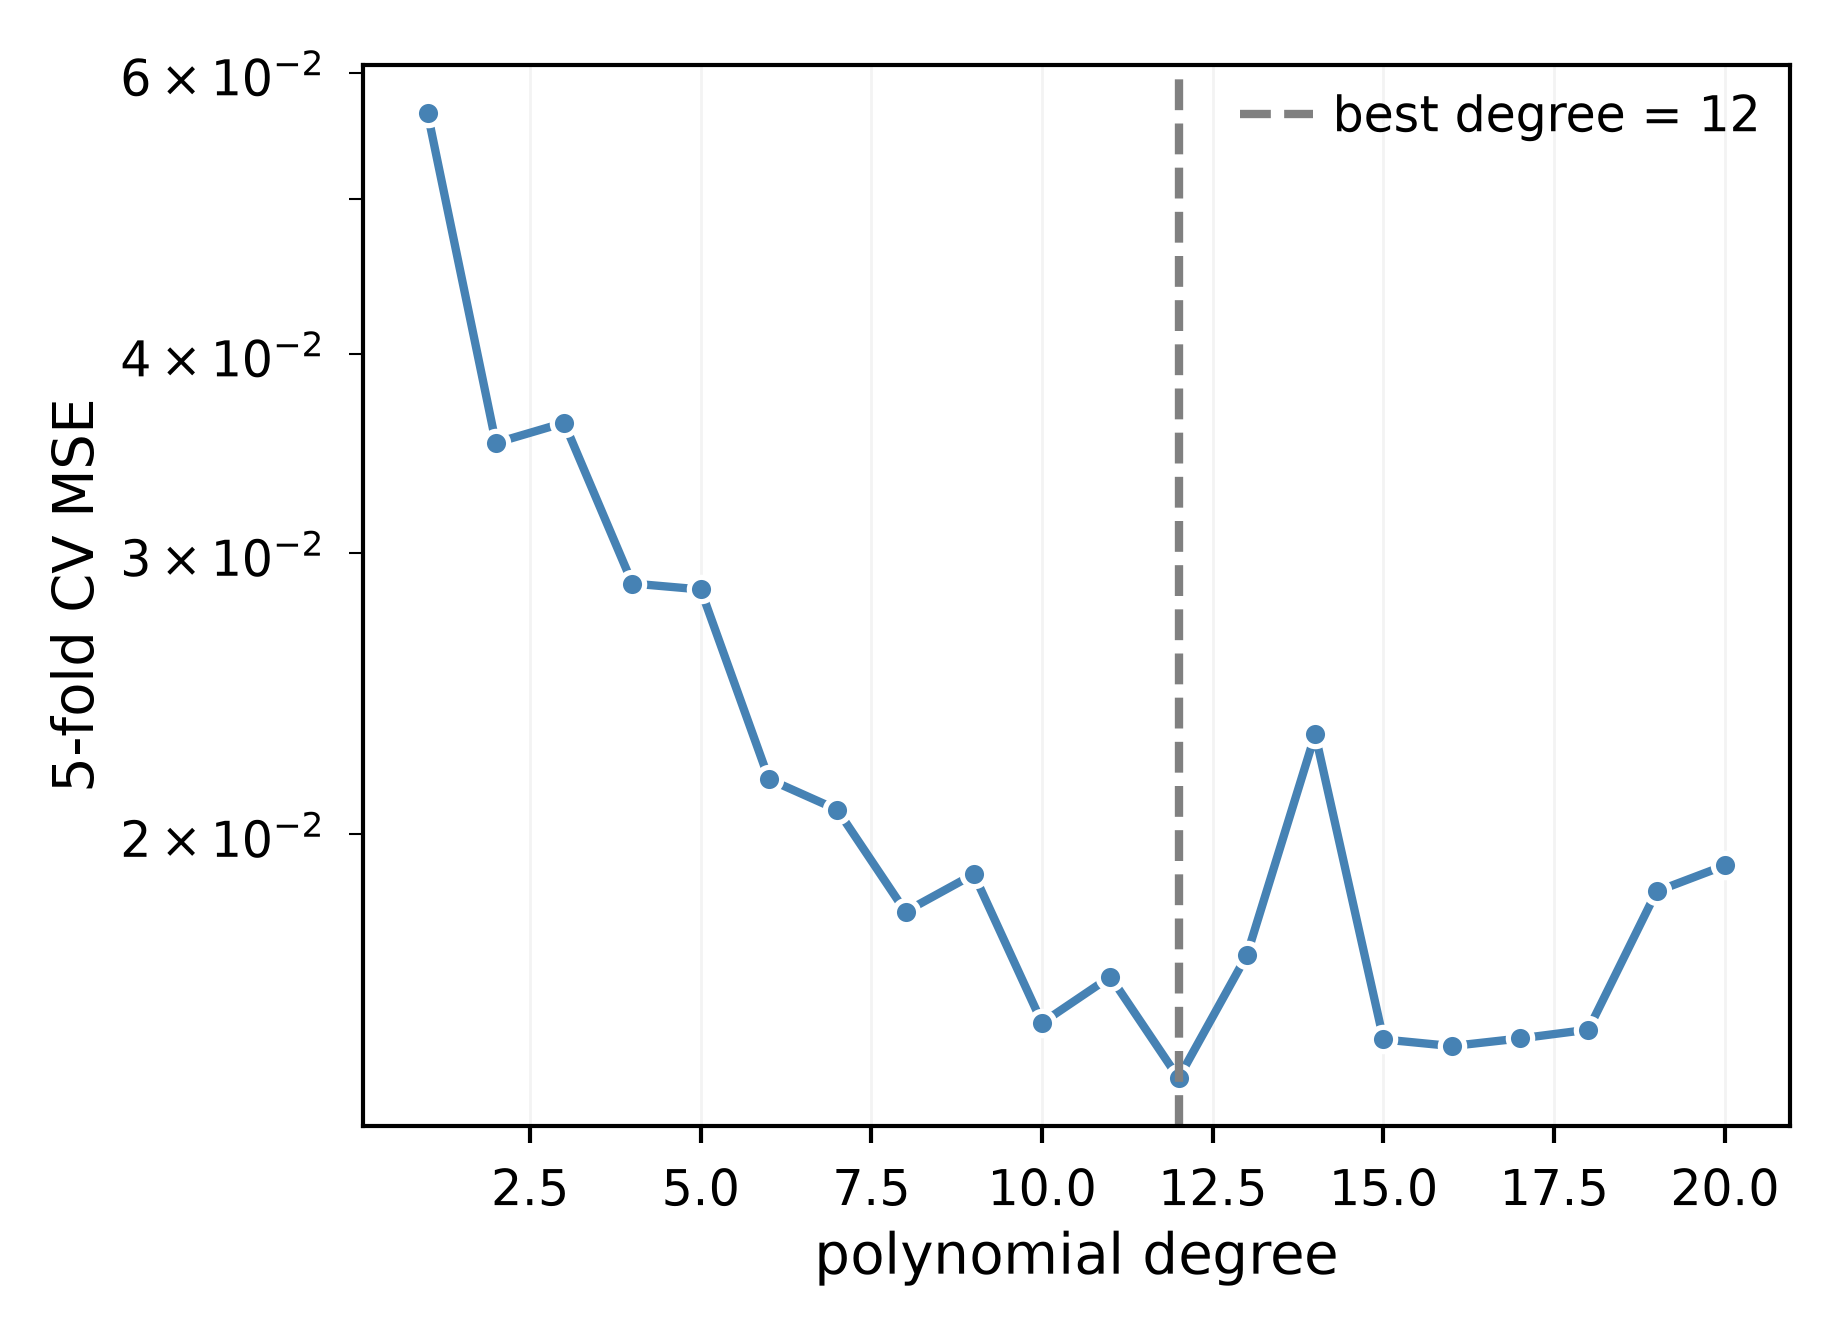

In [ ]:
MAX_DEGREE = 20

def compute_ols_cv():
    cv_mse, cv_se = u.k_fold_degrees(runge_X_train, runge_y_train, K_FOLDS,
                                     LinearRegression(), maxdegree=MAX_DEGREE, return_se=True)
    return {"cv_mse": cv_mse, "cv_se": cv_se, "degrees": np.arange(1, MAX_DEGREE + 1)}

ols_cv = u.cached_arrays(RESULTS_PATH / "b_ols_cv.npz", compute_ols_cv, RERUN)
best_ols = u.best_cell(ols_cv["cv_mse"], degree=ols_cv["degrees"])
best_degree = int(best_ols["degree"])
ols_se = ols_cv["cv_se"][best_ols["index"]]

# the lowest degree whose CV MSE is within 1 SE of the best
simplest_degree = int(ols_cv["degrees"][ols_cv["cv_mse"] <= best_ols["value"] + ols_se][0])

# ==============================================================================

# Refit on whole training set, and look at test set once
ols_model = u.poly_model(best_degree, LinearRegression()).fit(runge_X_train, runge_y_train)
ols_train_mse = mse_score(runge_y_train, ols_model.predict(runge_X_train))
ols_test_mse = mse_score(runge_y_test, ols_model.predict(runge_X_test))
print(f"OLS: best degree {best_degree} (CV MSE {best_ols['value']:.4f} ± {ols_se:.4f}), "
      f"1-SE degree {simplest_degree}, train MSE {ols_train_mse:.4f}, test MSE {ols_test_mse:.4f}")

Learning rate sweep

Best: SGD + RMSprop, gamma = 1.0e-01, val MSE 0.0144


NameError: name 'val_plot' is not defined

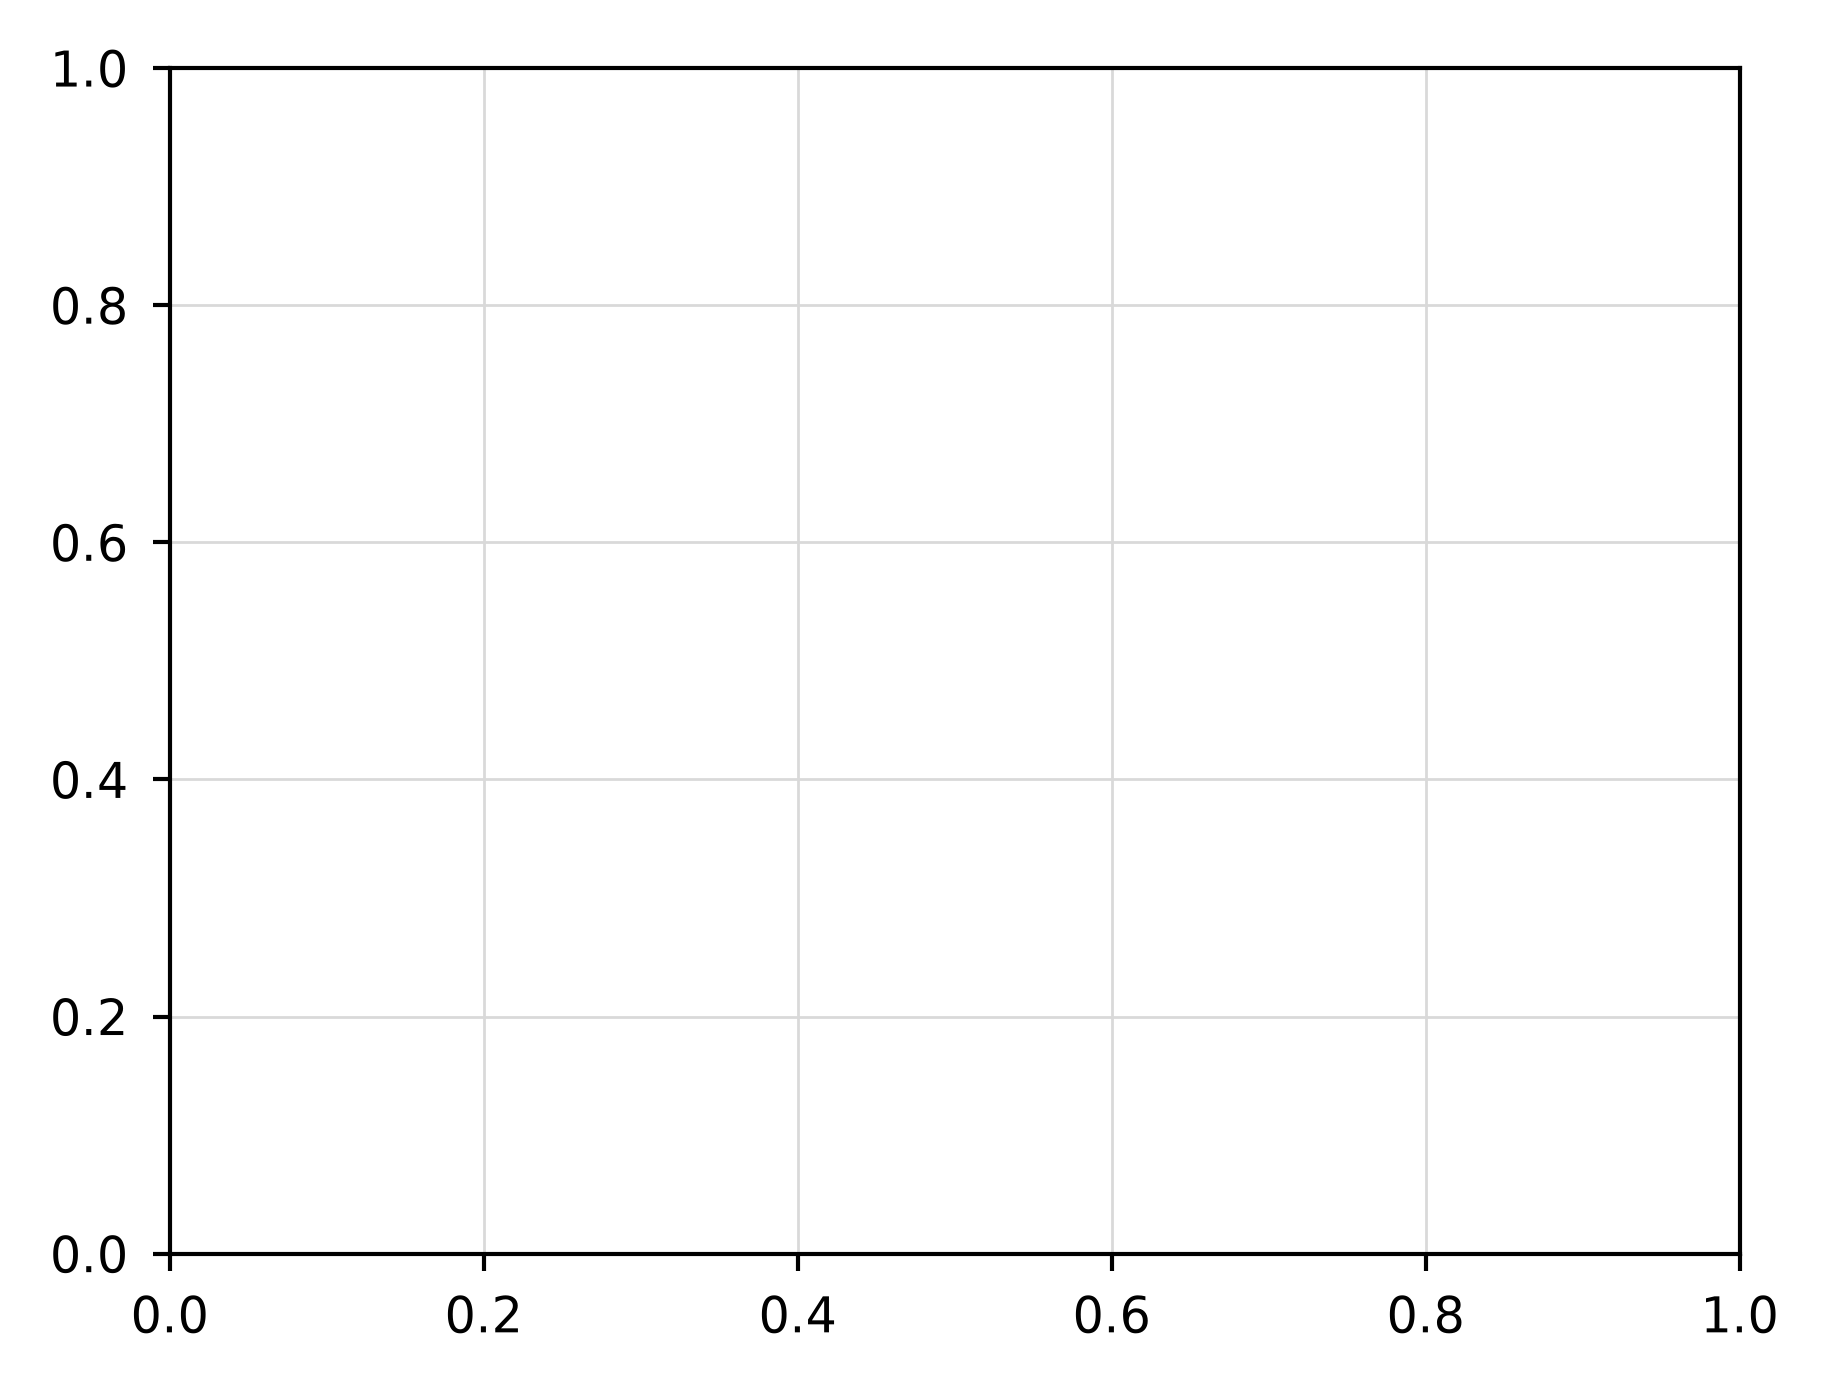

In [4]:
OPTIMIZERS = {                        # label: (model, batch size)
    "GD (full batch)": ("plain", None),
    "SGD": ("plain", 10),
    "SGD + RMSprop": ("rmsprop", 10),
    "SGD + Adam": ("adam", 10)
}
LEARNING_RATES = np.geomspace(1e-4, 1.0, 9)
EPOCHS_B = 1000

def compute_lr_sweep():
    val_mse = np.full((len(OPTIMIZERS), len(LEARNING_RATES)), np.nan)
    for i, (method, batch_size) in enumerate(OPTIMIZERS.values()):
        for j, gamma in enumerate(LEARNING_RATES):
            net = NeuralNetwork([1, 50, 1], ["sigmoid", "identity"], "mse", seed=SEED)
            with np.errstate(all="ignore"):
                train(net, runge_X_fit, runge_Y_fit, method=method, gamma=gamma,
                      epochs=EPOCHS_B, batch_size=batch_size, seed=SEED)
                val_mse[i, j] = mse_score(runge_Y_val, net.predict(runge_X_val))
    return {"val_mse": val_mse, "gammas" : LEARNING_RATES}

lr_sweep = u.cached_arrays(RESULTS_PATH / "b_lr_sweep.npz", compute_lr_sweep, RERUN)
best_b = u.best_cell(lr_sweep["val_mse"], optimizer=list(OPTIMIZERS), gamma=lr_sweep["gammas"])
print(f"Best: {best_b['optimizer']}, gamma = {best_b['gamma']:.1e}, val MSE {best_b['value']:.4f}")

fig, ax = plt.subplots(figsize=(COL, 2.7))
for i, (label, curve, marker) in enumerate(zip(OPTIMIZERS, val_plot, "osv^")):
    sns.lineplot(x=lr_sweep["gammas"], y=curve, label=label, marker=marker, ax=ax)
ax.axhline(0.01, color="0.4", ls=":", lw=0.8, label="noise floor")   # noise floor
ax.axhline(best_ols["value"], color="k", ls="--", lw=0.8, label="OLS (CV)")
ax.set(xscale="log", yscale="log",
       xlabel=r"learning rate $\gamma$", ylabel="validation MSE")
ax.legend(loc="upper left")

Architectures: for each, pick $\gamma$ on the validation set, retrain on the
full training set, then evaluate once on the test set

In [ ]:
ARCHITECTURES = {               # label: layer sizes [input, hiden..., output]
    "1 x 50":   [1, 50, 1],
    "1 x 500":  [1, 500, 1],
    "2 x 50":   [1, 50, 50, 1],
    "2 x 100":  [1, 100, 100, 1]
}
# Best optimizer from the learning-rate sweep
best_method, best_batch_size = OPTIMIZERS[best_b["optimizer"]]

# Dense grid on the standardizes coordinates, to draw smooth curves
runge_x_raw, runge_y_raw = u.create_dataset(split=False, rescale=False)
grid_x = np.linspace(-1, 1, 400)
grid_x_std = (grid_x - runge_x_raw.mean()) / runge_x_raw.std()
runge_true_curve = 1 / (1 + 25 * grid_x**2) - runge_y_raw.mean()

def compute_architectures():
    n_arch = len(ARCHITECTURES)
    best_gammas, train_mse, test_mse = np.zeros(n_arch), np.zeros(n_arch), np.zeros(n_arch)
    curves = np.zeros((n_arch, len(grid_x_std)))
    for i, sizes in enumerate(ARCHITECTURES.values()):
        acts = ["sigmoid"] * (len(sizes) - 2) + ["identity"]
        
        # 1: choose gamma on the validation set
        val_mse = np.full(len(LEARNING_RATES), np.nan)
        for j, gamma in enumerate(LEARNING_RATES):
            net = NeuralNetwork(sizes, acts, "mse", seed=SEED)
            with np.errstate(all="ignore"):
                train(net, runge_X_fit, runge_Y_fit, method=best_method, gamma=gamma, 
                      epochs=EPOCHS_B, batch_size=best_batch_size, seed=SEED)
                val_mse[j] = mse_score(runge_Y_val, net.predict(runge_X_val))
        best_gammas[i] = u.best_cell(val_mse, gamma=LEARNING_RATES)["gamma"]
        
        # 2: retrain on the whole training set, then look at test set once
        net = NeuralNetwork(sizes, acts, "mse", seed=SEED)
        train(net, runge_X_train, runge_Y_train, method=best_method, gamma=best_gammas[i],
              epochs=EPOCHS_B, batch_size=best_batch_size, seed=SEED)
        train_mse[i] = mse_score(runge_Y_train, net.predict(runge_X_train))
        test_mse[i] = mse_score(runge_Y_test, net.predict(runge_X_test))
        curves[i] = net.predict(to_column(grid_x_std)).ravel()
    return {"best_gammas": best_gammas, "train_mse": train_mse, "test_mse": test_mse, "curves": curves}

arch_results = u.cached_arrays(RESULTS_PATH / "b_architectures.npz", compute_architectures, RERUN)

Results table and fitted curves, for OLS vs the four networks

model             gamma  train MSE  test MSE
OLS deg 12                  0.0104    0.0093
NN 1 x 50       1.0e-01     0.0148    0.0154
NN 1 x 500      1.0e-01     0.0114    0.0119
NN 2 x 50       1.0e-03     0.0112    0.0112
NN 2 x 100      1.0e-02     0.0100    0.0188


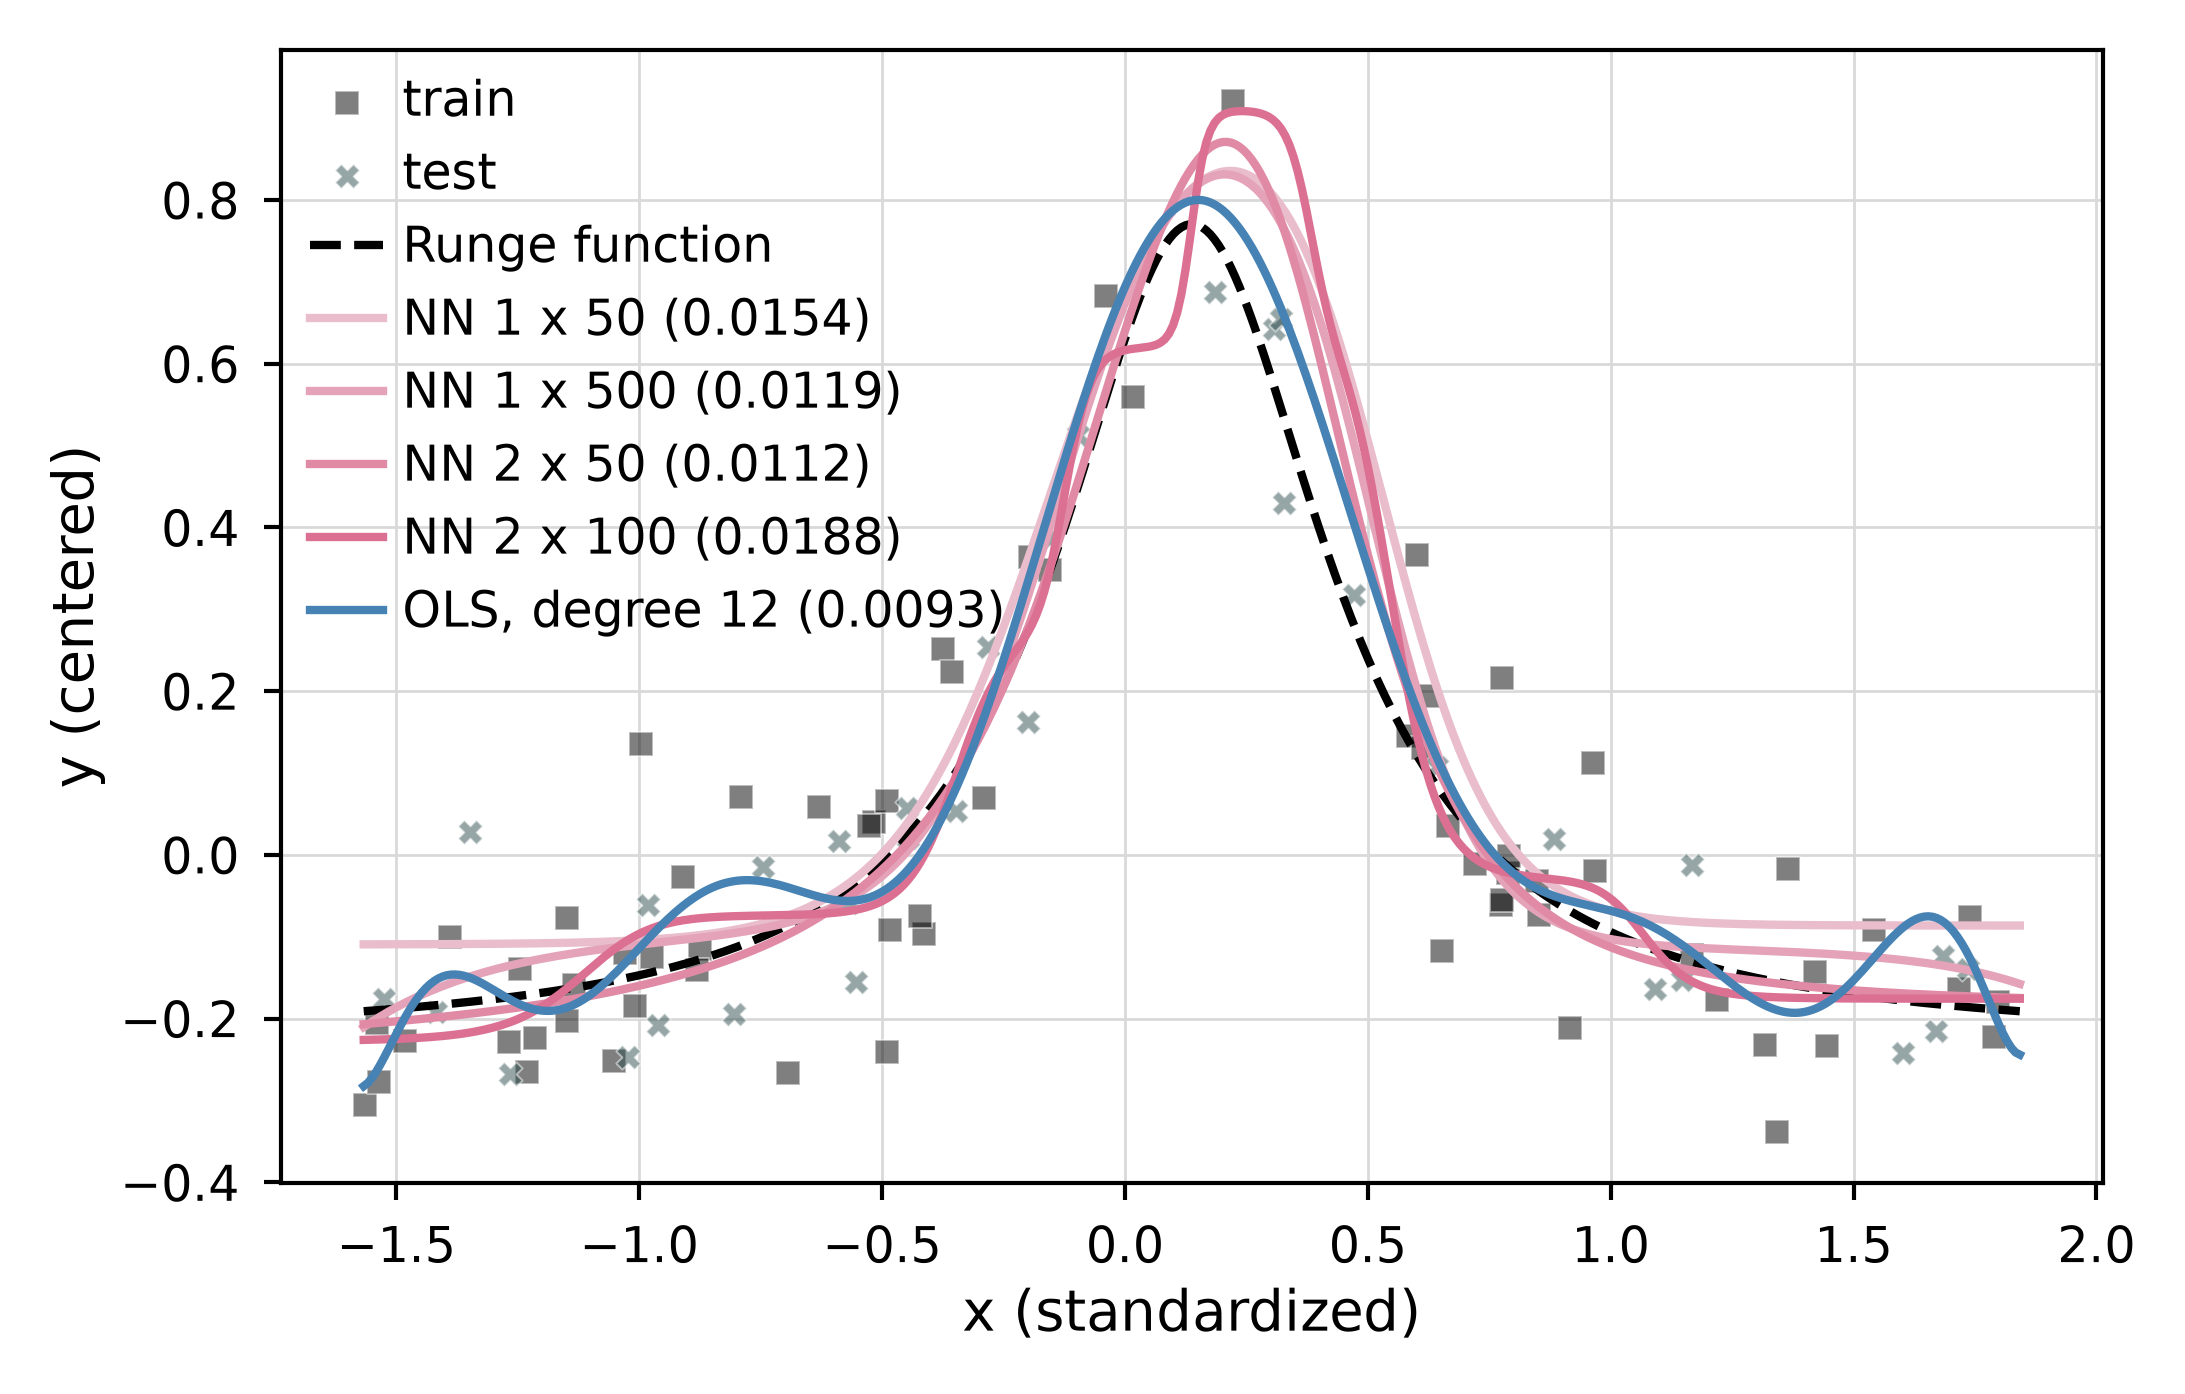

In [ ]:
ols_curve = ols_model.predict(grid_x_std.reshape(-1, 1))
nn_colors = sns.light_palette("palevioletred", len(ARCHITECTURES) + 2)[2:]

print(f"{'model':<14}{'gamma':>9}{'train MSE':>11}{'test MSE':>10}")
print(f"{'OLS deg ' + str(best_degree):<14}{'':>9}{ols_train_mse:>11.4f}{ols_test_mse:>10.4f}")
for label, gamma, tr, te in zip(ARCHITECTURES, arch_results["best_gammas"],
                                arch_results["train_mse"], arch_results["test_mse"]):
    print(f"{'NN ' + label:<14}{gamma:>9.1e}{tr:>11.4f}{te:>10.4f}")
    
fig, ax = plt.subplots(figsize=(COL * 1.2, 2.7))
sns.scatterplot(x=runge_x_train, y=runge_y_train, color="k", alpha=0.5, marker="s", label="train", ax=ax)
sns.scatterplot(x=runge_x_test, y=runge_y_test, color="darkslategray", alpha=0.5, marker="X", label="test", ax=ax)
ax.plot(grid_x_std, runge_true_curve, "k--", label="Runge function")
for (label, curve, te), color in zip(zip(ARCHITECTURES, arch_results["curves"], arch_results["test_mse"]), nn_colors):
    sns.lineplot(x=grid_x_std, y=curve, color=color, label=f"NN {label} ({te:.4f})", ax=ax)
sns.lineplot(x=grid_x_std, y=ols_curve, color="steelblue", 
             label=f"OLS, degree {best_degree} ({ols_test_mse:.4f})", ax=ax)
ax.set(xlabel="x (standardized)", ylabel="y (centered)")
ax.legend(loc="upper left")
fig.savefig(FIGURES_PATH / "B-NN_vs_OLS_fits.pdf")

<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part c)** Activation functions and depths

</div>

Sweep over activation, depth and $\gamma$, ran over several seeds

In [ ]:
ACTIVATIONS = ["sigmoid", "relu", "leaky_relu"]
DEPTHS = [1, 2, 3, 4]                   # number of hidden layers
WIDTHS = [10, 25, 50, 100]              # nodes per hidden layer
GAMMAS_C = np.geomspace(1e-3, 1.0, 4)
SEEDS_C = [0, 1, 2]                     # average over initializations
EPOCHS_C = 500

def run_one_runge(activation, depth, width, gamma, seed):
    '''Train one network on the fit set, then return its final train and validation MSE'''
    sizes = [1] + [width] * depth + [1]
    acts = [activation] * depth + ["identity"]
    net = NeuralNetwork(sizes, acts, "mse", seed=seed)
    history = train(net, runge_X_fit, runge_Y_fit, method="rmsprop", gamma=gamma,
                    epochs=EPOCHS_C, batch_size=10, seed=seed,
                    X_val=runge_X_val, Y_val=runge_Y_val)
    return history["train_cost"][-1], history["val_cost"][-1]


def compute_depth_width_sweep():
    shape = (len(ACTIVATIONS), len(DEPTHS), len(WIDTHS), len(GAMMAS_C), len(SEEDS_C))
    train_mse = np.full(shape, np.nan)          # Nan marks diverged runs
    val_mse = np.full(shape, np.nan)
    for a, d, w, g, s in np.ndindex(shape):     # loop over every grid point
        with np.errstate(all="ignore"):
            train_cost, val_cost = run_one_runge(ACTIVATIONS[a], DEPTHS[d], WIDTHS[w],
                                                 GAMMAS_C[g], SEEDS_C[s])
        if np.isfinite(train_cost) and np.isfinite(val_cost):
            train_mse[a, d, w, g, s], val_mse[a, d, w, g, s] = train_cost, val_cost
    return {"train_mse": train_mse, "val_mse": val_mse}

depth_width = u.cached_arrays(RESULTS_PATH / "c_depth_width.npz", compute_depth_width_sweep, RERUN)

Best $\gamma$ for every (activation, depth, width), shown as heat maps.
The overall winner is stored in `best_c`.

Overall best: relu, depth 4, width 25, gamma 1e-03, val MSE 0.0142
---------------------------------------------------------------
sigmoid    best: depth 3, width 50, gamma 1e-03, val MSE 0.0144
relu       best: depth 4, width 25, gamma 1e-03, val MSE 0.0142
leaky_relu best: depth 3, width 10, gamma 1e-03, val MSE 0.0148


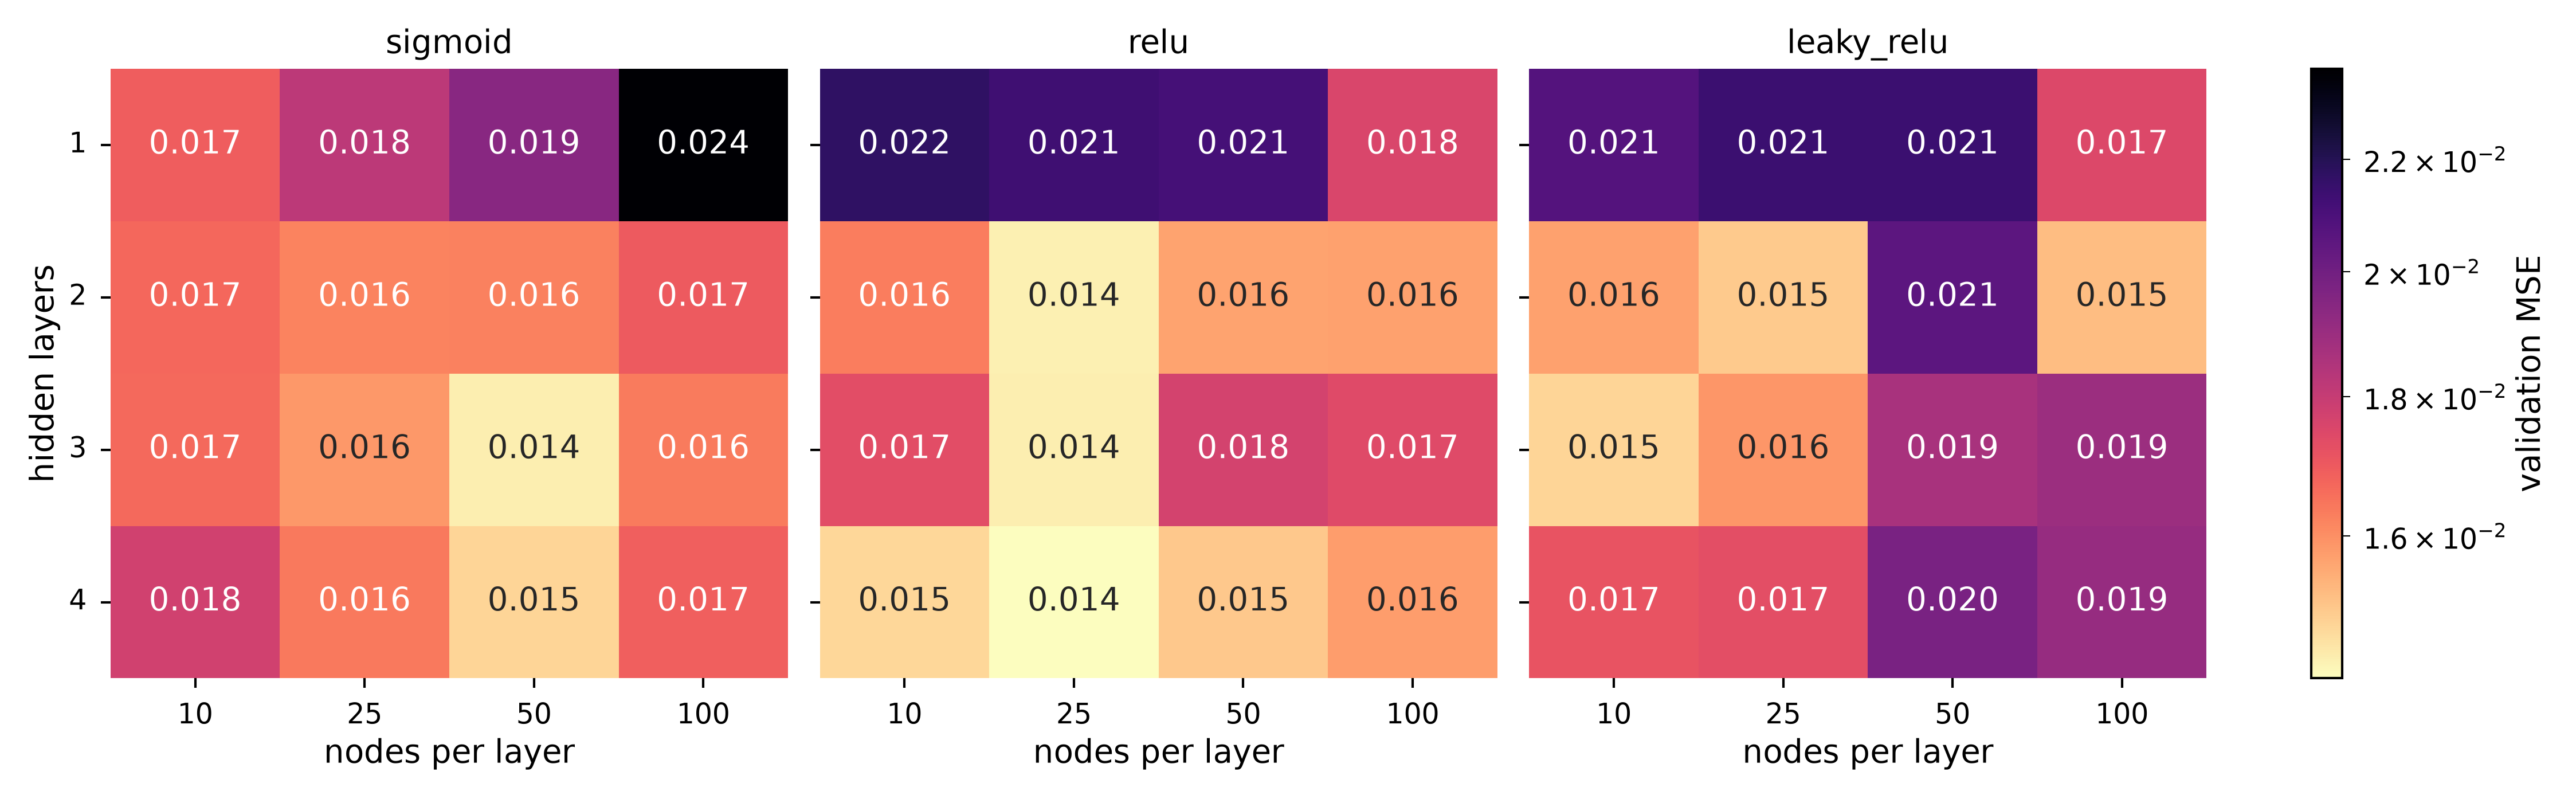

In [ ]:
val_mse_mean = depth_width["val_mse"].mean(axis=-1)     # average over seeds
best_c = u.best_cell(val_mse_mean, activation=ACTIVATIONS, depth=DEPTHS,
                     width=WIDTHS, gamma=GAMMAS_C)
print(f"Overall best: {best_c['activation']}, depth {best_c['depth']}, "
      f"width {best_c['width']}, gamma {best_c['gamma']:.0e}, val MSE {best_c['value']:.4f}")
print("---------------------------------------------------------------")
for a, activation in enumerate(ACTIVATIONS):
      best = u.best_cell(val_mse_mean[a], depth=DEPTHS, width=WIDTHS, gamma=GAMMAS_C)
      print(f"{activation:10s} best: depth {best['depth']}, width {best['width']}, "
            f"gamma {best['gamma']:.0e}, val MSE {best['value']:.4f}")

# Best gamma in every (activation, depth, width) cell
finite_val = np.where(np.isfinite(val_mse_mean), val_mse_mean, np.inf)
val_mse_best_gamma = finite_val.min(axis=-1)
val_mse_best_gamma[np.isinf(val_mse_best_gamma)] = np.nan

train_mse_mean = depth_width["train_mse"].mean(axis=-1)
best_g = np.argmin(finite_val, axis=-1)   # winning gamma per (act, depth, width)
a_i, d_i, w_i = np.indices(best_g.shape)
train_at_best = train_mse_mean[a_i, d_i, w_i, best_g]
gap = val_mse_best_gamma / train_at_best        # >1: validation worse than train

heat_min, heat_max = np.nanmin(val_mse_best_gamma), min(np.nanmax(val_mse_best_gamma), 1.0)
fig, axes = plt.subplots(1, 3, figsize=(COL * 2.5, 2.7), sharey=True)
for ax, activation, grid in zip(axes, ACTIVATIONS, val_mse_best_gamma):
      sns.heatmap(grid, ax=ax, cmap="magma_r", norm=LogNorm(heat_min, heat_max),
                  annot=True, fmt=".3f", cbar=False,
                  xticklabels=WIDTHS, yticklabels=DEPTHS)
      ax.set(title=activation, xlabel="nodes per layer")
      ax.tick_params(axis="y", rotation=0)
axes[0].set_ylabel("hidden layers")
fig.colorbar(axes[0].collections[0], ax=axes, label="validation MSE")
fig.savefig(FIGURES_PATH / "C-activation_depth_width.pdf")

Overfitting: train a long run of the biggest network per activation and compare
train and validation MSE

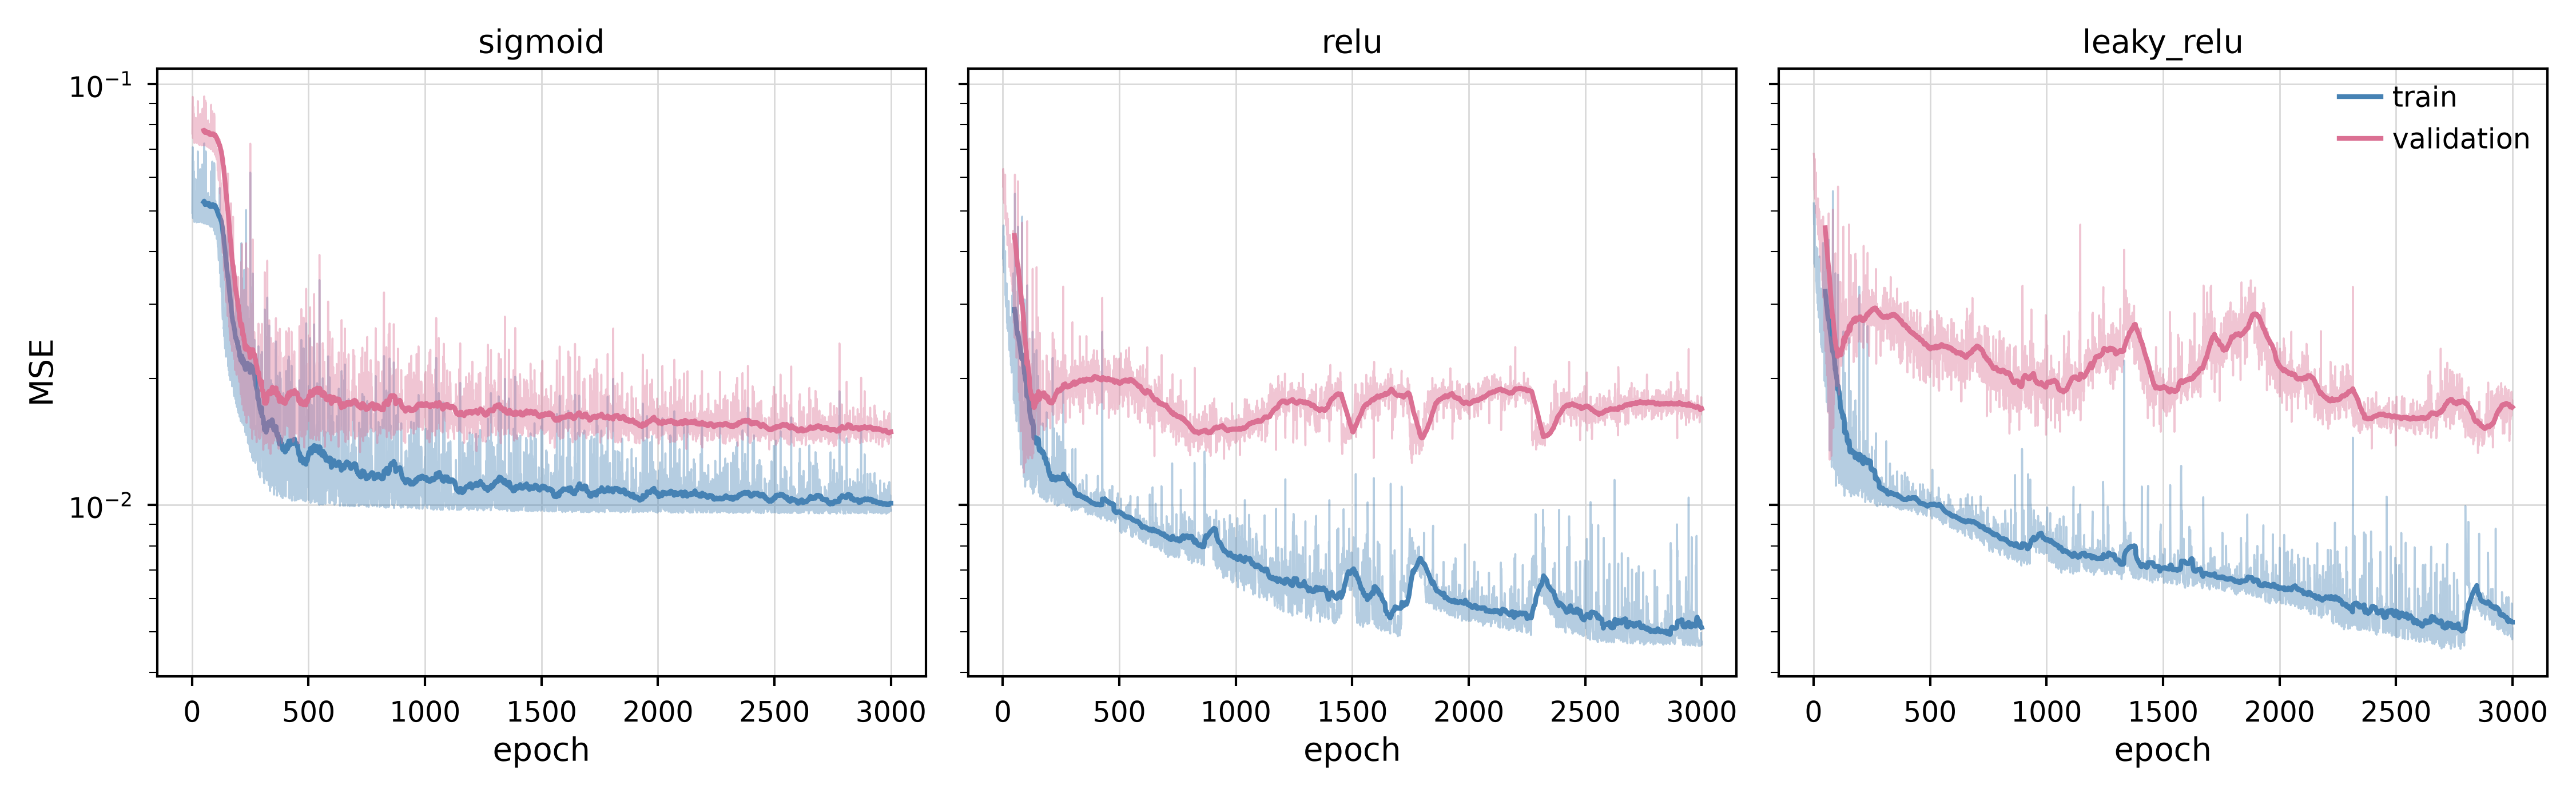

In [ ]:
EPOCHS_OVERFIT = 3000

def compute_overfitting_curves():
    n_act = len(ACTIVATIONS)
    train_curves, val_curves = np.full((n_act, EPOCHS_OVERFIT), np.nan), np.full((n_act, EPOCHS_OVERFIT), np.nan)
    gammas = np.zeros(n_act)
    for a, activation in enumerate(ACTIVATIONS):
        gammas[a] = GAMMAS_C[0]     # 1e-3 for all activations, so the panels are comparable
        net = NeuralNetwork([1] + [WIDTHS[-1]] * DEPTHS[-1] + [1],
                            [activation] * DEPTHS[-1] + ["identity"], "mse", seed=SEED)
        with np.errstate(all="ignore"):
            history = train(net, runge_X_fit, runge_Y_fit, method="rmsprop", gamma=gammas[a],
                            epochs=EPOCHS_OVERFIT, batch_size=10, seed=SEED,
                            X_val=runge_X_val, Y_val=runge_Y_val)
        train_curves[a], val_curves[a] = history["train_cost"], history["val_cost"]
    return {"train_curves": train_curves, "val_curves": val_curves, "gammas": gammas}


def smooth(y, k=50):
    '''Moving average over k epochs, so the RMSProp noise doesn't hide the trend'''
    return np.convolve(y, np.ones(k) / k, mode="valid")


overfit = u.cached_arrays(RESULTS_PATH / "c_overfitting_curves.npz", compute_overfitting_curves, RERUN)

epochs = np.arange(1, EPOCHS_OVERFIT + 1)
K_S = 50
x_s = epochs[K_S - 1:]
fig, axes = plt.subplots(1, 3, figsize=(COL * 2.5, 2.7), sharey=True)
for ax, activation, train_curve, val_curve in zip(
        axes, ACTIVATIONS, overfit["train_curves"], overfit["val_curves"]):
    for curve, color, label in ((train_curve, "C0", "train"), (val_curve, "C1", "validation")):
        sns.lineplot(x=epochs, y=curve, color=color, alpha=0.4, lw=0.5, ax=ax)
        sns.lineplot(x=x_s, y=smooth(curve, K_S), color=color, label=label, ax=ax)
    ax.set(yscale="log", title=f"{activation}", xlabel="epoch")
for ax in axes[:-1]:
    ax.get_legend().remove()        # one legend is enough
axes[0].set_ylabel("MSE")
fig.savefig(FIGURES_PATH / "C-train_val_curves.pdf")

Vanishing gradients: gradient norm per layer at initialization in a deep network

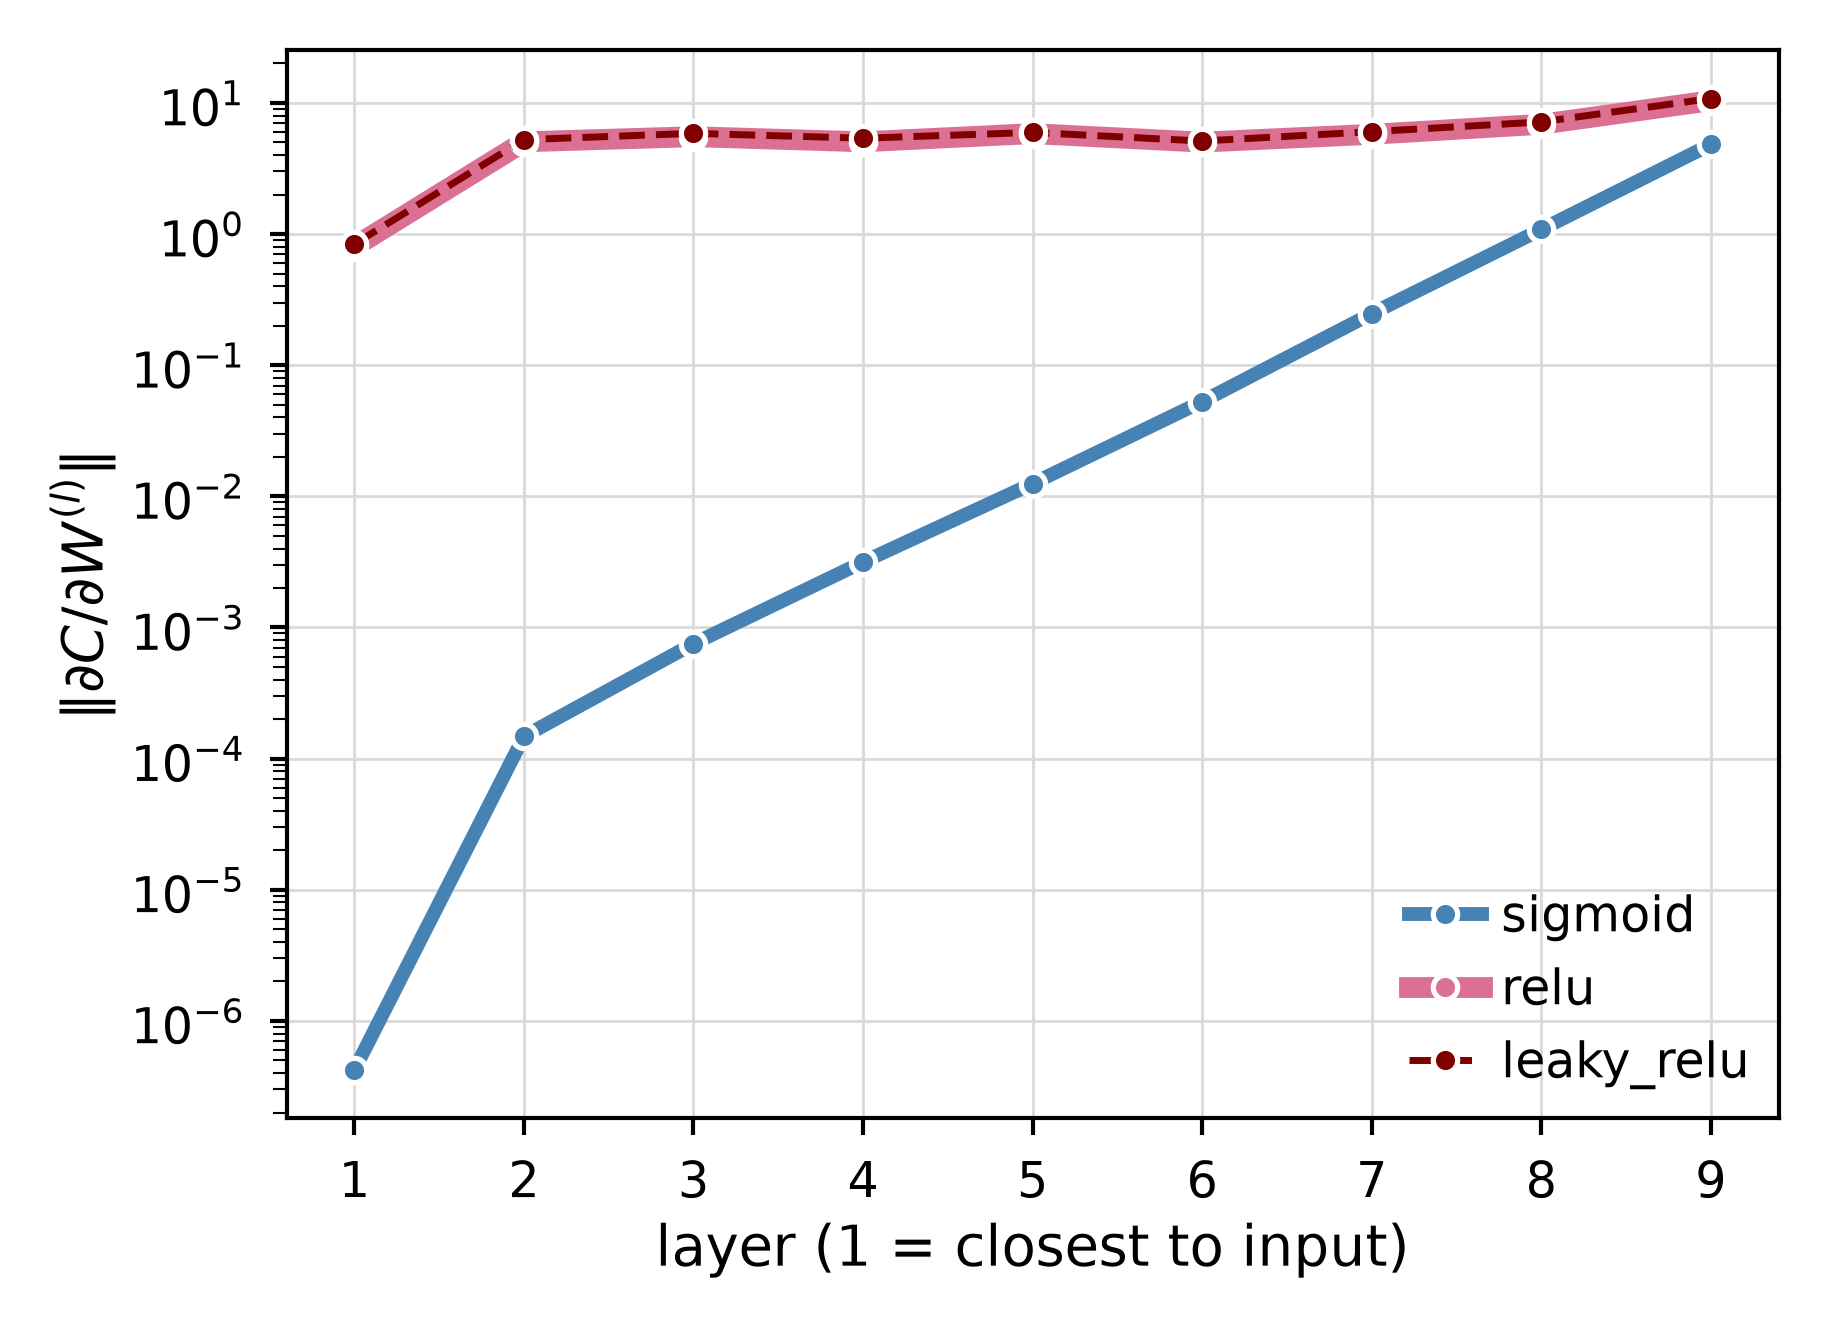

In [ ]:
def layer_grad_norms(activation, depth=8, width=50, seed=SEED):
    '''Norm of dC/dW in every layer at initialization (no training)'''
    net = NeuralNetwork([1] + [width] * depth + [1], 
                        [activation] * depth + ["identity"], "mse", seed=seed)
    gradients = net.compute_gradient(runge_X_fit, runge_Y_fit)
    return [np.linalg.norm(dW) for dW, _ in gradients]

fig, ax = plt.subplots()
extras = [{"ls": "-", "color": "steelblue", "lw": 2},
          {"ls": "-", "color": "palevioletred", "lw": 3},
          {"ls": "--", "color": "maroon", "lw": 1}]
for activation, extra in zip(ACTIVATIONS, extras):
    norms = layer_grad_norms(activation)
    sns.lineplot(x=np.arange(1, len(norms) + 1), y=norms, marker="o", label=activation, ax=ax, **extra)
ax.set(yscale="log", xlabel="layer (1 = closest to input)", ylabel=r"$\|\partial C/\partial W^{(l)}\|$")
fig.savefig(FIGURES_PATH / "C-gradient_norms.pdf")

<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part d)** Different norms

</div>

Get the best architecture from Part C for penalty study

In [ ]:
ARCH_ACTIVATION, ARCH_DEPTH, ARCH_WIDTH = best_c["activation"], best_c["depth"], best_c["width"]
print(f"{ARCH_ACTIVATION}, {ARCH_DEPTH} hidden layers x {ARCH_WIDTH} nodes")

relu, 4 hidden layers x 25 nodes


Sweep over penalty strength $\lambda$ and learning rate $\gamma$, for $\ell_2$ and $\ell_1$

In [ ]:
NORMS = ["l2", "l1"]
LAMBDAS = np.concatenate([[0], np.logspace(-6, -3, 7)])
GAMMAS_D = np.geomspace(1e-4, 1e-1, 7)
SEEDS_D = [0, 1, 2]
EPOCHS_D = 500

def run_one_penalized(norm, lam, gamma, seed):
    '''Train one network with an L1 or L2 penalty, and return its validation MSE (without the penalty term)'''
    lam1, lam2 = (lam, 0.0) if norm == "l1" else (0.0, lam)
    net = NeuralNetwork([1] + [ARCH_WIDTH] * ARCH_DEPTH + [1],
                        [ARCH_ACTIVATION] * ARCH_DEPTH + ["identity"],
                        "mse", lmbd1=lam1, lmbd2=lam2, seed=seed)
    train(net, runge_X_fit, runge_Y_fit, method="rmsprop", gamma=gamma, 
          epochs=EPOCHS_D, batch_size=10, seed=seed)
    return mse_score(runge_Y_val, net.predict(runge_X_val))


def compute_penalty_sweep():
    shape = (len(NORMS), len(LAMBDAS), len(GAMMAS_D), len(SEEDS_D))
    val_mse = np.full(shape, np.nan)
    for n, l, g, s in np.ndindex(shape):
        with np.errstate(all="ignore"):
            score = run_one_penalized(NORMS[n], LAMBDAS[l], GAMMAS_D[g], SEEDS_D[s])
        if np.isfinite(score):
            val_mse[n, l, g, s] = score
    return {"val_mse": val_mse}

penalty_sweep = u.cached_arrays(RESULTS_PATH / "d_penalty_sweep.npz", compute_penalty_sweep, RERUN)

Heat maps of validation MSE over $(\lambda\,\gamma)$.

Cyan box = best cell overall: `best_penalized` = best cell with $\lambda>0$.

l2: best lambda 1e-03, gamma 3e-04, val MSE 0.0133
l1: best lambda 3e-04, gamma 3e-04, val MSE 0.0131


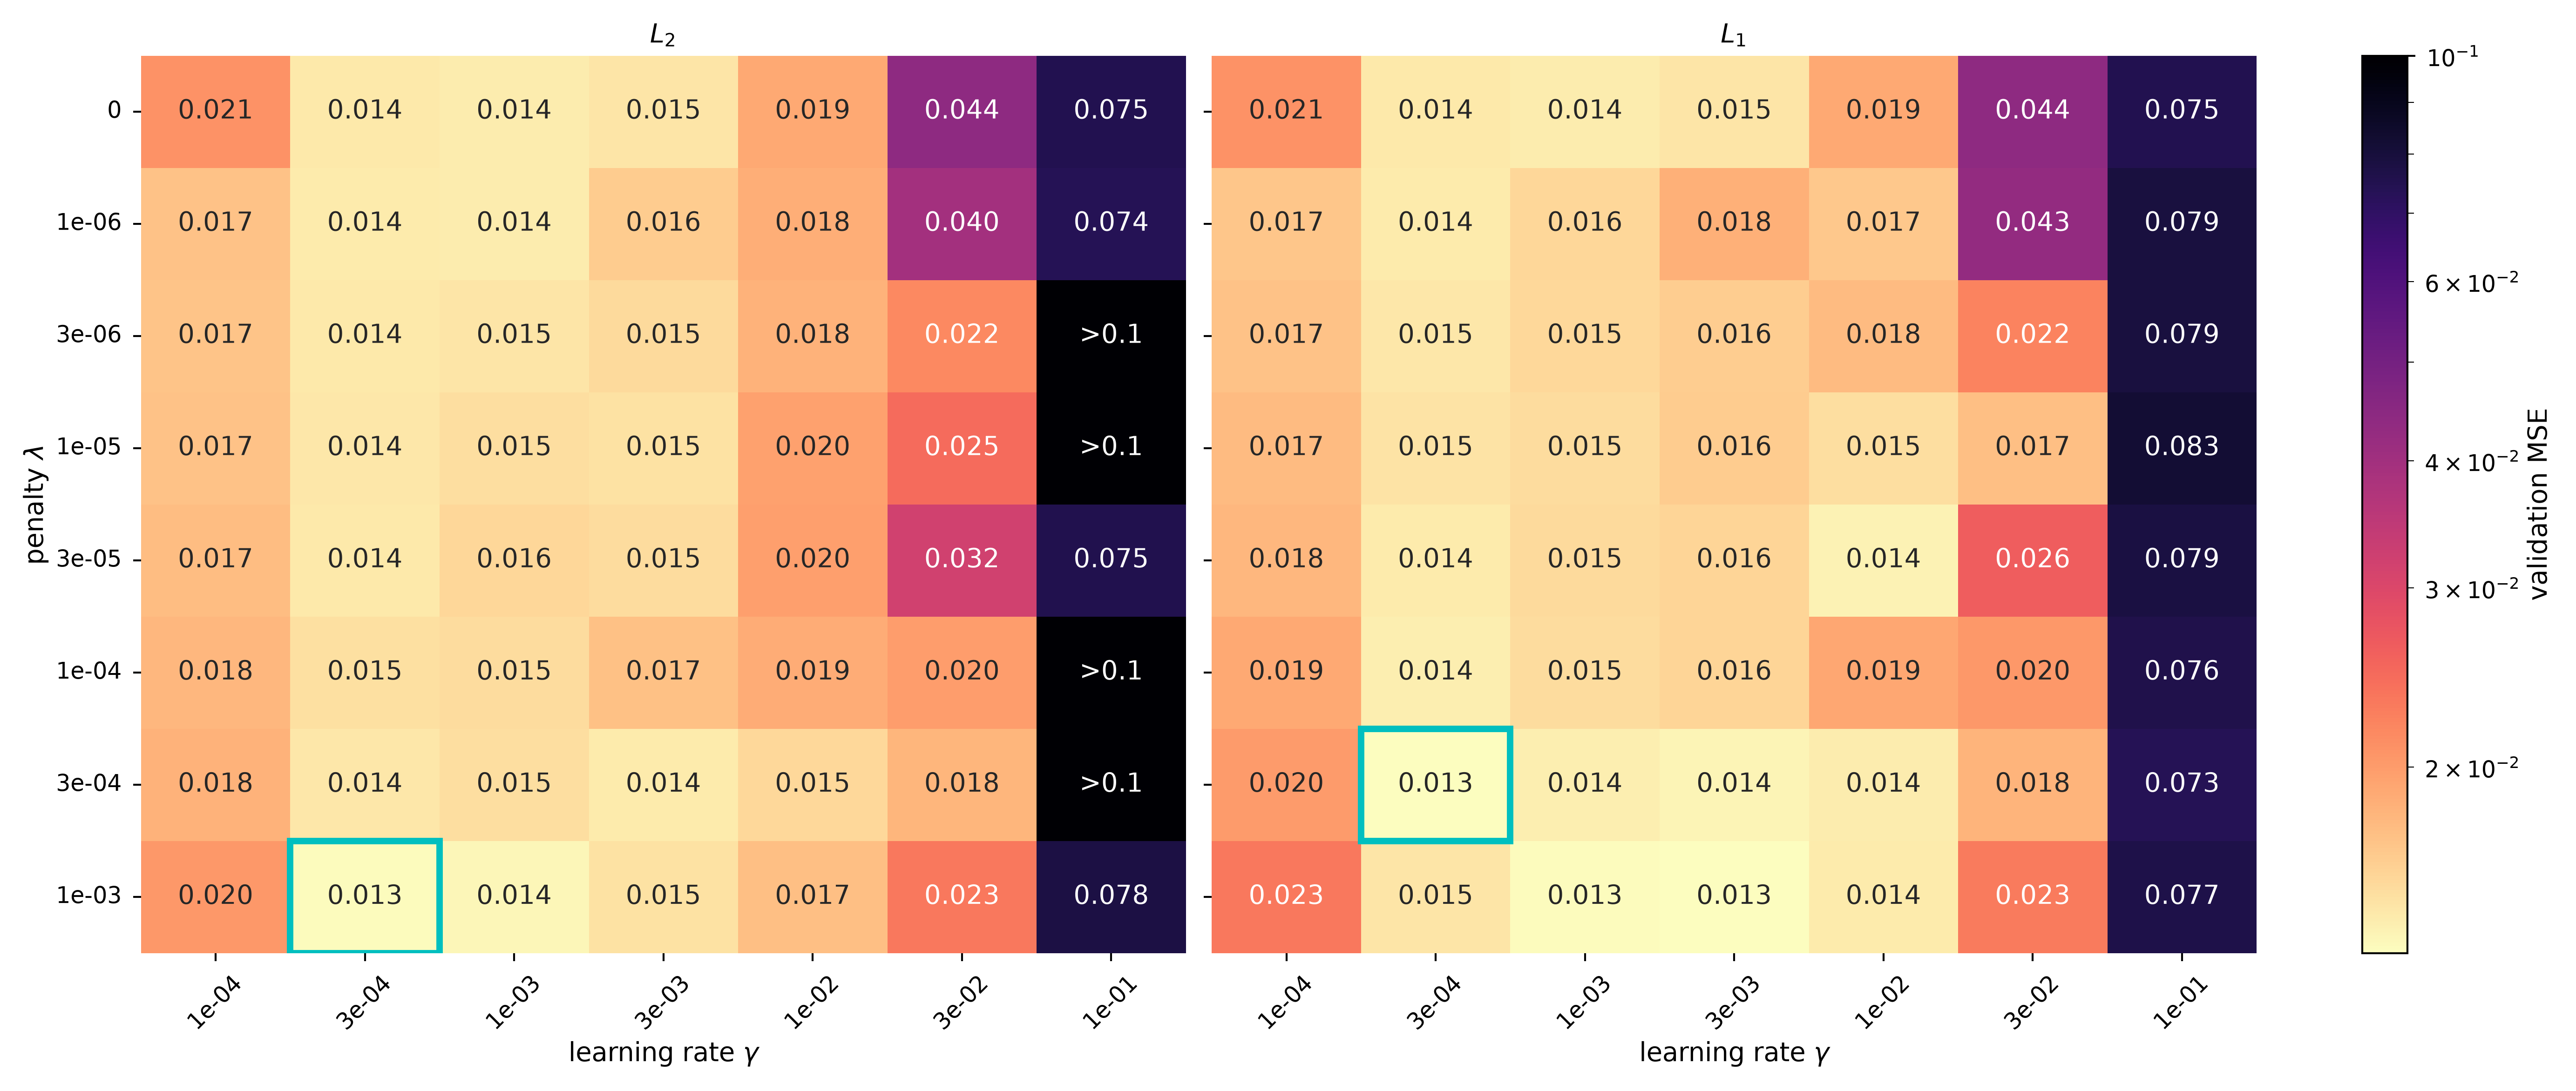

In [ ]:
MSE_CAP = 0.1   # above this, the network is no better than predicting the mean
val_mse_mean_d = penalty_sweep["val_mse"].mean(axis=-1)     # average over seeds
best_overall, best_penalized = {}, {}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for n, (ax, norm) in enumerate(zip(axes, NORMS)):
    grid = val_mse_mean_d[n]
    labels = np.where(grid < MSE_CAP, np.char.mod("%.3f", grid), ">0.1")
    sns.heatmap(grid, ax=ax, cmap="magma_r", norm=LogNorm(np.nanmin(val_mse_mean_d), MSE_CAP),
                annot=labels, fmt="", cbar=False,
                xticklabels=[f"{g:.0e}" for g in GAMMAS_D],
                yticklabels=[f"{l:.0e}" if l > 0 else "0" for l in LAMBDAS])
    ax.set(title=rf"$L_{norm[1]}$", xlabel=r"learning rate $\gamma$")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)
    
    best_overall[norm] = u.best_cell(grid, lam=LAMBDAS, gamma=GAMMAS_D)
    best_penalized[norm] = u.best_cell(grid[1:], lam=LAMBDAS[1:], gamma=GAMMAS_D)
    i, j = best_overall[norm]["index"]
    ax.add_patch(Rectangle((j, i), 1, 1, fill=False, ec="c",  lw=2))
    print(f"{norm}: best lambda {best_overall[norm]['lam']:.0e}, "
          f"gamma {best_overall[norm]['gamma']:.0e}, "
          f"val MSE {best_overall[norm]['value']:.4f}")
axes[0].set_ylabel(r"penalty $\lambda$")
fig.colorbar(axes[0].collections[0], ax=axes, label="validation MSE")
fig.savefig(FIGURES_PATH / "D-lambda_gamma.pdf")

Comparison with Project 1: Ridge and Lasso chosen by CV vs. the best penalized
networks, all evaluated once on the test set

model                  degree    lambda            test MSE
OLS (Project 1)            12   0.0e+00              0.0093
Ridge (Project 1)          14   4.0e-07              0.0105
Lasso (Project 1)          14   1.0e-08              0.0085
NN, no penalty              -   0.0e+00      0.0165 ± 0.0006
NN, L2                      -   1.0e-03      0.0074 ± 0.0009
NN, L1                      -   3.2e-04      0.0078 ± 0.0009


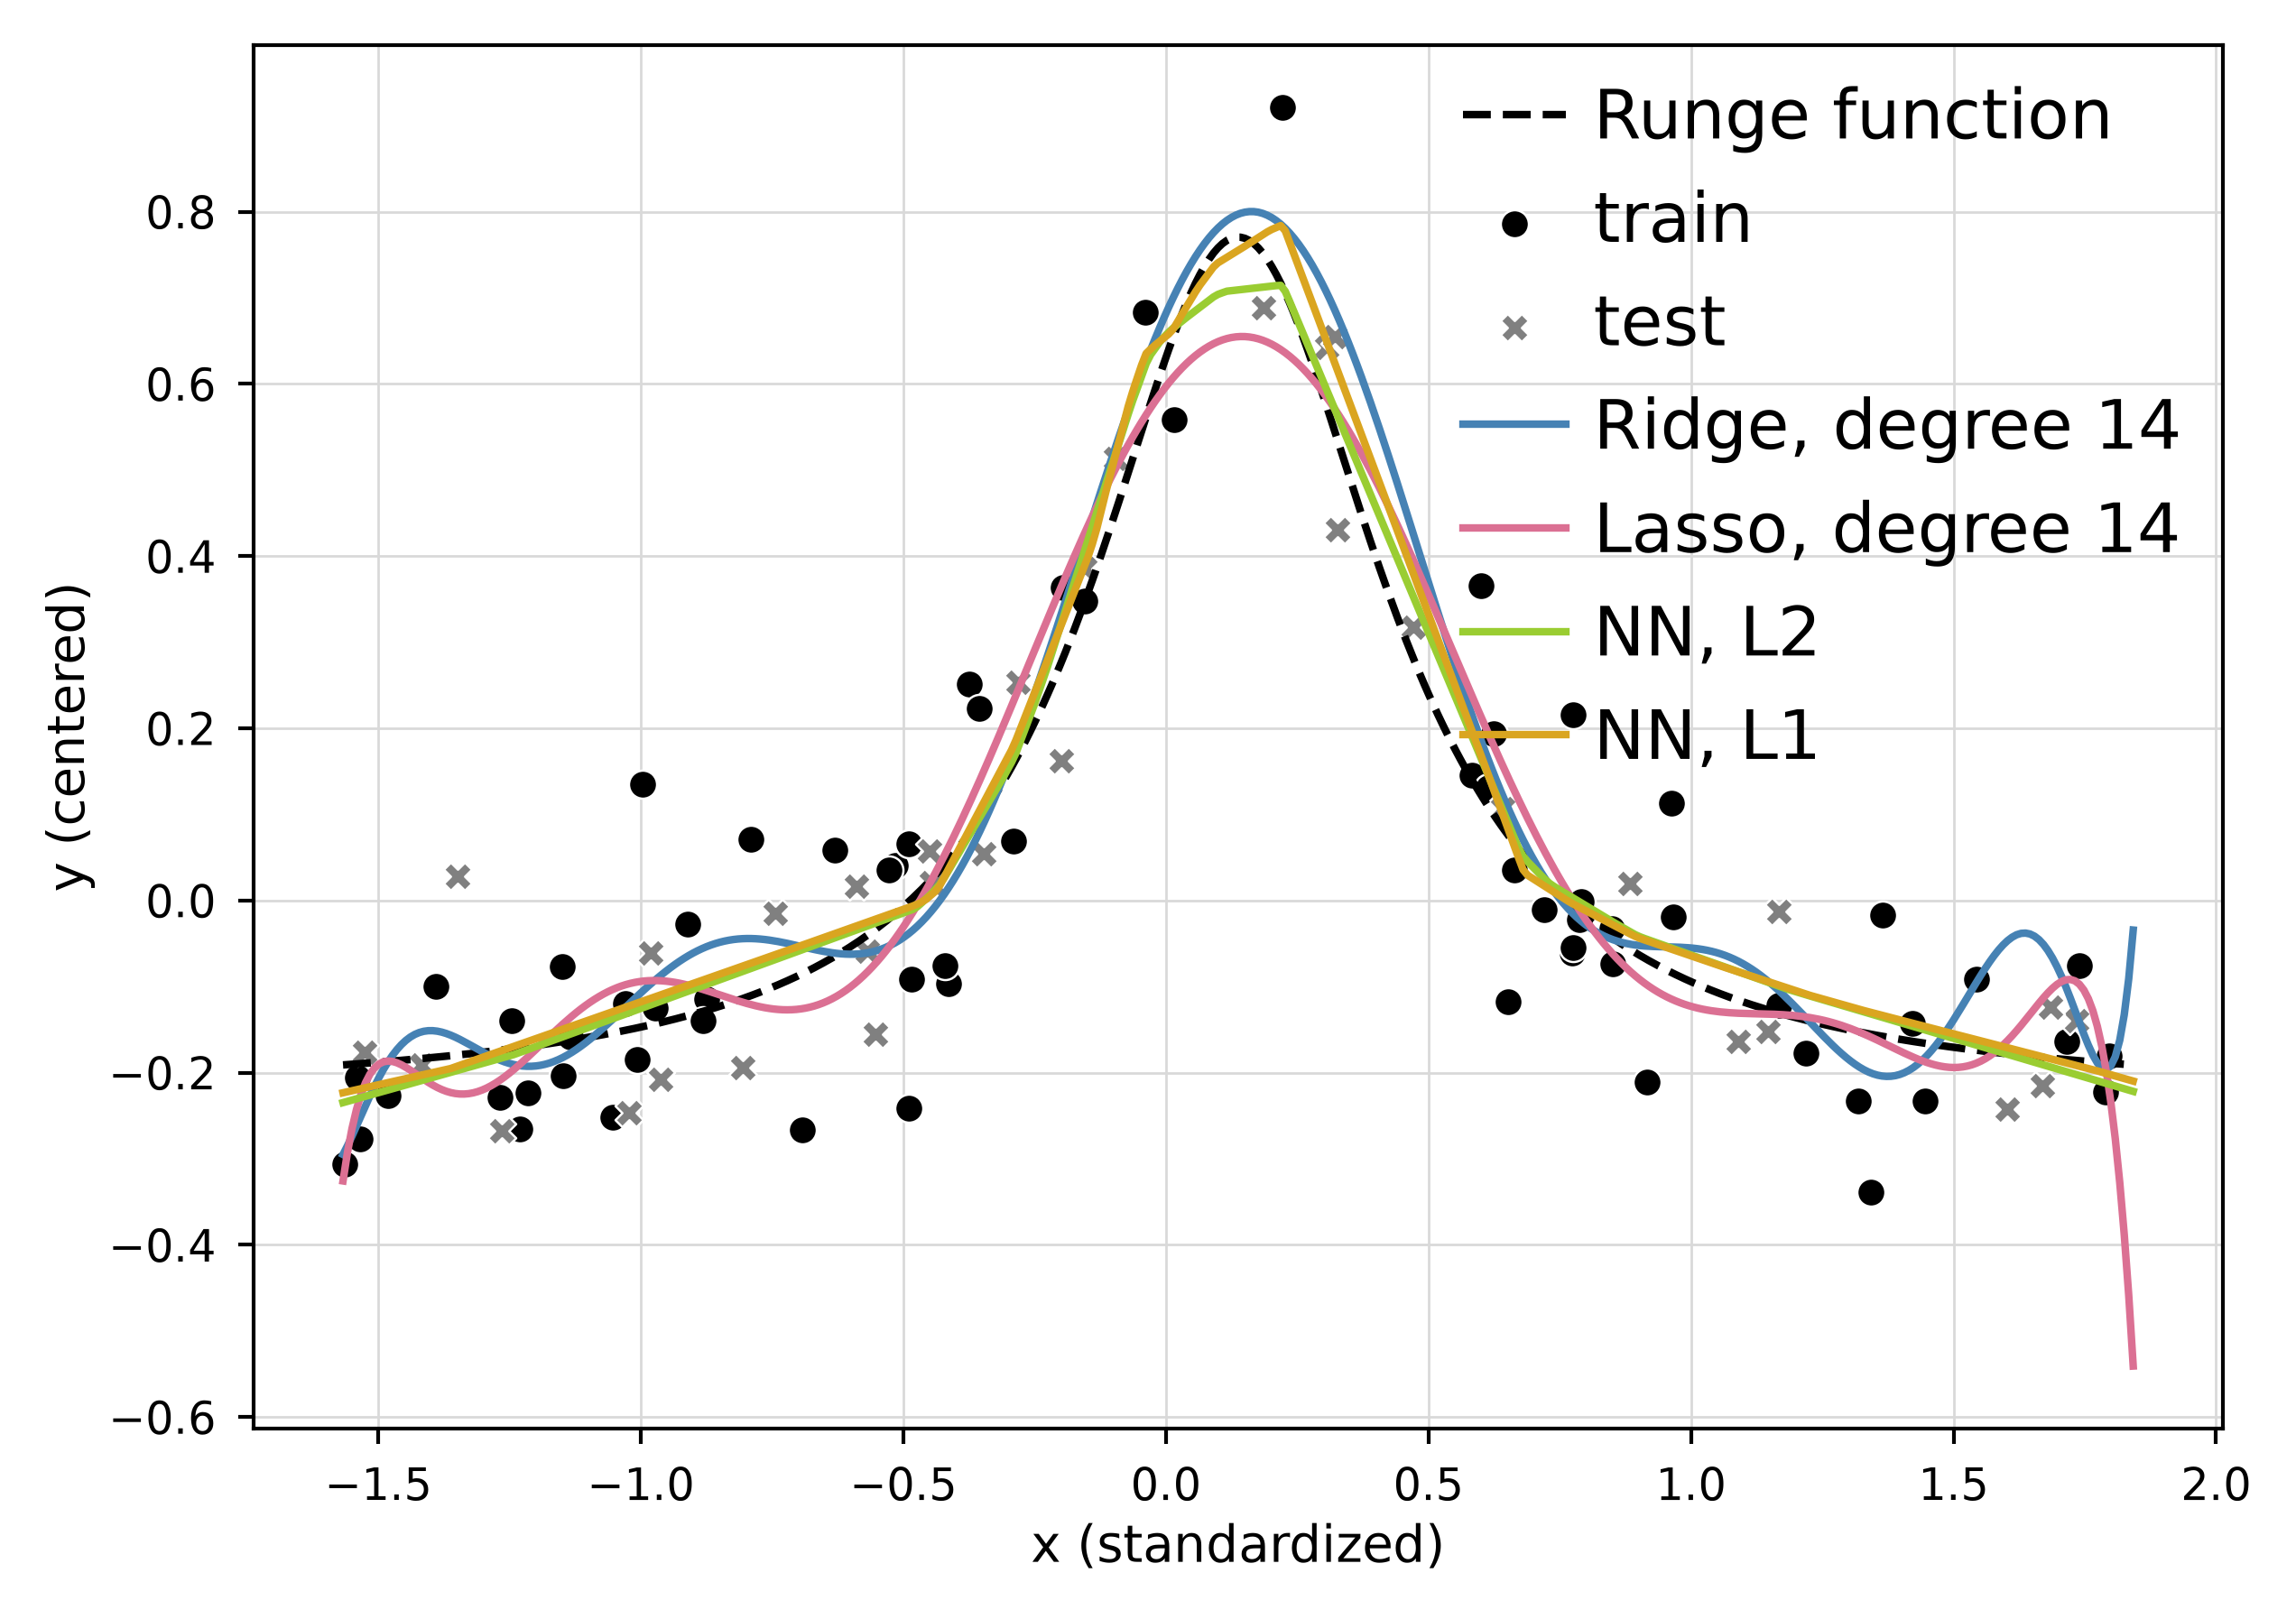

In [ ]:
ALPHAS_P1 = np.logspace(-8, 0, 6)
degrees = np.arange(1, MAX_DEGREE + 1)

def compute_ridge_lasso_cv():
    ridge = np.zeros((MAX_DEGREE, len(ALPHAS_P1)))
    lasso = np.zeros_like(ridge)
    for j, alpha in enumerate(ALPHAS_P1):
        ridge[:, j] = u.k_fold_degrees(runge_X_train, runge_y_train, K,
                                       Ridge(alpha=alpha), maxdegree=MAX_DEGREE)
        lasso[:, j] = u.k_fold_degrees(runge_X_train, runge_y_train, K,
                                       Lasso(alpha=alpha, max_iter=100_000), maxdegree=MAX_DEGREE)
    return {"ridge": ridge, "lasso": lasso}

ridge_lasso_cv = u.cached_arrays(RESULTS_PATH / "d_ridge_lasso_cv.npz", compute_ridge_lasso_cv, RERUN)

# For each method: pick (degree, alpha) by CV, refit on training set, evaluate once on test set
benchmarks = {"OLS": {"degree": best_degree, "alpha": 0.0, "model": ols_model, "test_mse": ols_test_mse}}
for name, cv_mse, Model, extra in [("Ridge", ridge_lasso_cv["ridge"], Ridge, {}),
                                   ("Lasso", ridge_lasso_cv["lasso"], Lasso, {"max_iter": 100_000})]:
    best = u.best_cell(cv_mse, degree=degrees, alpha=ALPHAS_P1)
    model = u.poly_model(int(best["degree"]), Model(alpha=best["alpha"], **extra)).fit(runge_X_train, runge_y_train)
    benchmarks[name] = {"degree": int(best["degree"]), "alpha": best["alpha"], "model": model,
                        "test_mse": mse_score(runge_y_test, model.predict(runge_X_test))}

# ==============================================================================

def retrain_penalized_nets(lam, gamma, seeds=SEEDS_D):
    '''Retrain on the whole training set, and return mean and std of the test MSE over seeds'''
    lam1, lam2 = lam
    test_scores, nets = [], []
    for seed in seeds:
        net = NeuralNetwork([1] + [ARCH_WIDTH] * ARCH_DEPTH + [1],
                            [ARCH_ACTIVATION] * ARCH_DEPTH + ["identity"],
                            "mse", lmbd1=lam1, lmbd2=lam2, seed=seed)
        with np.errstate(all="ignore"):
            train(net, runge_X_train, runge_Y_train, method="rmsprop", gamma=gamma,
                  epochs=EPOCHS_D, batch_size=10, seed=seed)
        test_scores.append(mse_score(runge_Y_test, net.predict(runge_X_test)))
        nets.append(net)
    return np.mean(test_scores), np.std(test_scores), nets[0]

best_unpenalized = u.best_cell(val_mse_mean_d[0, 0], gamma=GAMMAS_D)    # lambda = 0 row
nn_settings = {"NN, no penalty": ((0.0, 0.0), best_unpenalized["gamma"]),
               "NN, L2": ((0.0, best_penalized["l2"]["lam"]), best_penalized["l2"]["gamma"]),
               "NN, L1": ((best_penalized["l1"]["lam"], 0.0), best_penalized["l1"]["gamma"])}
nn_results = {name: retrain_penalized_nets(lam, gamma) for name, (lam, gamma) in nn_settings.items()}

print(f"{'model':<22}{'degree':>7}{'lambda':>10}{'test MSE':>20}")
for name, info in benchmarks.items():
    print(f"{name + ' (Project 1)':<22}{info['degree']:>7}{info['alpha']:>10.1e}{info['test_mse']:>20.4f}")
for name, (lam, _) in nn_settings.items():
    mean, std, _ = nn_results[name]
    print(f"{name:<22}{'-':>7}{max(lam):>10.1e}{mean:>12.4f} ± {std:.4f}")
    
# ==============================================================================

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(grid_x_std, runge_true_curve, "k--", label="Runge function")
sns.scatterplot(x=runge_x_train, y=runge_y_train, s=20, color="k", label="train", ax=ax)
sns.scatterplot(x=runge_x_test, y=runge_y_test, s=20, color="gray", marker="X", label="test", ax=ax)
for name in ("Ridge", "Lasso"):
    info = benchmarks[name]
    sns.lineplot(x=grid_x_std, y=info["model"].predict(grid_x_std.reshape(-1, 1)),
                 label=f"{name}, degree {info['degree']}", ax=ax)
for name in ("NN, L2", "NN, L1"):
    sns.lineplot(x=grid_x_std, y=nn_results[name][2].predict(to_column(grid_x_std)).ravel(),
                 label=name, ax=ax)
ax.set(xlabel="x (standardized)", ylabel="y (centered)")
ax.legend(loc="upper right", fontsize=11)
fig.savefig(FIGURES_PATH / "D-NN_vs_Ridge_Lasso.pdf")

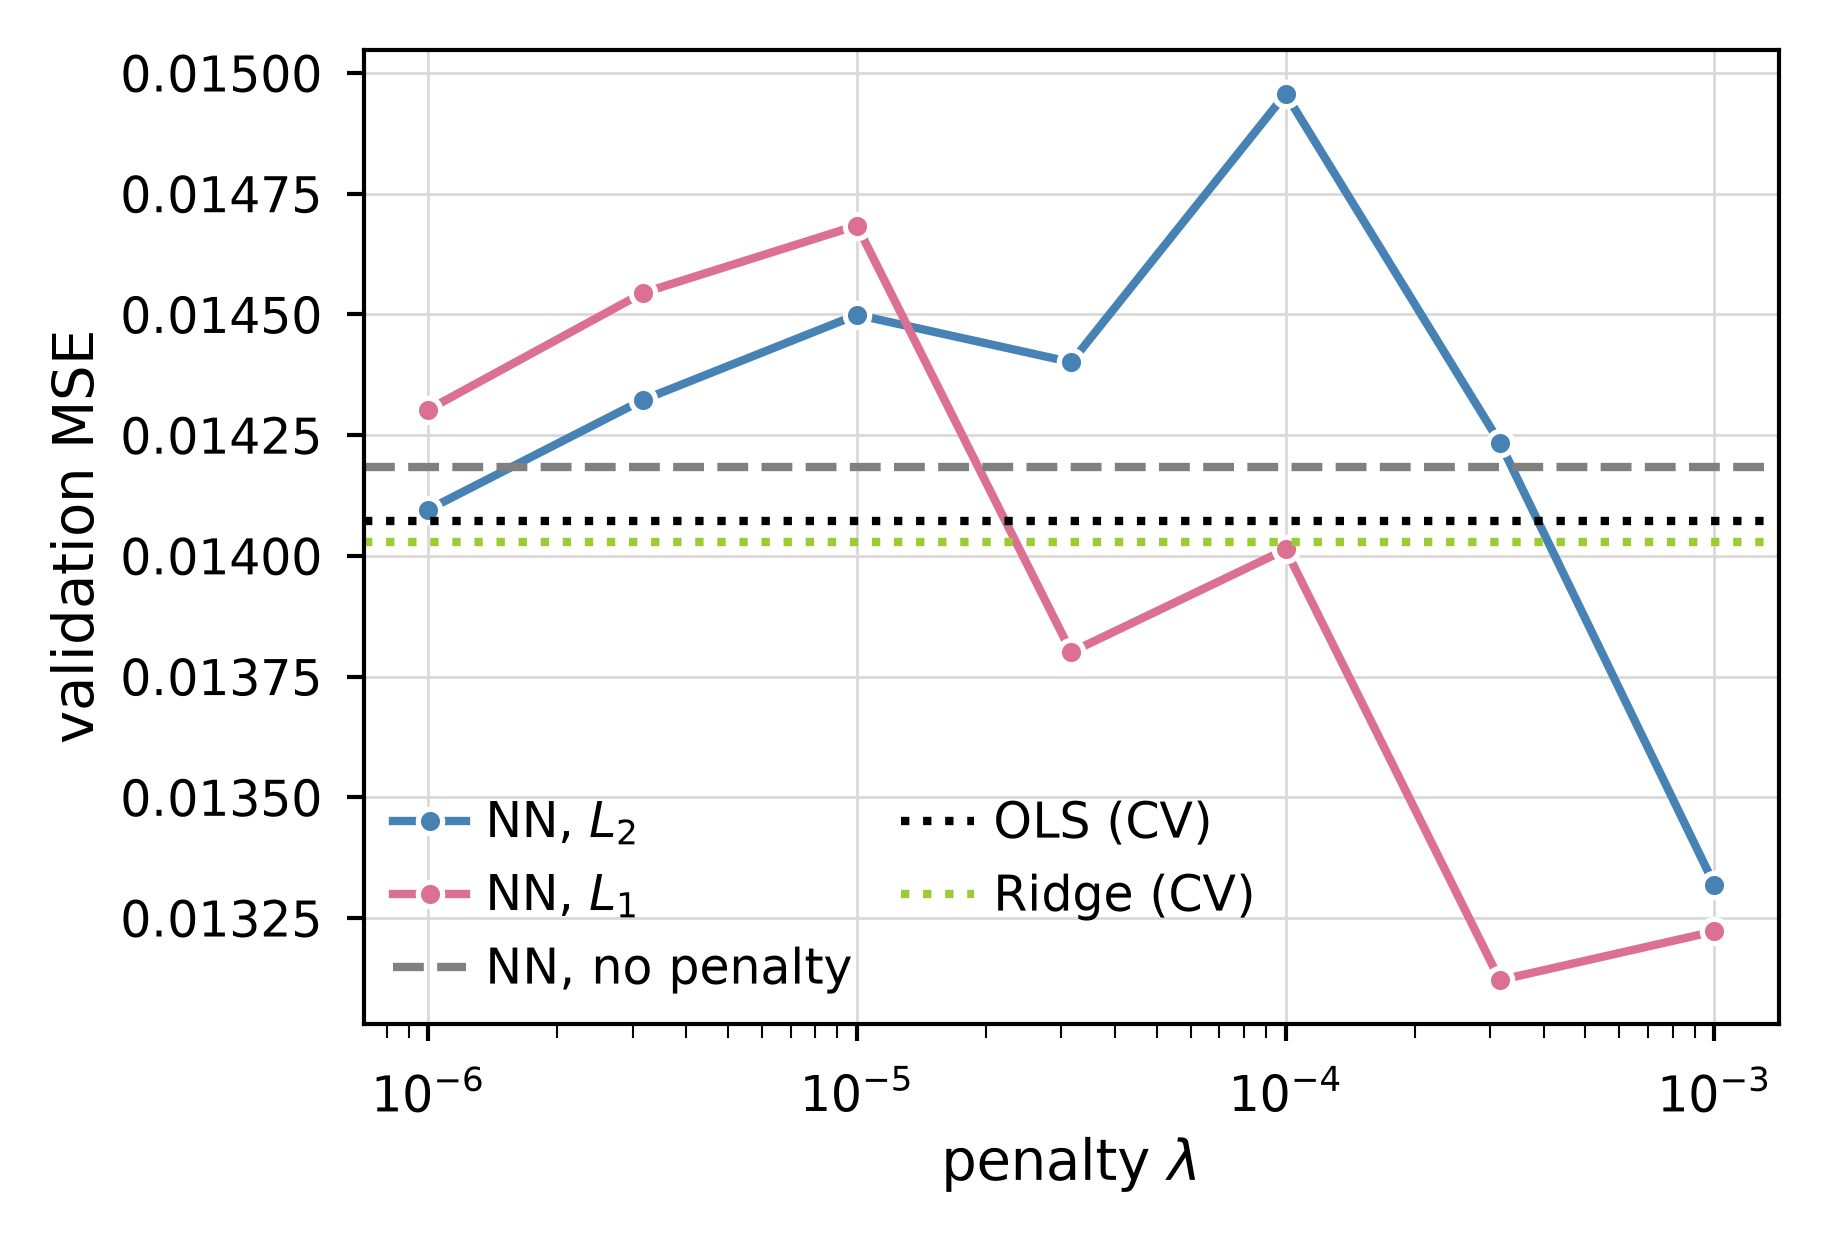

In [ ]:
def best_over_gamma(grid):
    return np.where(np.isfinite(grid), grid, np.inf).min(axis=1)

fig, ax = plt.subplots(figsize=(COL, 2.4))
for i, (norm, label) in enumerate([("l2", r"NN, $L_2$"), ("l1", r"NN, $L_1$")]):
    sns.lineplot(x=LAMBDAS[1:], y=best_over_gamma(val_mse_mean_d[i, 1:]), marker="o", label=label)
ax.axhline(best_over_gamma(val_mse_mean_d[0, :1])[0], color="0.5", ls="--", label="NN, no penalty")
ax.axhline(best_ols["value"], color="k", ls=":", label="OLS (CV)")
ax.axhline(ridge_lasso_cv["ridge"].min(), color="C2", ls=":", label="Ridge (CV)")
ax.set(xscale="log", xlabel=r"penalty $\lambda$", ylabel="validation MSE")
ax.legend(ncol=2)
fig.savefig(FIGURES_PATH / "D-lambda_curve.pdf")

<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part e)** Classification analysis

</div>

Load mnist dataset, scaled and centered. Split into train, val, and test sets.

In [ ]:
x_train, y_train, x_test, y_test = load_mnist(DATA_PATH)
x_fit, x_val, y_fit, y_val = train_val_split(x_train, y_train, val_size=0.25, seed=SEED, stratify=False)
Y_fit, Y_val, Y_train = one_hot(y_fit), one_hot(y_val), one_hot(y_train)    # train needs (n, 10)

print("Train: ", x_fit.shape, y_fit.shape)
print("Val:   ", x_val.shape, y_val.shape)
print("Test:  ", x_test.shape, y_test.shape)

Train:  (45000, 784) (45000,)
Val:    (15000, 784) (15000,)
Test:   (10000, 784) (10000,)


Logistic regression.

To save the model from the run, we need to save it in form of $W$ and $b$, such
that instead of predicting with `model.predict(x_test)`, we instead predict the
traditional way: $y_\mathrm{pred}=x_\mathrm{test}\cdot \boldsymbol{W}^\top + b$.

This has been tested against saving the model directly, and returns the same
accuracy.

In [ ]:
def compute_logistic_regression():
    model = LogisticRegression(solver="saga", max_iter=1000, random_state=42)
    model.fit(x_train, y_train)
    return {"coef": model.coef_, "intercept": model.intercept_} # shapes (10, 784) and (10,)

logreg = u.cached_arrays(RESULTS_PATH / "e_logreg_params.npz", compute_logistic_regression, RERUN)

logreg_scores = x_test @ logreg["coef"].T + logreg["intercept"]
logreg_predictions = np.argmax(logreg_scores, axis=1)
logreg_accuracy = accuracy(y_test, logreg_predictions)
print(f"Model Accuracy: {logreg_accuracy:.4f}")

Model Accuracy: 0.9257


Train one classifier on the fit set. Returns the network and its per-epoch history

In [ ]:
def accuracy_metric(net, X, Y_onehot):
    '''Accuracy of a net on X. Targets are one-hot because train needs them that way.'''
    return accuracy(np.argmax(Y_onehot, axis=1), np.argmax(net.predict(X), axis=1))


def run_one_mnist(activation, hidden, lam, gamma, epochs, batch_size, seed, method="adam"):
    '''
    activation : hidden-layer activation, e.g. "relu"
    hidden     : hidden layer sizes, e.g. (128, 64); () means no hidden layer (= logistic regression)
    lam        : (lambda1, lambda2) for the L1 and L2 penalties
    '''
    l1, l2 = lam
    sizes = [x_fit.shape[1], *hidden, 10]       # 10 output nodes
    acts = [activation] * len(hidden) + ["softmax"]
    net = NeuralNetwork(sizes, acts, "cross_entropy", lmbd1=l1, lmbd2=l2, seed=seed)
    history = train(net, x_fit, Y_fit, method=method, gamma=gamma, epochs=epochs,
                    batch_size=batch_size, seed=seed, X_val=x_val, Y_val=Y_val,
                    metric=accuracy_metric)
    return net, history

Learning curves: No hidden layer (= logistic regression) vs. one hidden layer

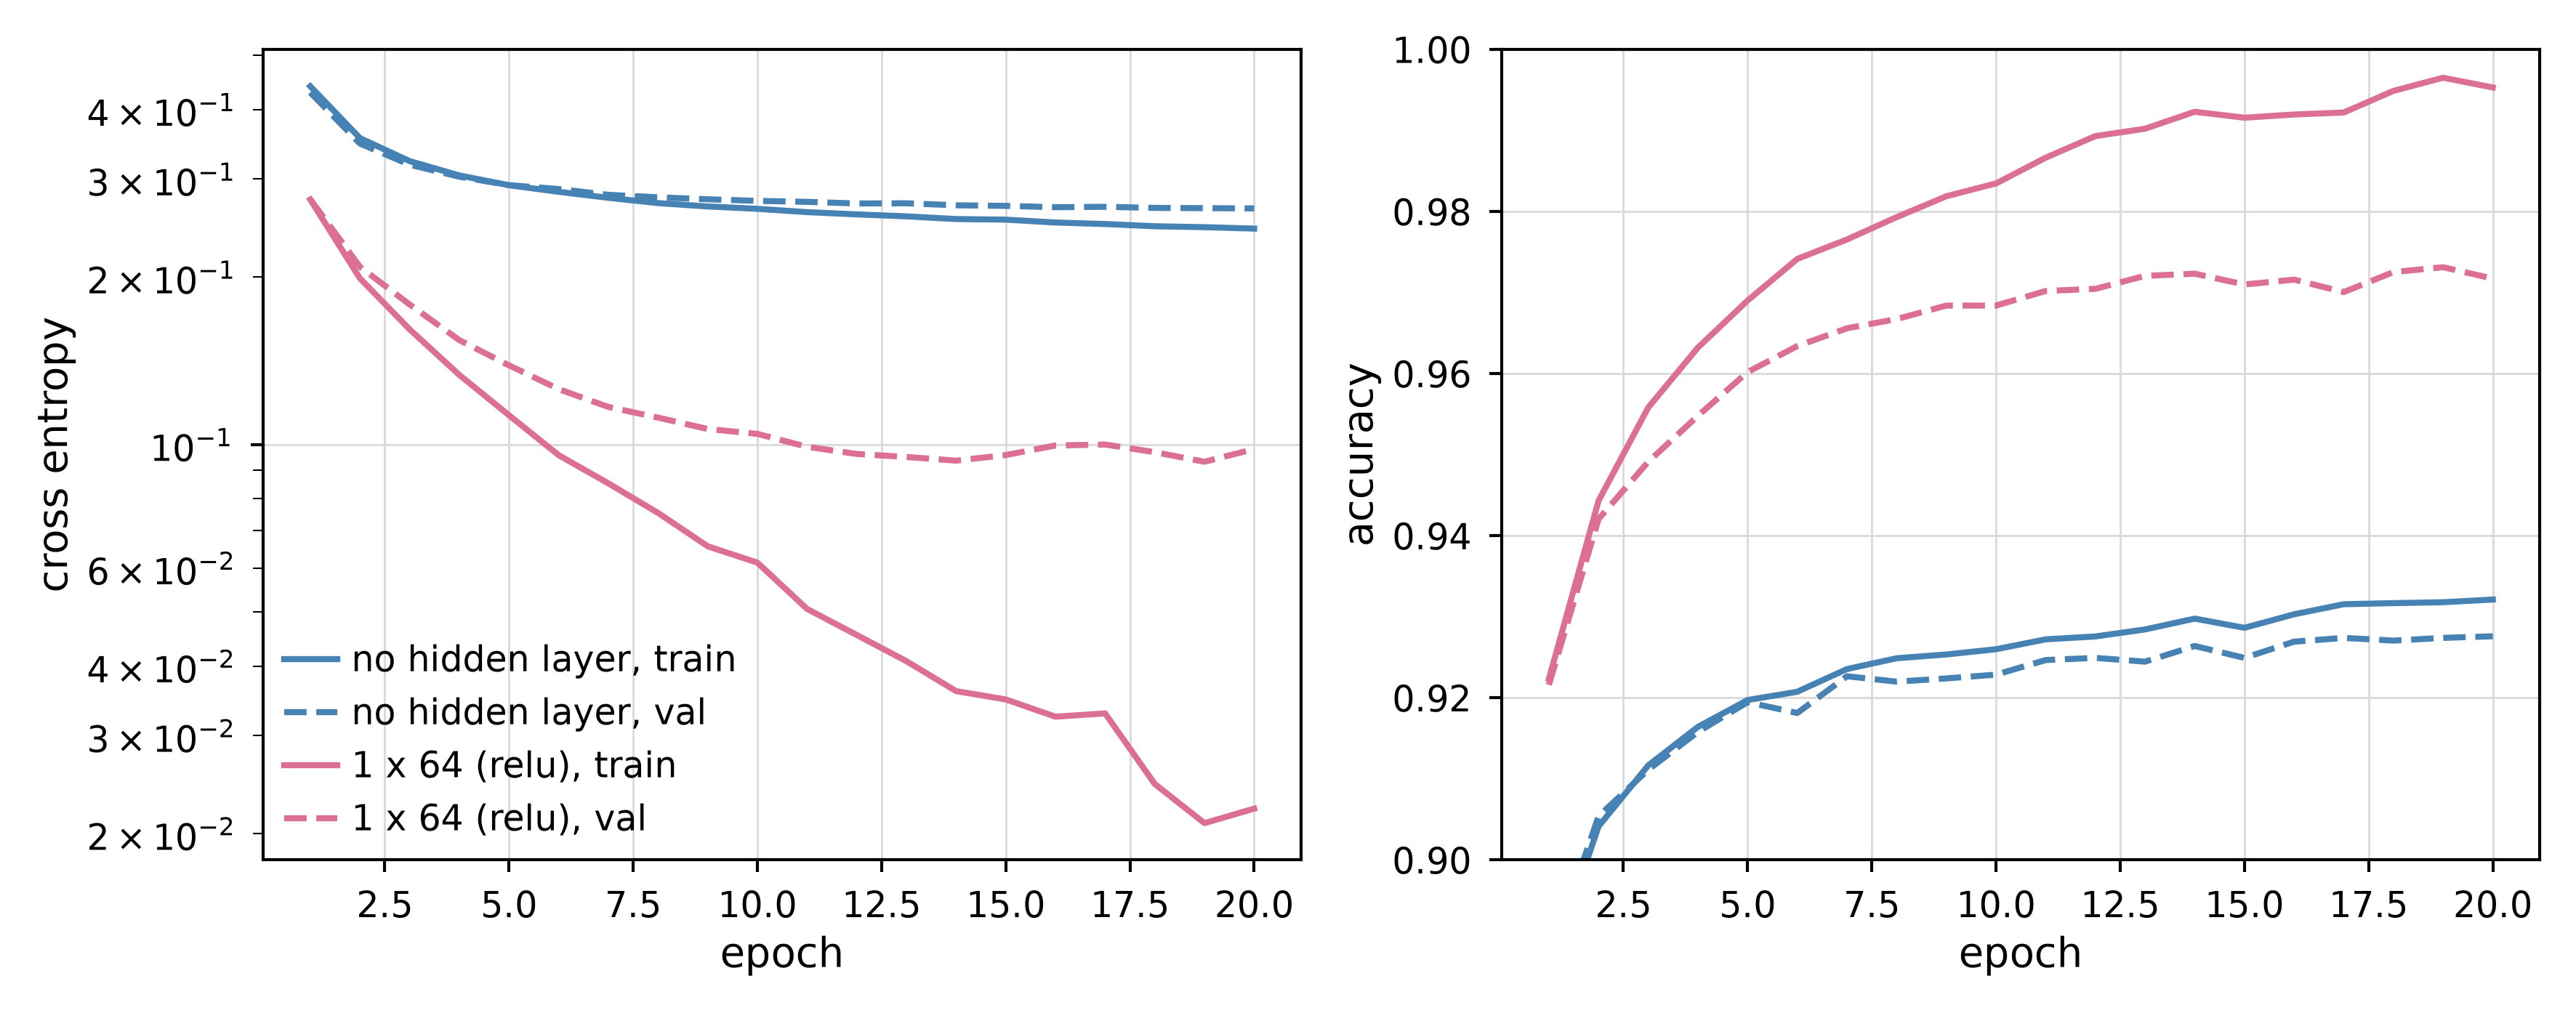

In [ ]:
EPOCHS_BASE, BATCH_E = 20, 128
BASELINES = {"no hidden layer": ((), "relu"),   # label: (hidden, activation)
             "1 x 64 (relu)": ((64,), "relu")}

def compute_baseline_curves():
    names = ("train_cost", "val_cost", "train_accuracy", "val_accuracy")
    curves = {name: np.zeros((len(BASELINES), EPOCHS_BASE)) for name in names}
    for i, (hidden, activation) in enumerate(BASELINES.values()):
        _, history = run_one_mnist(activation, hidden, (0.0, 0.0), 1e-3, 
                                   EPOCHS_BASE, BATCH_E, SEED)
        curves["train_cost"][i], curves["val_cost"][i] = history["train_cost"], history["val_cost"]
        curves["train_accuracy"][i], curves["val_accuracy"][i] = history["train_metric"], history["val_metric"]
    return curves

baseline = u.cached_arrays(RESULTS_PATH / "e_baseline_curves.npz", compute_baseline_curves, RERUN)

epochs = np.arange(1, EPOCHS_BASE + 1)
colors = ["steelblue", "palevioletred"]
fig, axes = plt.subplots(1, 2, figsize=(7, 2.7))
for i, label in enumerate(BASELINES):
    color = colors[i]
    for split, linestyle in (("train", "-"), ("val", "--")):
        axes[0].plot(epochs, baseline[f"{split}_cost"][i], linestyle, color=color, label=f"{label}, {split}")
        axes[1].plot(epochs, baseline[f"{split}_accuracy"][i], linestyle, color=color, label=f"{label}, {split}")
axes[0].set(xlabel="epoch", ylabel="cross entropy", yscale="log")
axes[1].set(xlabel="epoch", ylabel="accuracy", ylim=(0.9, 1.0))
axes[0].legend(loc="lower left")
fig.savefig(FIGURES_PATH / "E-baseline_curves.pdf")

Validation accuracy per optimizer across learning rates on a reference network
(1 x 64, relu, no penalty). Mean and std of 3 seeds

rmsprop, learning rate 1.9e-03


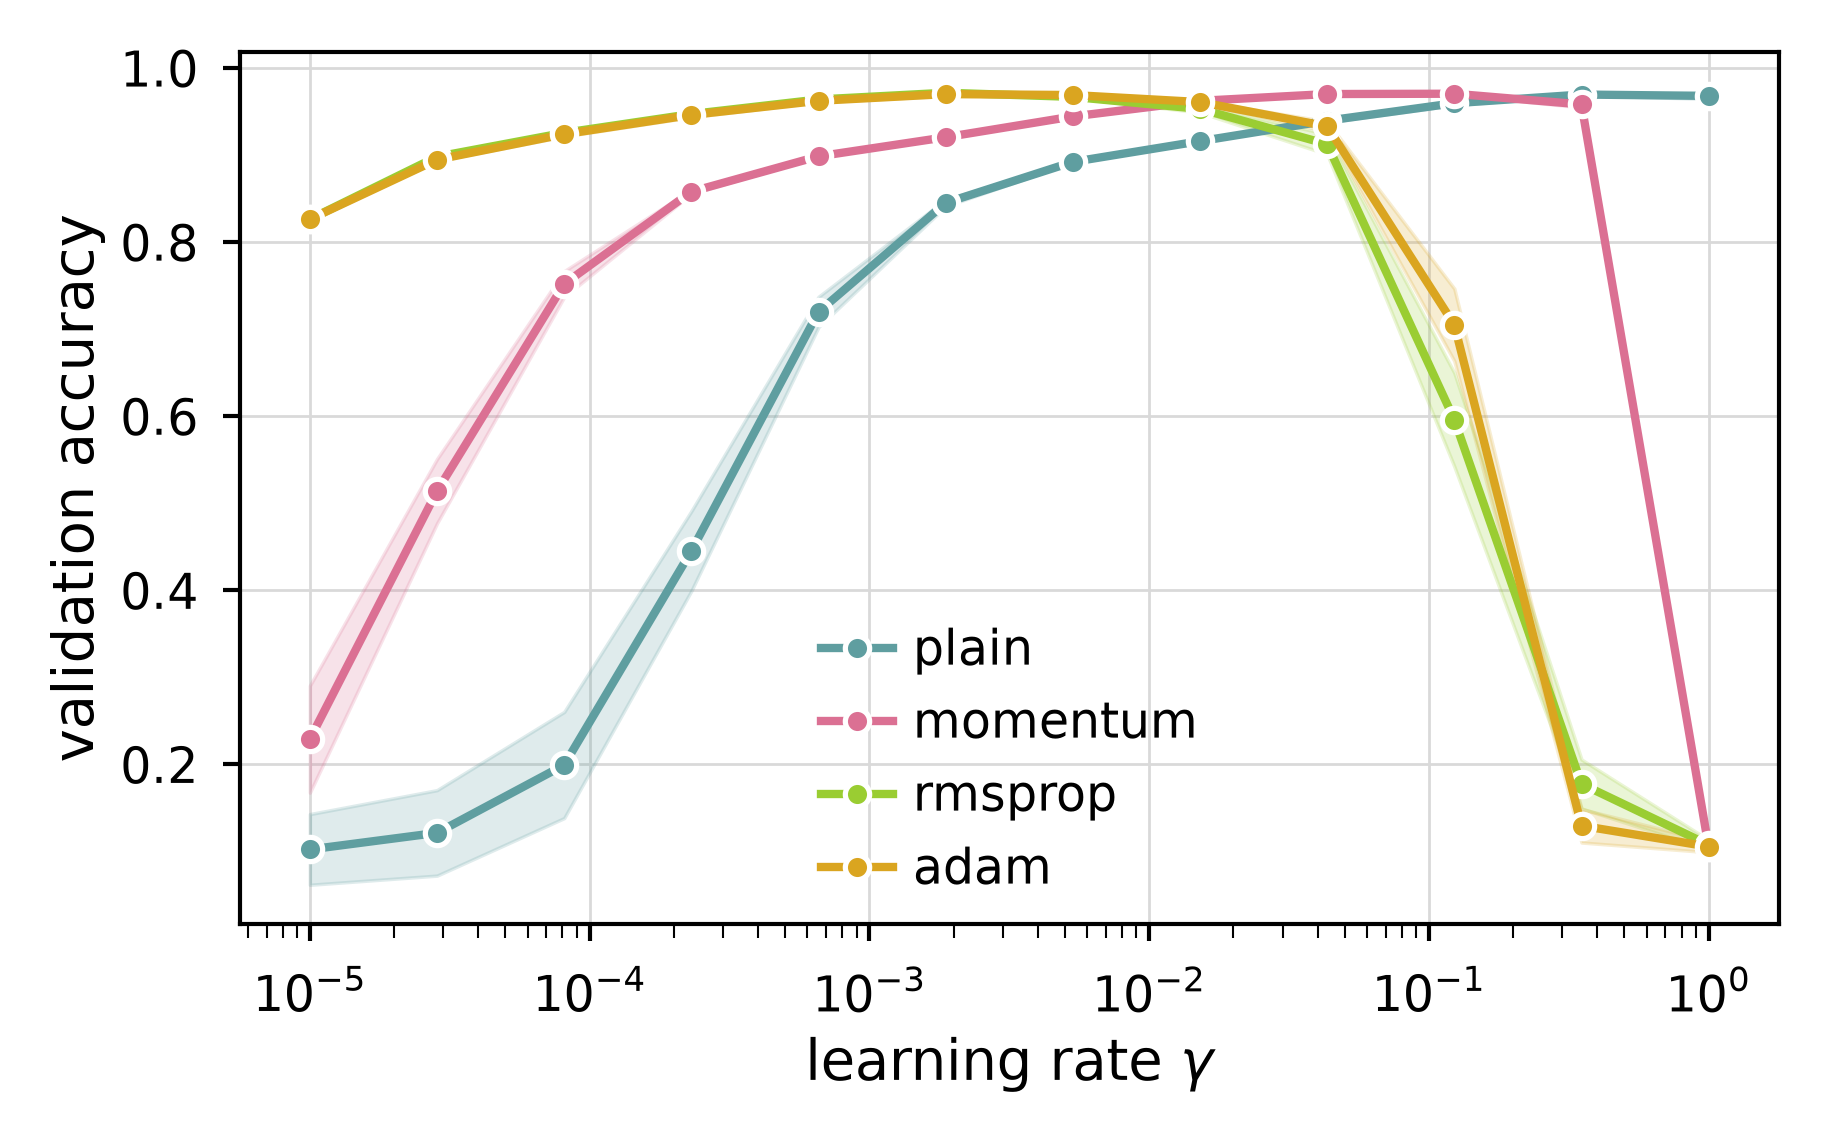

In [ ]:
SEEDS_E, EPOCHS_E = [0, 1, 2], 10
REF_ACTIVATION, REF_HIDDEN = "relu", (64,)
METHODS_E = ["plain", "momentum", "rmsprop", "adam"]
GAMMAS_OPT = np.geomspace(1e-5, 1.0, 12)    # wide: diverged run are fine

def compute_optimizer_sweep():
    shape = (len(METHODS_E), len(GAMMAS_OPT), len(SEEDS_E))
    val_accuracy = np.full(shape, np.nan)
    for m, g, s in np.ndindex(shape):
        with np.errstate(all="ignore"):
            _, history = run_one_mnist(REF_ACTIVATION, REF_HIDDEN, (0.0, 0.0),
                                       GAMMAS_OPT[g], EPOCHS_E, BATCH_E,
                                       seed=SEEDS_E[s], method=METHODS_E[m])
        val_accuracy[m, g, s] = history["val_metric"][-1]
    return {"val_accuracy": val_accuracy}

optimizer = u.cached_arrays(RESULTS_PATH / "e_optimizer.npz", compute_optimizer_sweep, RERUN)
optimizer_accuracy_mean = optimizer["val_accuracy"].mean(axis=-1)
optimizer_accuracy_std = optimizer["val_accuracy"].std(axis=-1)

best_optimizer = u.best_cell(optimizer_accuracy_mean, smallest=False,
                             method=METHODS_E, gamma=GAMMAS_OPT)
OPT_METHOD, OPT_GAMMA = best_optimizer["method"], best_optimizer["gamma"]
print(f"{OPT_METHOD}, learning rate {OPT_GAMMA:.1e}")

fig, ax = plt.subplots(figsize=(COL, 2.2))
colors = ["cadetblue", "palevioletred", "yellowgreen", "goldenrod"]
for m, (method, color) in enumerate(zip(METHODS_E, colors)):
    ax.fill_between(GAMMAS_OPT, optimizer_accuracy_mean[m] - optimizer_accuracy_std[m],
                    optimizer_accuracy_mean[m] + optimizer_accuracy_std[m],
                    color=color, alpha=0.2)
    sns.lineplot(x=GAMMAS_OPT, y=optimizer_accuracy_mean[m], marker="o", color=color,
                 label=method, ax=ax)
ax.set(xscale="log", xlabel=r"learning rate $\gamma$", ylabel="validation accuracy")
ax.legend()
fig.savefig(FIGURES_PATH / "E-optimizers.pdf")

Validation accuracy over depth and width. Every cell gets its best $\gamma$ from
a small grid around the optimizer's, so they're all judged at their own learning rate.

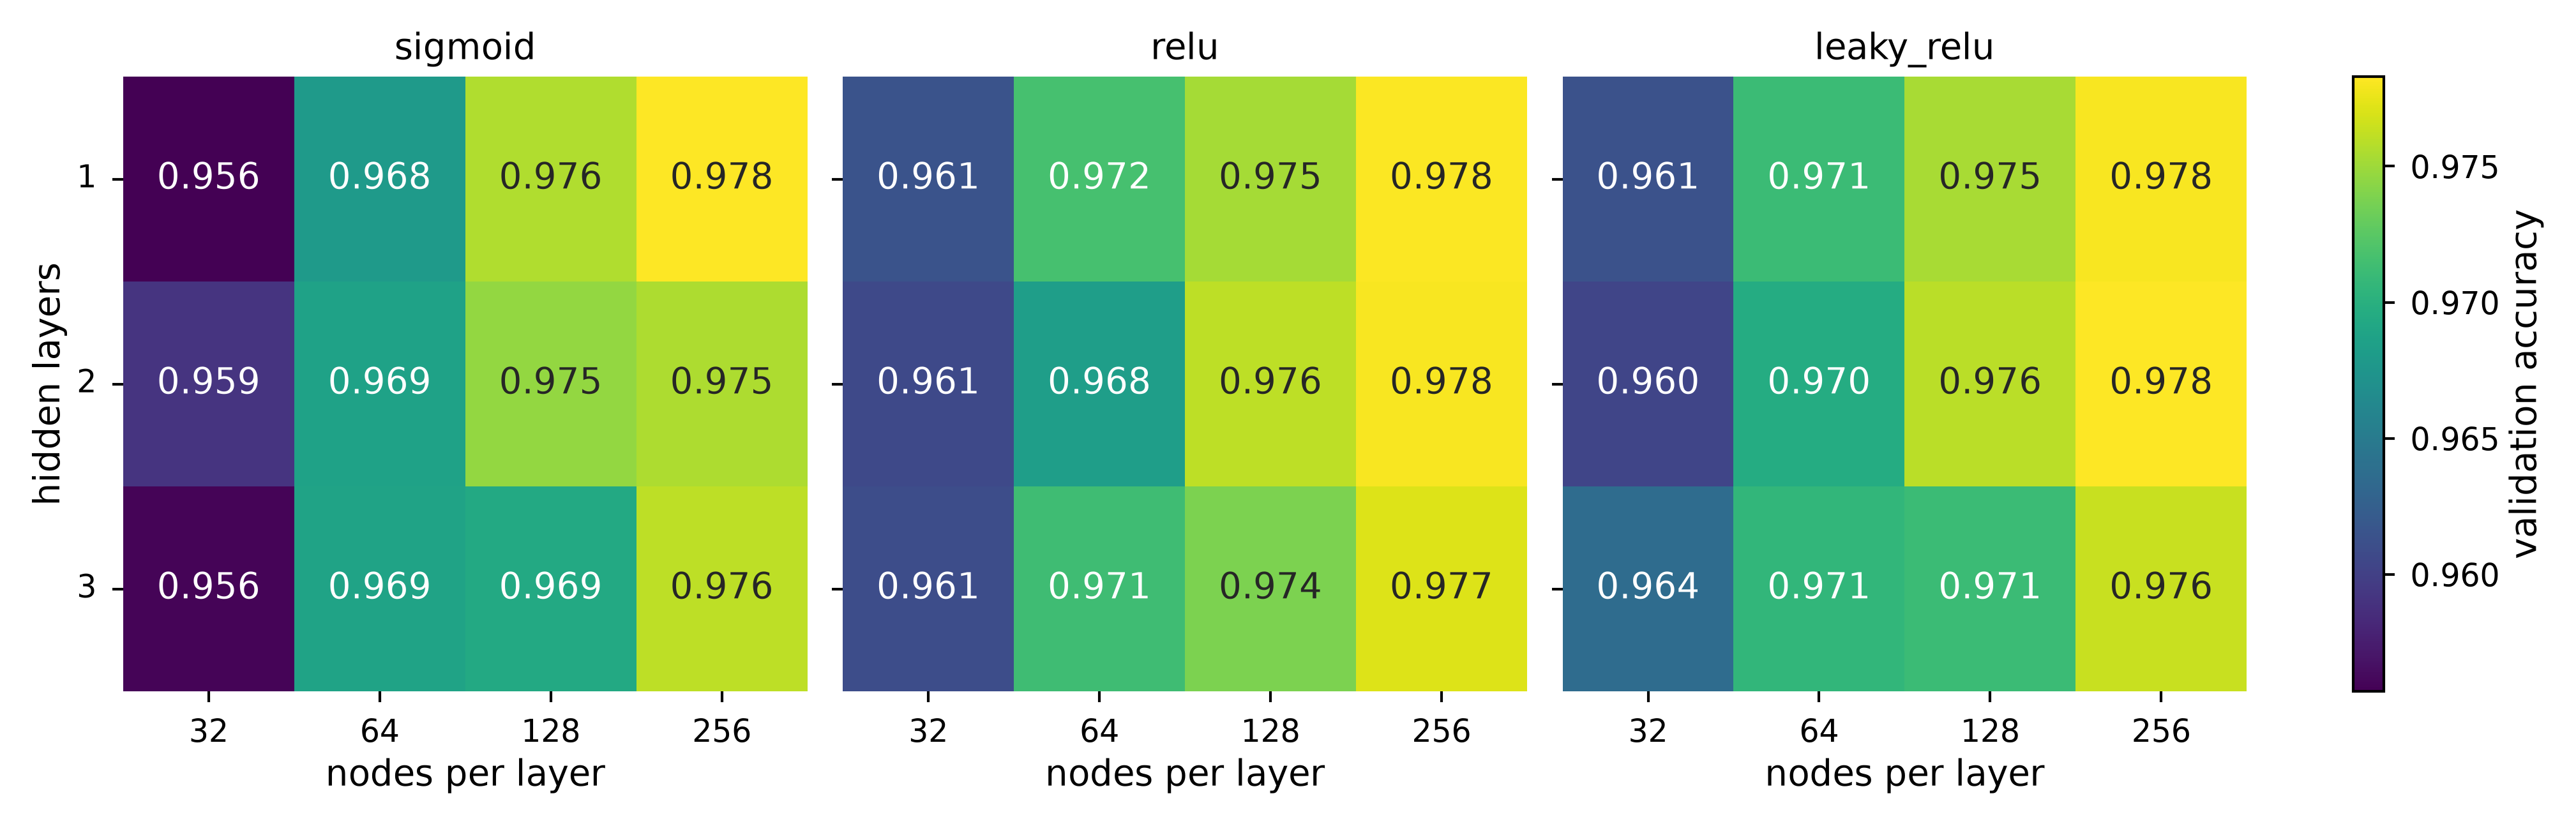

In [ ]:
ACTIVATIONS_E = ["sigmoid", "relu", "leaky_relu"]
DEPTHS_E = [1, 2, 3]
WIDTHS_E = [32, 64, 128, 256]
GAMMAS_ARCH = OPT_GAMMA * np.array([1/3, 1, 3])

def compute_architecture_sweep():
    shape = (len(ACTIVATIONS_E), len(DEPTHS_E), len(WIDTHS_E), len(GAMMAS_ARCH), len(SEEDS_E))
    val_accuracy = np.full(shape, np.nan)
    for a, d, w, g, s in np.ndindex(shape):
        hidden = (WIDTHS_E[w],) * DEPTHS_E[d]
        with np.errstate(all="ignore"):
            _, history = run_one_mnist(ACTIVATIONS_E[a], hidden, (0.0, 0.0),
                                       GAMMAS_ARCH[g], EPOCHS_E, BATCH_E,
                                       SEEDS_E[s], method=OPT_METHOD)
        val_accuracy[a, d, w, g, s] = history["val_metric"][-1]
    return {"val_accuracy": val_accuracy}

architecture = u.cached_arrays(RESULTS_PATH / "e_architectures.npz", compute_architecture_sweep, RERUN)
arch_accuracy_mean = architecture["val_accuracy"].mean(axis=-1)

# Best gamma in every (activation, depth, width) cell
finite = np.where(np.isfinite(arch_accuracy_mean), arch_accuracy_mean, -np.inf)
arch_accuracy_best = finite.max(axis=-1)
arch_accuracy_best[np.isinf(arch_accuracy_best)] = np.nan

best_architecture = {}
fig, axes = plt.subplots(1, 3, figsize=(8, 2.5), sharey=True)
for a, (ax, activation, grid) in enumerate(zip(axes, ACTIVATIONS_E, arch_accuracy_best)):
    sns.heatmap(grid, ax=ax, annot=True, fmt=".3f", cmap="viridis", cbar=False,
                vmin=np.nanmin(arch_accuracy_best), vmax=np.nanmax(arch_accuracy_best),
                xticklabels=WIDTHS_E, yticklabels=DEPTHS_E)
    ax.tick_params(axis="y", rotation=0)
    ax.set(title=activation, xlabel="nodes per layer")
    best_architecture[activation] = u.best_cell(arch_accuracy_mean[a], smallest=False,
                                                depth=DEPTHS_E, width=WIDTHS_E,
                                                gamma=GAMMAS_ARCH)
axes[0].set_ylabel("hidden layers")
fig.colorbar(axes[0].collections[0], ax=axes, label="validation accuracy")
fig.savefig(FIGURES_PATH / "E-architectures.pdf")

Pick out the best architecture from this run

In [ ]:
TOLERANCE = 0.001   # within ~1 standard error of the best cell
best_value = np.nanmax(arch_accuracy_best)

def n_weights(depth, width):
    return 784 * width + (depth - 1) * width * width + 10 * width

candidates = [(n_weights(DEPTHS_E[d], WIDTHS_E[w]), a, d, w)
              for a, d, w in np.ndindex(arch_accuracy_best.shape)
              if arch_accuracy_best[a, d, w] >= best_value - TOLERANCE]
_, a, d, w = min(candidates)        # fewest weights among the near-ties

ARCH_ACTIVATION, ARCH_DEPTH, ARCH_WIDTH = ACTIVATIONS_E[a], DEPTHS_E[d], WIDTHS_E[w]
ARCH_GAMMA = GAMMAS_ARCH[np.argmax(arch_accuracy_mean[a, d, w])]
print(f"{ARCH_ACTIVATION}, {ARCH_DEPTH} hidden layers x {ARCH_WIDTH} nodes, gamma {ARCH_GAMMA:.1e} "
      f"{len(candidates)} cells within {TOLERANCE} of the best")

sigmoid, 1 hidden layers x 256 nodes, gamma 5.6e-03 5 cells within 0.001 of the best


> **LLM note:** The following cell was aided by Claude (Level 2: Snippet).
>
> Per the previous cell's ucertain results, the first 4 lines in the following
> cell were generated by the LLM to get the cell started; the rest of the cell 
> was implemented independently, albeit with a suggestion from the LLM for what to look out for.

leaky_relu, 1 x 256, gamma 1.9e-03


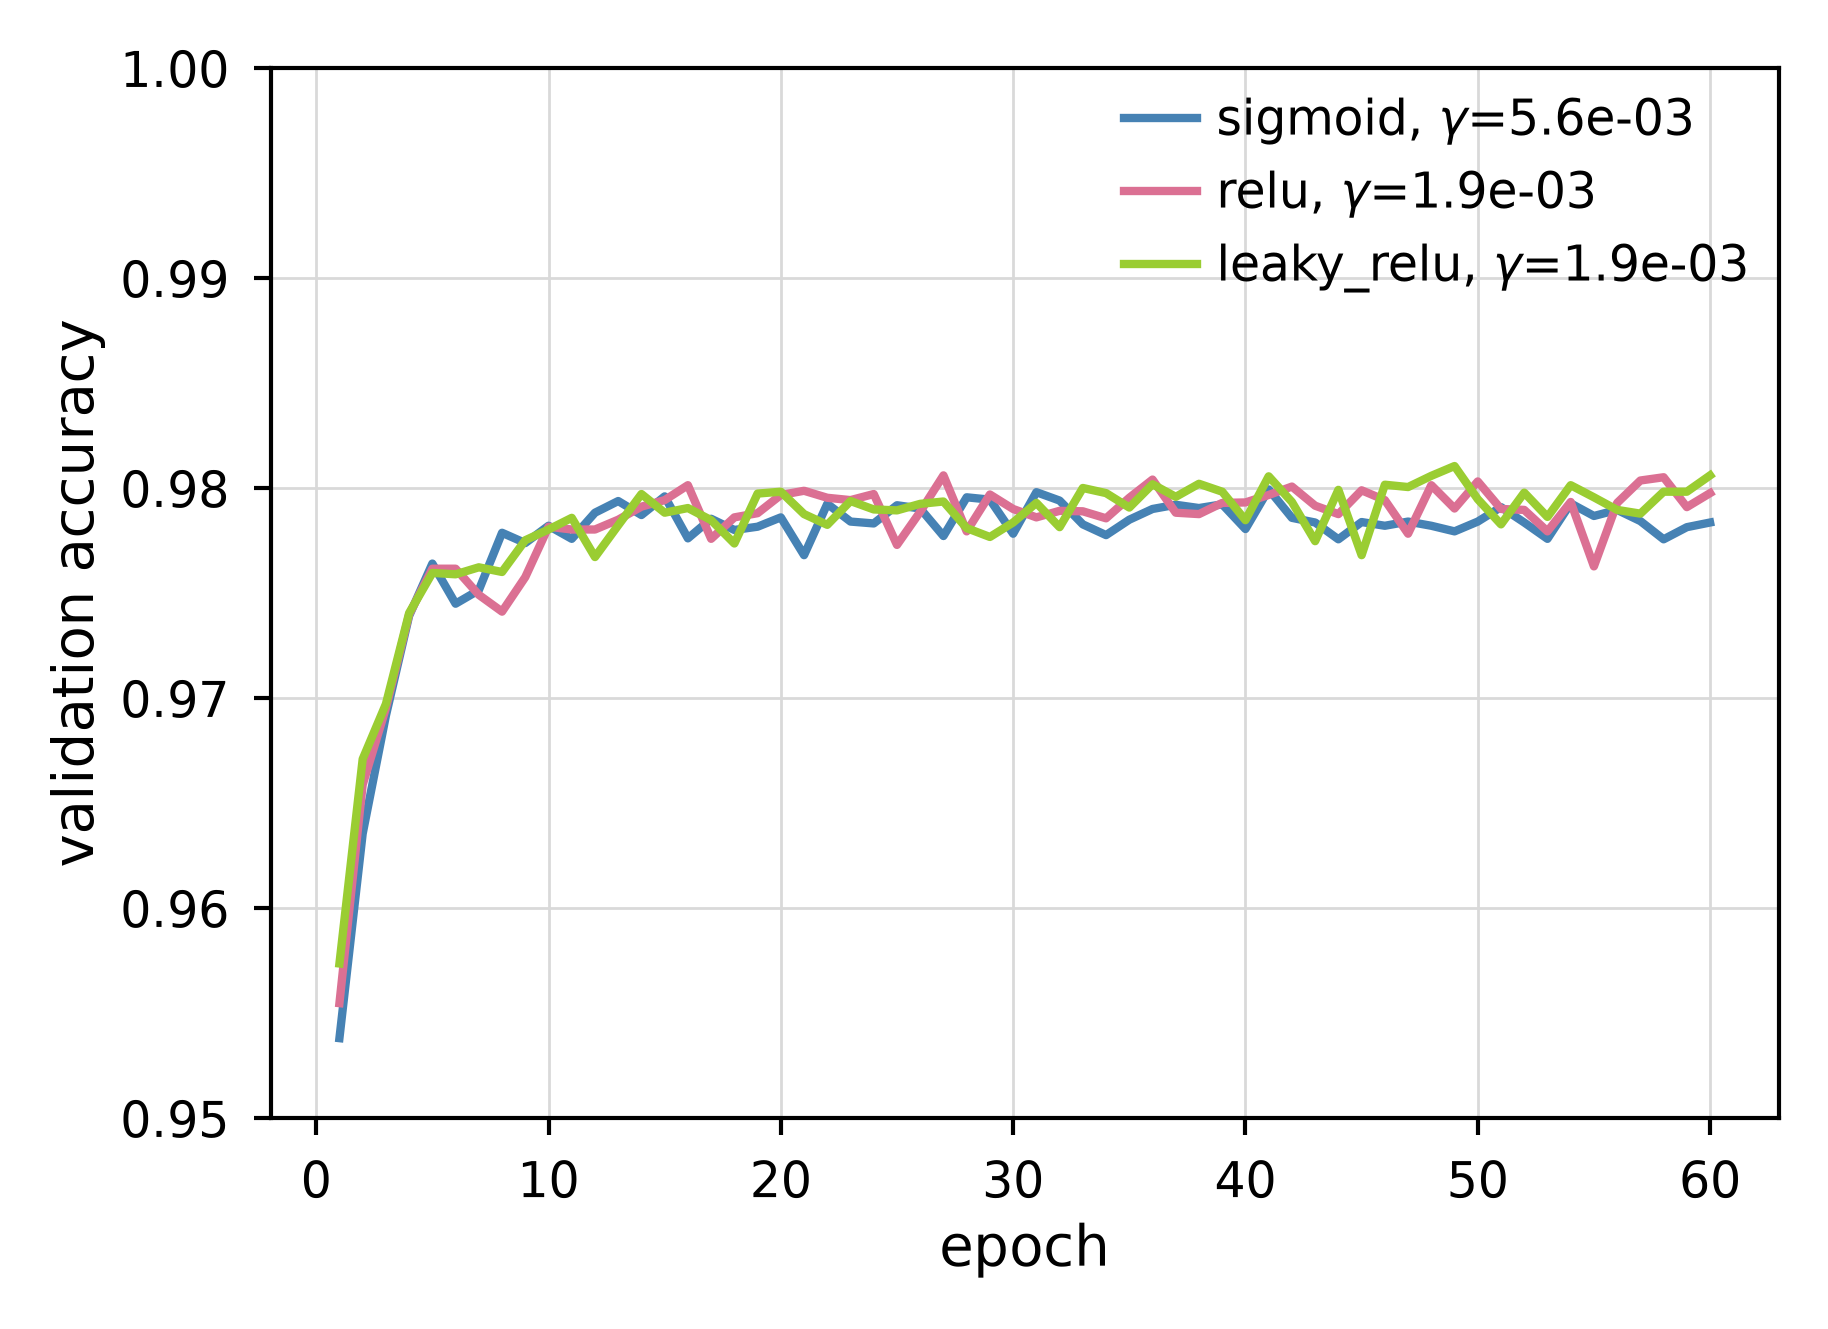

In [ ]:
min_weights = min(candidates)[0]
finalists = [(a, d, w) for n, a, d, w in candidates if n == min_weights]
finalist_gammas = [GAMMAS_ARCH[np.argmax(arch_accuracy_mean[a, d, w])] for a, d, w in finalists]
EPOCHS_LONG = 60

def compute_finalist_curves():
    val_accuracy = np.zeros((len(finalists), len(SEEDS_E), EPOCHS_LONG))
    for f, (a, d, w) in enumerate(finalists):
        for s, seed in enumerate(SEEDS_E):
            _, history = run_one_mnist(ACTIVATIONS_E[a], (WIDTHS_E[w],) * DEPTHS_E[d], (0.0, 0.0),
                                       finalist_gammas[f], EPOCHS_LONG, BATCH_E, seed,
                                       method=OPT_METHOD)
            val_accuracy[f, s] = history["val_metric"]
    return {"val_accuracy": val_accuracy}

finalist_curves = u.cached_arrays(RESULTS_PATH / "finalist_curves.npz", compute_finalist_curves, RERUN)
finalist_mean = finalist_curves["val_accuracy"].mean(axis=1)

fig, ax = plt.subplots()
for f, (a, d, w) in enumerate(finalists):
    sns.lineplot(x=np.arange(1, EPOCHS_LONG + 1), y=finalist_mean[f], ax=ax,
                 label=f"{ACTIVATIONS_E[a]}, $\\gamma$={finalist_gammas[f]:.1e}")
ax.set(xlabel="epoch", ylabel="validation accuracy", ylim=(0.95, 1.0))
fig.savefig(FIGURES_PATH / "E-finalists.pdf")

best_f = int(np.argmax(finalist_mean.max(axis=1)))
a, d, w = finalists[best_f]
ARCH_ACTIVATION, ARCH_DEPTH, ARCH_WIDTH = ACTIVATIONS_E[a], DEPTHS_E[d], WIDTHS_E[w]
ARCH_GAMMA = finalist_gammas[best_f]
print(f"{ARCH_ACTIVATION}, {ARCH_DEPTH} x {ARCH_WIDTH}, gamma {ARCH_GAMMA:.1e}")

Batch size x $\gamma$ sweep

batch size 256, gamma 1.9e-03, val acc 0.9779


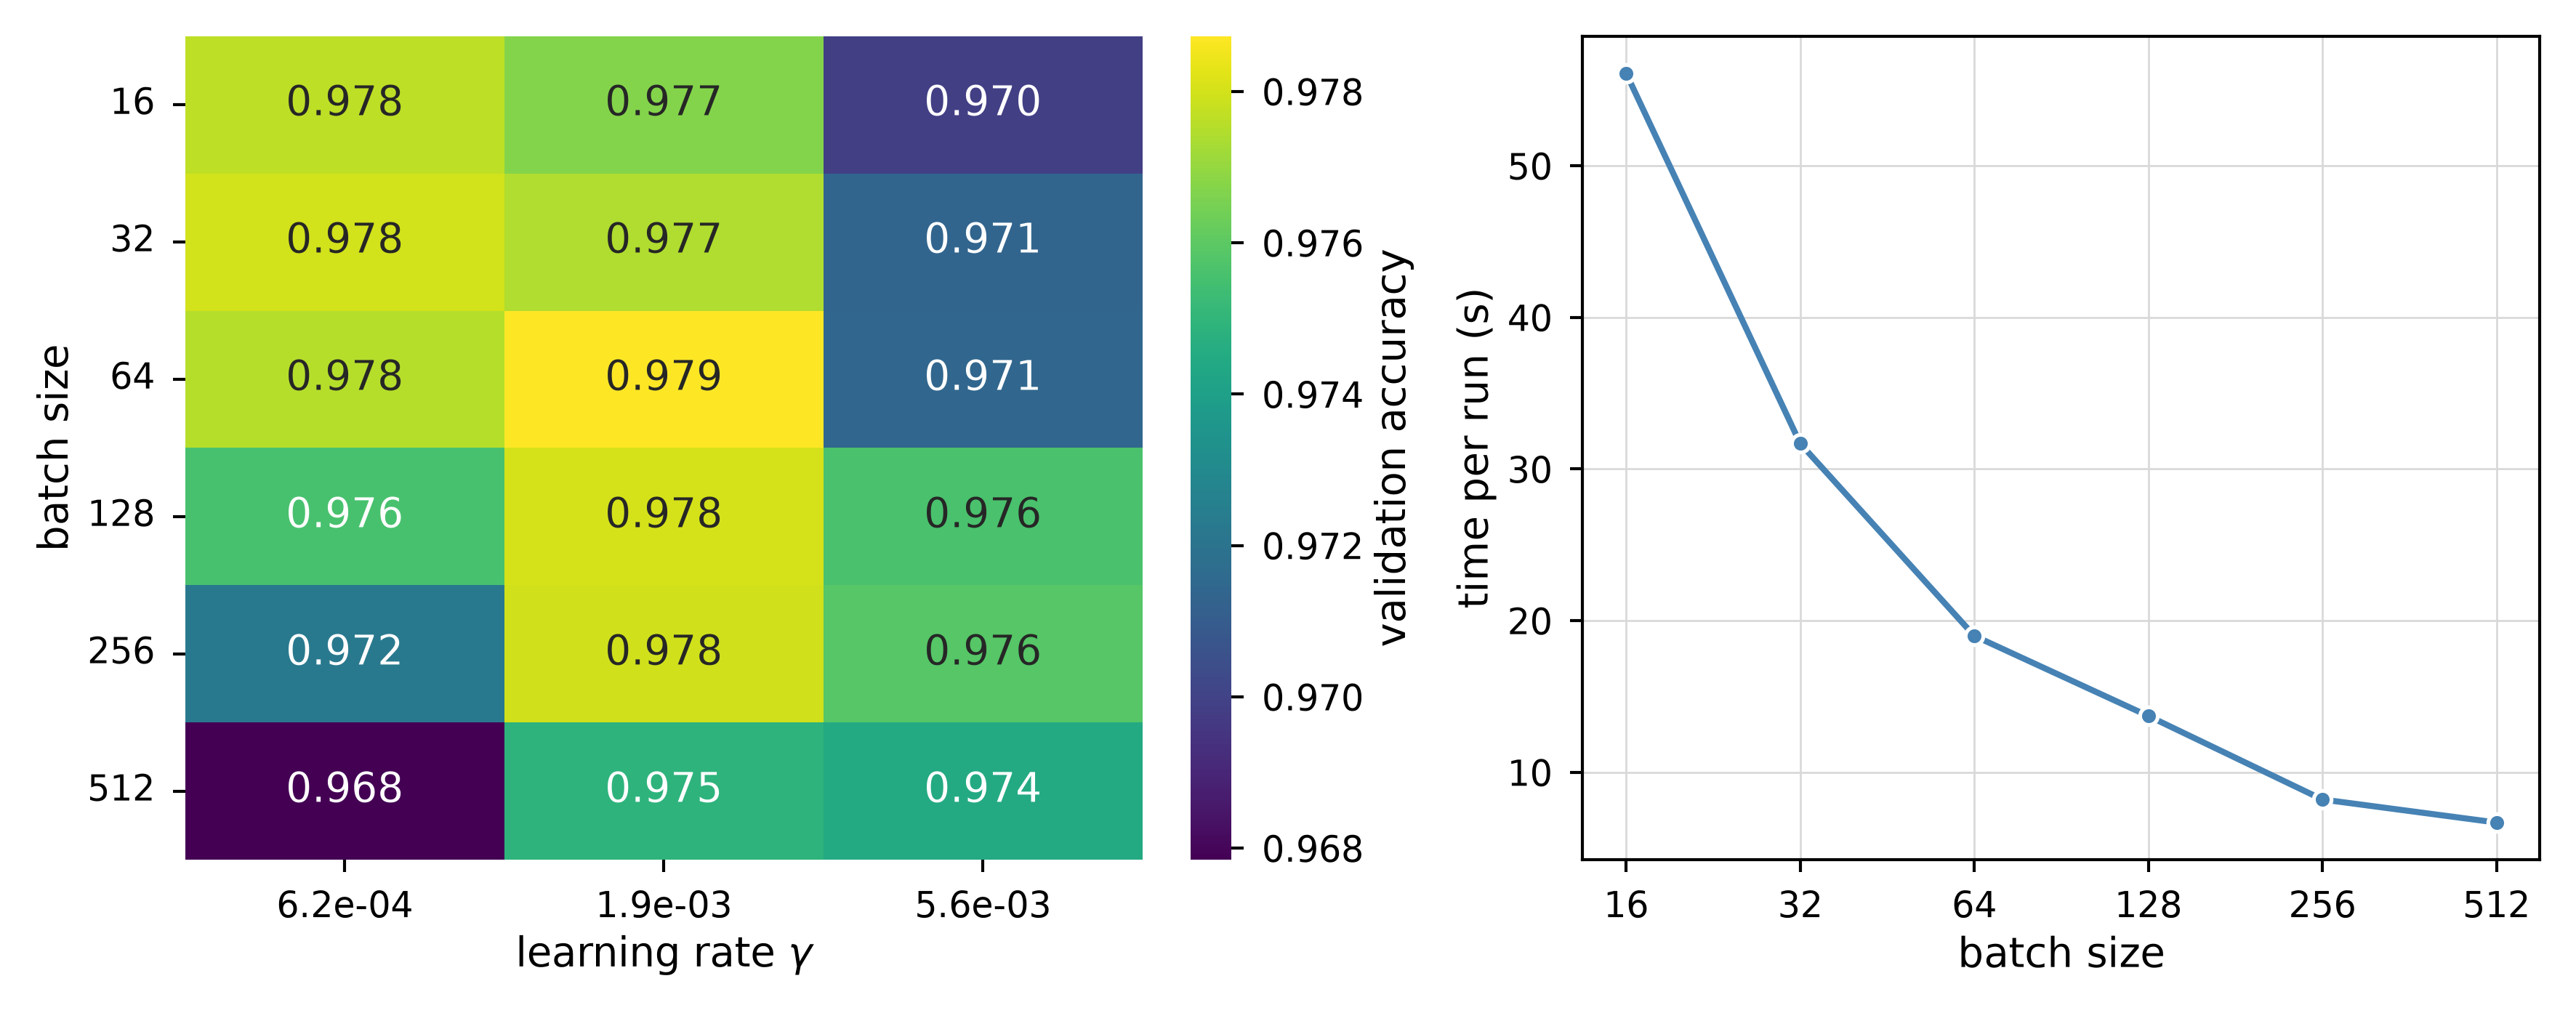

In [ ]:
BATCH_SIZES = [16, 32, 64, 128, 256, 512]
GAMMAS_BATCH = ARCH_GAMMA * np.array([1/3, 1, 3])

def compute_batch_sweep():
    shape = (len(BATCH_SIZES), len(GAMMAS_BATCH), len(SEEDS_E))
    val_accuracy, seconds = np.full(shape, np.nan), np.zeros(shape)
    for b, g, s in np.ndindex(shape):
        t0 = time.perf_counter()
        with np.errstate(all="ignore"):
            _, history = run_one_mnist(ARCH_ACTIVATION, (ARCH_WIDTH,) * ARCH_DEPTH,
                                       (0.0, 0.0), GAMMAS_BATCH[g], EPOCHS_E, BATCH_SIZES[b],
                                       SEEDS_E[s], method=OPT_METHOD)
        val_accuracy[b, g, s] = history["val_metric"][-1]
        seconds[b, g, s] = time.perf_counter() - t0
    return {"val_accuracy": val_accuracy, "seconds": seconds}

batch = u.cached_arrays(RESULTS_PATH / "e_batch.npz", compute_batch_sweep, RERUN)
acc_b = batch["val_accuracy"].mean(axis=-1)

# LLM (Claude): suggested method for how to account for time spent per run.
BATCH_TOL = 0.001
near_best = np.argwhere(acc_b >= acc_b.max() - BATCH_TOL)   # cells within noise of the best
b, g = min(near_best, key=lambda ix: batch["seconds"][ix[0], ix[1]].mean()) # cheapest of them
BATCH_E, ARCH_GAMMA = BATCH_SIZES[b], GAMMAS_BATCH[g]
print(f"batch size {BATCH_E}, gamma {ARCH_GAMMA:.1e}, val acc {acc_b[b, g]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(7, 2.7))
sns.heatmap(acc_b, ax=axes[0], annot=True, fmt=".3f", cmap="viridis",
            cbar_kws={"label": "validation accuracy"}, 
            xticklabels=[f"{g:.1e}" for g in GAMMAS_BATCH], yticklabels=BATCH_SIZES)
axes[0].set(xlabel=r"learning rate $\gamma$", ylabel="batch size")
axes[0].tick_params(axis="y", rotation=0)
sns.lineplot(x=BATCH_SIZES, y=batch["seconds"].mean(axis=(1, 2)), marker="o", ax=axes[1])
axes[1].set(xscale="log", xlabel="batch size", ylabel="time per run (s)", 
            xticks=BATCH_SIZES, xticklabels=BATCH_SIZES)
axes[1].minorticks_off()
fig.savefig(FIGURES_PATH / "E-batch_size.pdf")

Validation accuracy over penalty strength and learning rate on the chosen
architecture, for $\ell_1$ and $\ell_2$. A penalty is only used if it beats
no penalty by more than the noise

lambda (0.0, 0.0), gamma 1.9e-03


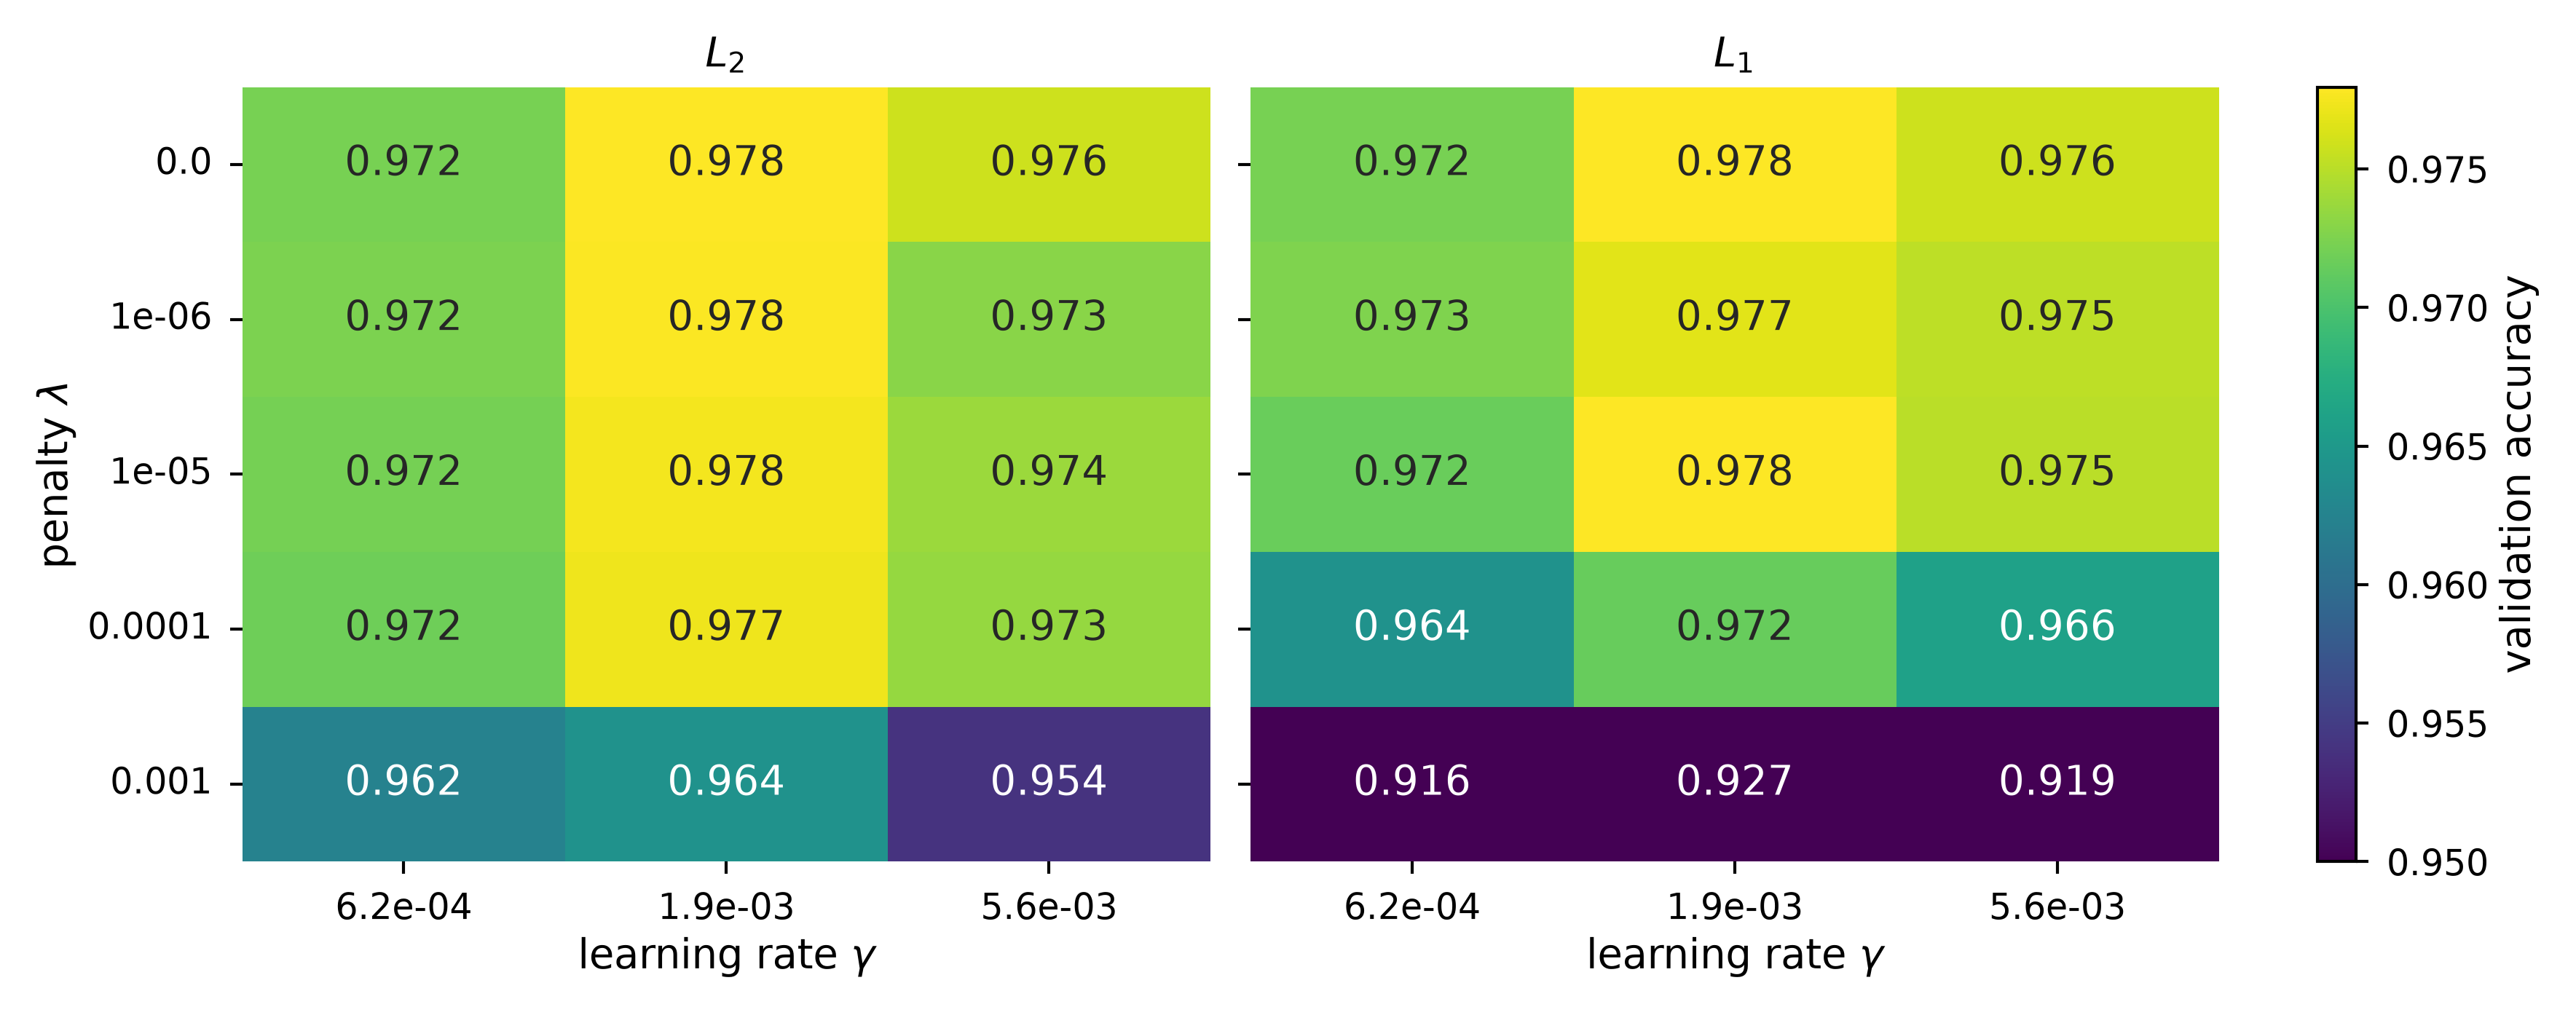

In [ ]:
LAMBDAS_E = np.array([0, 1e-6, 1e-5, 1e-4, 1e-3])
GAMMAS_PEN = ARCH_GAMMA * np.array([1/3, 1, 3])
NOISE = 0.002

def compute_penalty_sweep():
    shape = (len(NORMS), len(LAMBDAS_E), len(GAMMAS_PEN), len(SEEDS_E))
    val_accuracy = np.full(shape, np.nan)
    hidden = (ARCH_WIDTH,) * ARCH_DEPTH
    for n, l, g, s in np.ndindex(shape):
        lam = (LAMBDAS_E[l], 0.0) if NORMS[n] == "l1" else (0.0, LAMBDAS_E[l])
        with np.errstate(all="ignore"):
            _, history = run_one_mnist(ARCH_ACTIVATION, hidden, lam, GAMMAS_PEN[g],
                                       EPOCHS_E, BATCH_E, SEEDS_E[s], method=OPT_METHOD)
        val_accuracy[n, l, g, s] = history["val_metric"][-1]
    return {"val_accuracy": val_accuracy}

penalty = u.cached_arrays(RESULTS_PATH / "e_penalty.npz", compute_penalty_sweep, RERUN)
penalty_accuracy_mean = penalty["val_accuracy"].mean(axis=-1)

best_penalty = {}
fig, axes = plt.subplots(1, 2, figsize=(7, 2.7), sharey=True)
for ax, norm, grid in zip(axes, NORMS, penalty_accuracy_mean):
    sns.heatmap(grid, ax=ax, annot=True, fmt=".3f", cmap="viridis", cbar=False,
                vmin=0.95, vmax=np.nanmax(penalty_accuracy_mean),
                xticklabels=[f"{g:.1e}" for g in GAMMAS_PEN],
                yticklabels=LAMBDAS_E)
    ax.tick_params(axis="y", rotation=0)
    ax.set(title=f"$L_{norm[1]}$", xlabel=r"learning rate $\gamma$")
    best_penalty[norm] = u.best_cell(grid[1:], smallest=False, lam=LAMBDAS_E[1:],
                                     gamma=GAMMAS_PEN)
axes[0].set_ylabel(r"penalty $\lambda$")
fig.colorbar(axes[0].collections[0], ax=axes, label="validation accuracy")
fig.savefig(FIGURES_PATH / "E-penalty.pdf")

# Use a penalty only if it clearly beats lambda = 0
best_no_penalty = u.best_cell(penalty_accuracy_mean[0, 0], smallest=False, gamma=GAMMAS_PEN)
winner = max(best_penalty, key=lambda norm: best_penalty[norm]["value"])
if best_penalty[winner]["value"] > best_no_penalty["value"] + NOISE:
    lam_best = (best_penalty[winner]["lam"], 0.0) if winner == "l1" else (0.0, best_penalty[winner]["lam"])
    gamma_best = best_penalty[winner]["gamma"]
else:
    lam_best, gamma_best = (0.0, 0.0), best_no_penalty["gamma"]
print(f"lambda {lam_best}, gamma {gamma_best:.1e}")

Long run of the chosen configuration on the fit set. The validation curves
decide the number of epochs for the final model

best epoch 26, val accuracy 0.9808, min val cost at epoch 10


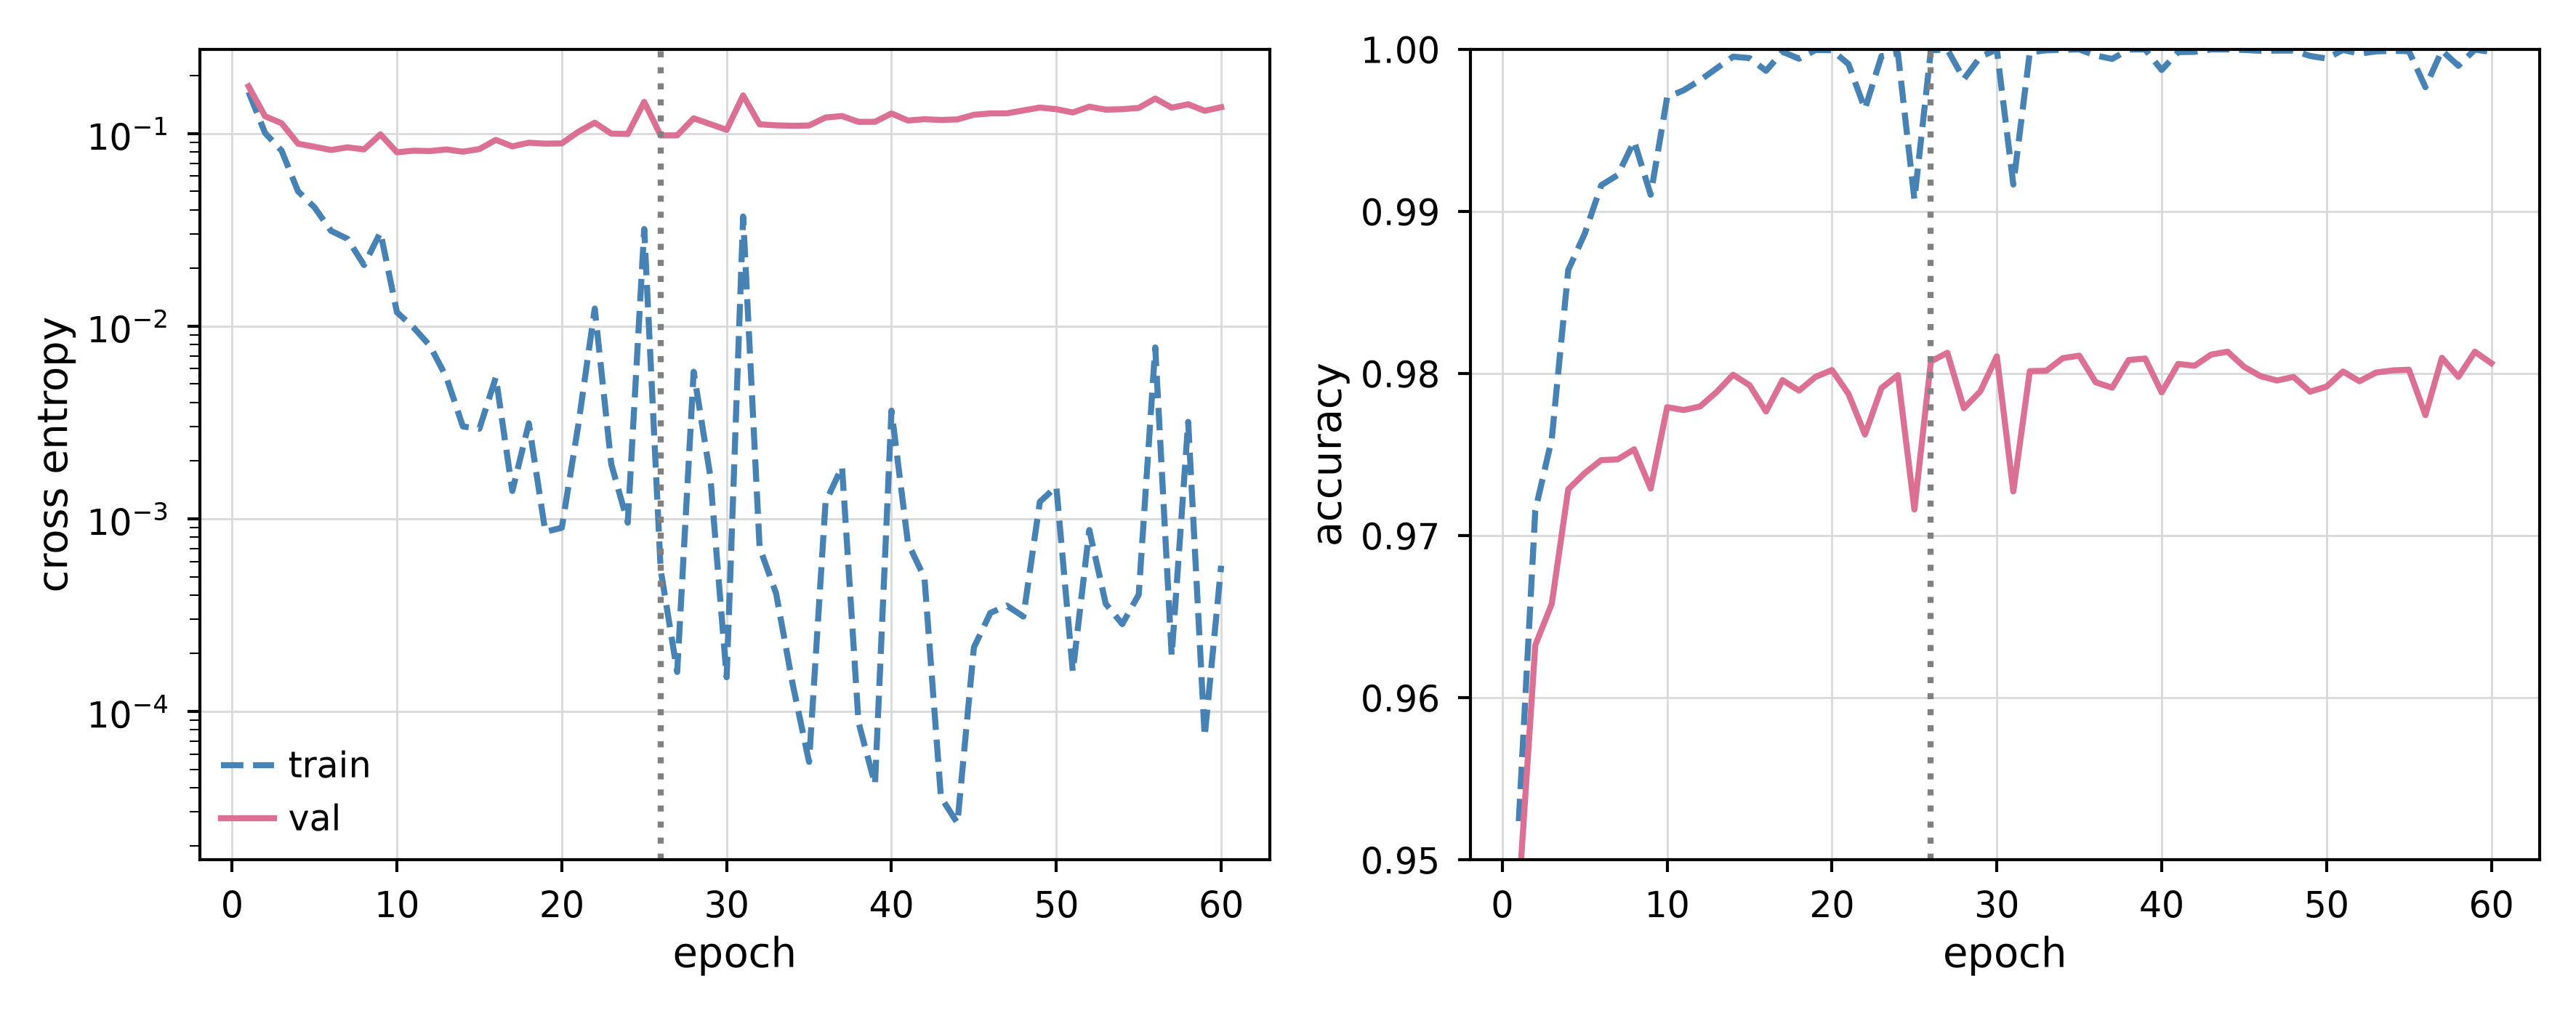

In [ ]:
FINAL = {"activation": ARCH_ACTIVATION,
         "hidden": (ARCH_WIDTH,) * ARCH_DEPTH,
         "lam": lam_best,
         "gamma": gamma_best,
         "method": OPT_METHOD}
EPOCHS_LONG = 60

def compute_final_val_curves():
    names = ("train_cost", "val_cost", "train_accuracy", "val_accuracy")
    curves = {name: np.zeros((len(SEEDS_E), EPOCHS_LONG)) for name in names}
    for s, seed in enumerate(SEEDS_E):
        _, history = run_one_mnist(FINAL["activation"], FINAL["hidden"], FINAL["lam"],
                                   FINAL["gamma"], EPOCHS_LONG, BATCH_E, seed,
                                   method=FINAL["method"])
        curves["train_cost"][s], curves["train_accuracy"][s] = history["train_cost"], history["train_metric"]
        curves["val_cost"][s], curves["val_accuracy"][s] = history["val_cost"], history["val_metric"]
    return curves

final_curves = u.cached_arrays(RESULTS_PATH / "e_final_val_curves.npz", compute_final_val_curves, RERUN)
epochs_long = np.arange(1, EPOCHS_LONG + 1)
val_accuracy_curve = final_curves["val_accuracy"].mean(axis=0)
val_cost_curve = final_curves["val_cost"].mean(axis=0)

# Fewest epochs that get within the noise of the best validation accuracy
best_epoch = int(np.argmax(val_accuracy_curve >= val_accuracy_curve.max() - NOISE / 2)) + 1
FINAL["epochs"] = best_epoch
print(f"best epoch {best_epoch}, val accuracy {val_accuracy_curve[best_epoch-1]:.4f}, "
      f"min val cost at epoch {int(np.argmin(val_cost_curve)) + 1}")

fig, axes = plt.subplots(1, 2, figsize=(7, 2.7))
for name, ax in zip(("cost", "accuracy"), axes):
    for split, ls in (("train", "--"), ("val", "-")):
        sns.lineplot(x=epochs_long, y=final_curves[f"{split}_{name}"].mean(axis=0), ls=ls,
                     label=split if name == "cost" else None, ax=ax)
    ax.axvline(best_epoch, color="gray", ls=":")
    ax.set(xlabel="epoch", ylabel="cross entropy" if name == "cost" else "accuracy")
axes[0].set_yscale("log")
axes[1].set_ylim(0.95, 1.0)
fig.savefig(FIGURES_PATH / "E-final_val_curves.pdf")

Retrain the whole training set, predict the test set

In [ ]:
SEEDS_FINAL = [0, 1, 2, 3, 4]

def train_on_full_train(hidden, activation, lam, gamma, epochs, method, seeds):
    '''Train on all 60k training images, return softmax outputs on the test set per seed'''
    l1, l2 = lam
    probs = np.zeros((len(seeds), len(x_test), 10))
    seconds = np.zeros(len(seeds))
    for s, seed in enumerate(seeds):
        net = NeuralNetwork([x_train.shape[1], *hidden, 10],
                            [activation] * len(hidden) + ["softmax"],
                            "cross_entropy", lmbd1=l1, lmbd2=l2, seed=seed)
        t0 = time.perf_counter()
        train(net, x_train, Y_train, method=method, gamma=gamma, epochs=epochs,
              batch_size=BATCH_E, seed=seed)
        seconds[s] = time.perf_counter() - t0
        probs[s] = net.predict(x_test)
    return {"probs": probs, "seconds": seconds}

final_nn = u.cached_arrays(RESULTS_PATH / "e_final_nn.npz", lambda: train_on_full_train(
    FINAL["hidden"], FINAL["activation"], FINAL["lam"], FINAL["gamma"],
    FINAL["epochs"], FINAL["method"], SEEDS_FINAL), RERUN)

# Same as baseline curves (no hidden layer, 20 epochs, adam)
final_lr = u.cached_arrays(RESULTS_PATH / "e_final_logreg_own.npz", lambda: train_on_full_train(
    (), "relu", (0.0, 0.0), 1e-3, EPOCHS_BASE, "adam", SEEDS_FINAL[:3]), RERUN)

Compare against same architecture in scikit-learn

In [ ]:
def compute_sklearn_mlp():
    t0 = time.perf_counter()
    mlp = MLPClassifier(hidden_layer_sizes=FINAL["hidden"], activation="relu",
                        solver="adam", batch_size=BATCH_E, learning_rate_init=FINAL["gamma"],
                        alpha=0.0, max_iter=FINAL["epochs"], n_iter_no_change=FINAL["epochs"],
                        random_state=SEED).fit(x_train, y_train)
    return {"probs": mlp.predict(x_test), "seconds": np.array(time.perf_counter() - t0)}

sk_mlp = u.cached_arrays(RESULTS_PATH / "e_sklearn_mlp.npz", compute_sklearn_mlp, RERUN)

table: test accuracy, with the two kinds of uncertainty

In [ ]:
preds_nn = final_nn["probs"].argmax(axis=2)
preds_lr = final_lr["probs"].argmax(axis=2)
acc_nn = np.array([accuracy(y_test, p) for p in preds_nn])
acc_lr = np.array([accuracy(y_test, p) for p in preds_lr])
se = lambda a: np.sqrt(a * (1 - a) / len(y_test))   # binomal standard error

rows = [("logistic, own code",          acc_lr.mean(), acc_lr.std(), final_lr["seconds"].mean()),
        ("logistic, sklearn (saga)",    accuracy(y_test, logreg_predictions), np.nan, np.nan),
        (f"NN {FINAL['hidden']}, own code", acc_nn.mean(), acc_nn.std(), final_nn["seconds"].mean()),
        ("MLP, sklearn",                accuracy(y_test, sk_mlp["probs"]), np.nan, float(sk_mlp["seconds"]))]
print(f"{'model':<34}{'test acc':>9}{'± SE':>8}{'seed std':>10}{'time (s)':>10}")
for name, a, sd, t in rows:
    print(f"{name:<34}{a:>9.4f}{se(a):>8.4f}{sd:>10.4f}{t:>10.1f}")

model                              test acc    ± SE  seed std  time (s)
logistic, own code                   0.9267  0.0026    0.0002       2.1
logistic, sklearn (saga)             0.9257  0.0026       nan       nan
NN (256,), own code                  0.9768  0.0015    0.0062      23.5
MLP, sklearn                         0.9830  0.0013       nan      43.4


Confusion matrix, full and errors only

true 9 -> predicted 4: 8 images
true 7 -> predicted 9: 7 images
true 7 -> predicted 2: 6 images
true 4 -> predicted 9: 6 images
true 5 -> predicted 3: 6 images

digit   precision   recall      F1
0           0.985    0.994   0.989
1           0.992    0.992   0.992
2           0.986    0.983   0.984
3           0.982    0.983   0.983
4           0.979    0.981   0.980
5           0.988    0.980   0.984
6           0.988    0.985   0.987
7           0.981    0.982   0.981
8           0.981    0.978   0.980
9           0.976    0.980   0.978
macro F1: NN 0.9838, logistic 0.9246


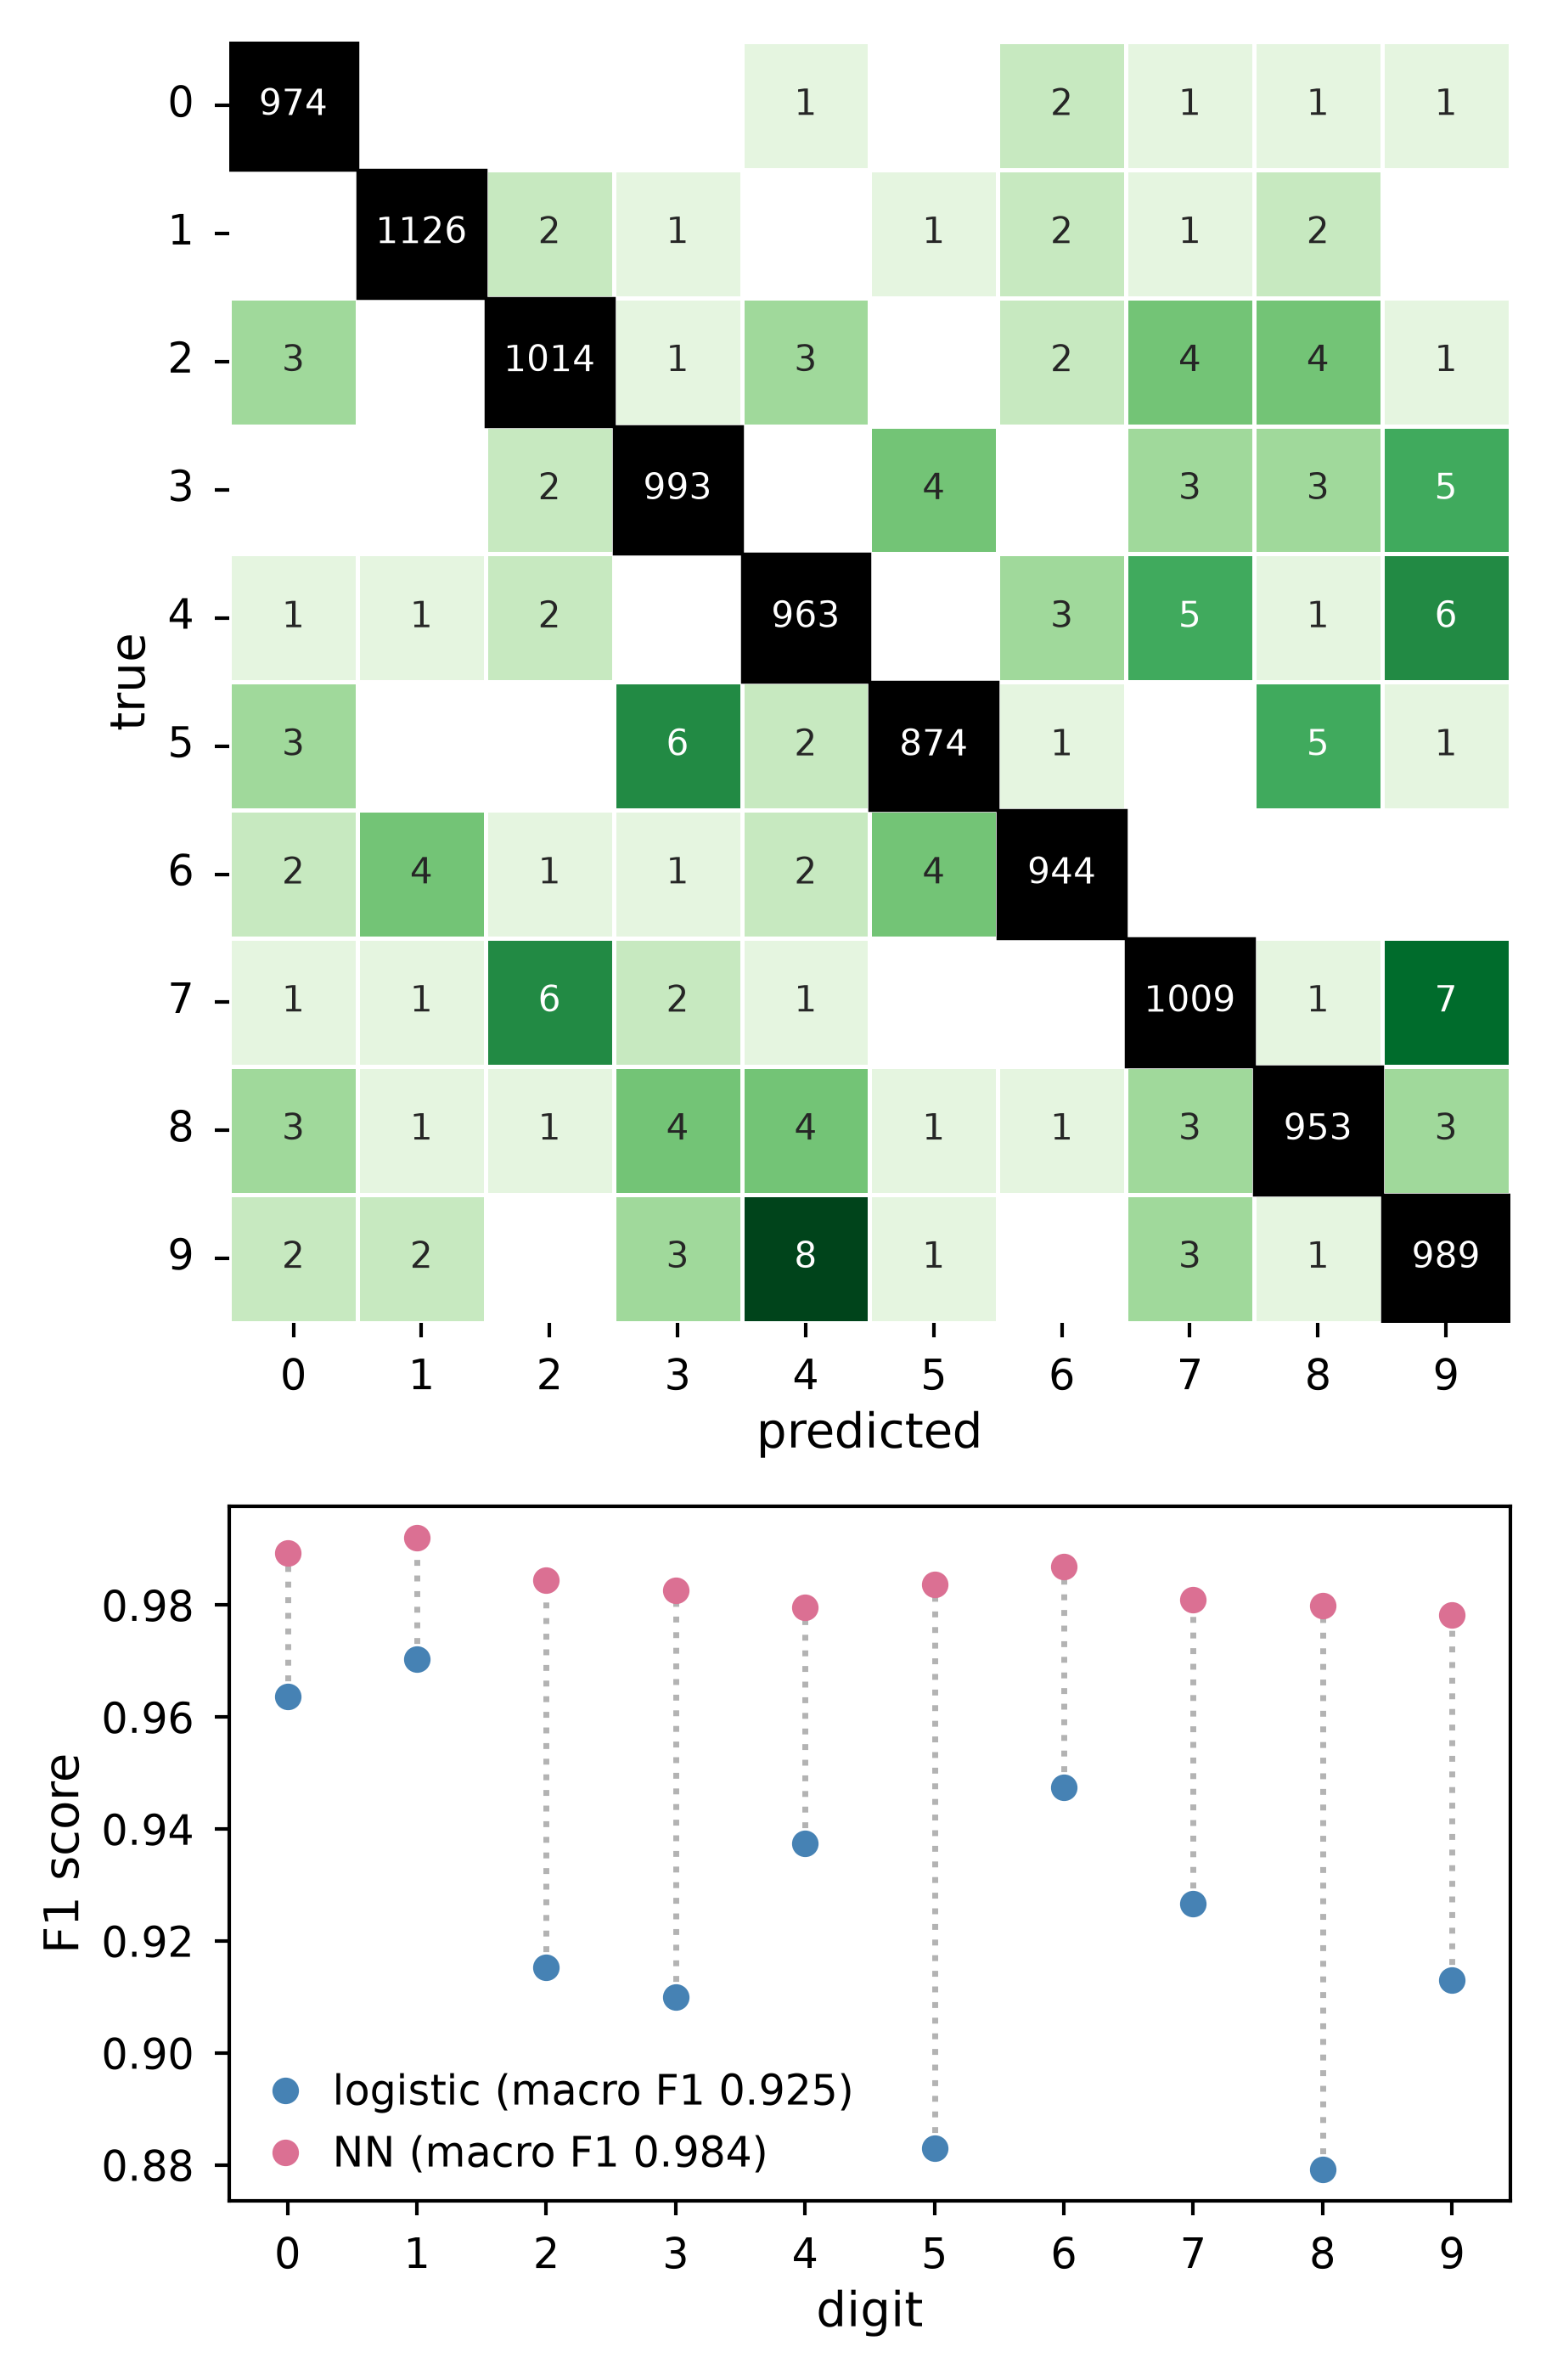

In [ ]:
C_nn = confusion_matrix(y_test, preds_nn[0])    # rows = true, columns = predicted
C_lr = confusion_matrix(y_test, logreg_predictions)
prec, rec, f1, macro_f1 = precision_recall_f1(C_nn)
_, _, f1_lr, macro_f1_lr = precision_recall_f1(C_lr)

fig, (ax_cm, ax_f1) = plt.subplots(2, 1, figsize=(COL, 5.6), gridspec_kw={"height_ratios": [3.3, 1.7]})

errors = C_nn.copy(); np.fill_diagonal(errors, 0)
sns.heatmap(errors, ax=ax_cm, mask=(errors == 0), cmap="Greens", vmin=0, cbar=False,
            square=True, annot=True, fmt="d", annot_kws={"size": 6}, linewidths=0.5,
            linecolor="white")
for k in range(10):
    ax_cm.add_patch(Rectangle((k, k), 1, 1, color="k"))
    ax_cm.text(k + 0.5, k + 0.5, f"{C_nn[k, k]}",
               ha="center", va="center", fontsize=6, color="white")
ax_cm.set(xlabel="predicted", ylabel="true")
ax_cm.tick_params(axis="y", rotation=0)
ax_cm.grid(False)

digits = np.arange(10)
ax_f1.vlines(digits, f1_lr, f1, color="0.7", lw=1, ls=":")
ax_f1.plot(digits, f1_lr, "o", color="steelblue", label=f"logistic (macro F1 {macro_f1_lr:.3f})")
ax_f1.plot(digits, f1, "o", color="palevioletred", label=f"NN (macro F1 {macro_f1:.3f})")
ax_f1.set(xticks=digits, xlabel="digit", ylabel="F1 score")
ax_f1.legend(loc="lower left")
ax_f1.grid(False)
fig.savefig(FIGURES_PATH / "E-confusion_and_f1.pdf")

for flat in np.argsort(errors, axis=None)[::-1][:5]:
    t, p = divmod(flat, 10)
    print(f"true {t} -> predicted {p}: {errors[t, p]} images")
    
print()
print(f"{'digit':<7}{'precision':>10}{'recall':>9}{'F1':>8}")
for k in range(10):
    print(f"{k:<7}{prec[k]:>10.3f}{rec[k]:>9.3f}{f1[k]:>8.3f}")
print(f"macro F1: NN {macro_f1:.4f}, logistic {macro_f1_lr:.4f}")

the most confident mistakes

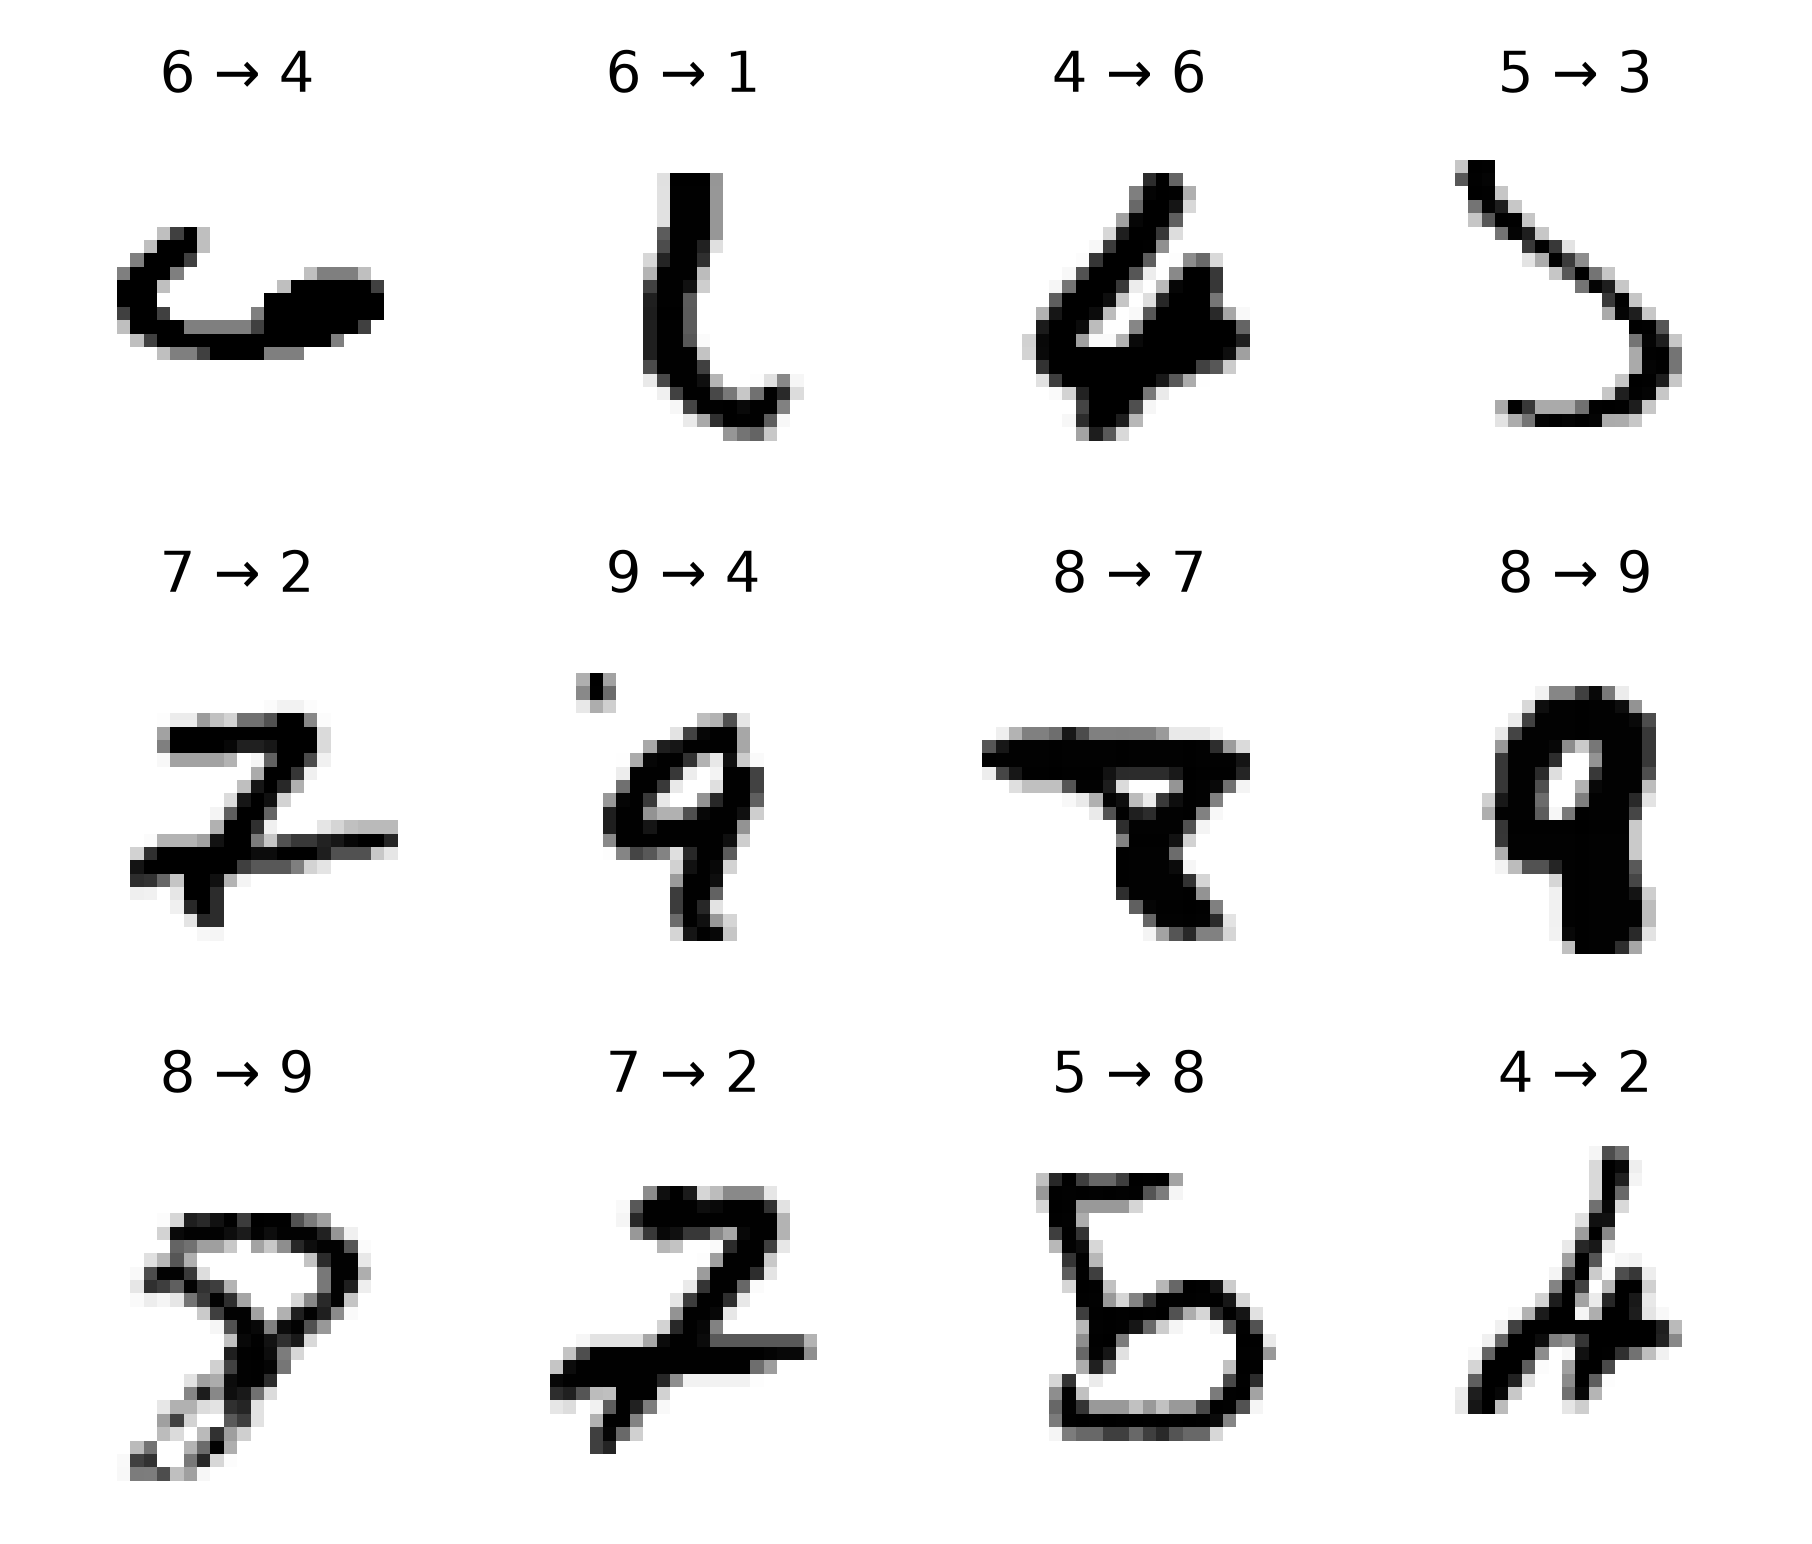

In [ ]:
probs0, pred0 = final_nn["probs"][0], preds_nn[0]
wrong = np.flatnonzero(pred0 != y_test)
worst = wrong[np.argsort(probs0[wrong, pred0[wrong]])[::-1][:12]]   # most confident wrong

fig, axes = plt.subplots(3, 4, figsize=(COL, 3))
for ax, i in zip(axes.ravel(), worst):
    ax.imshow(x_test[i].reshape(28, 28), cmap="gray_r")
    ax.set_title(f"{y_test[i]} → {pred0[i]}")
    ax.axis("off")
fig.savefig(FIGURES_PATH / "E-misclassified.pdf")

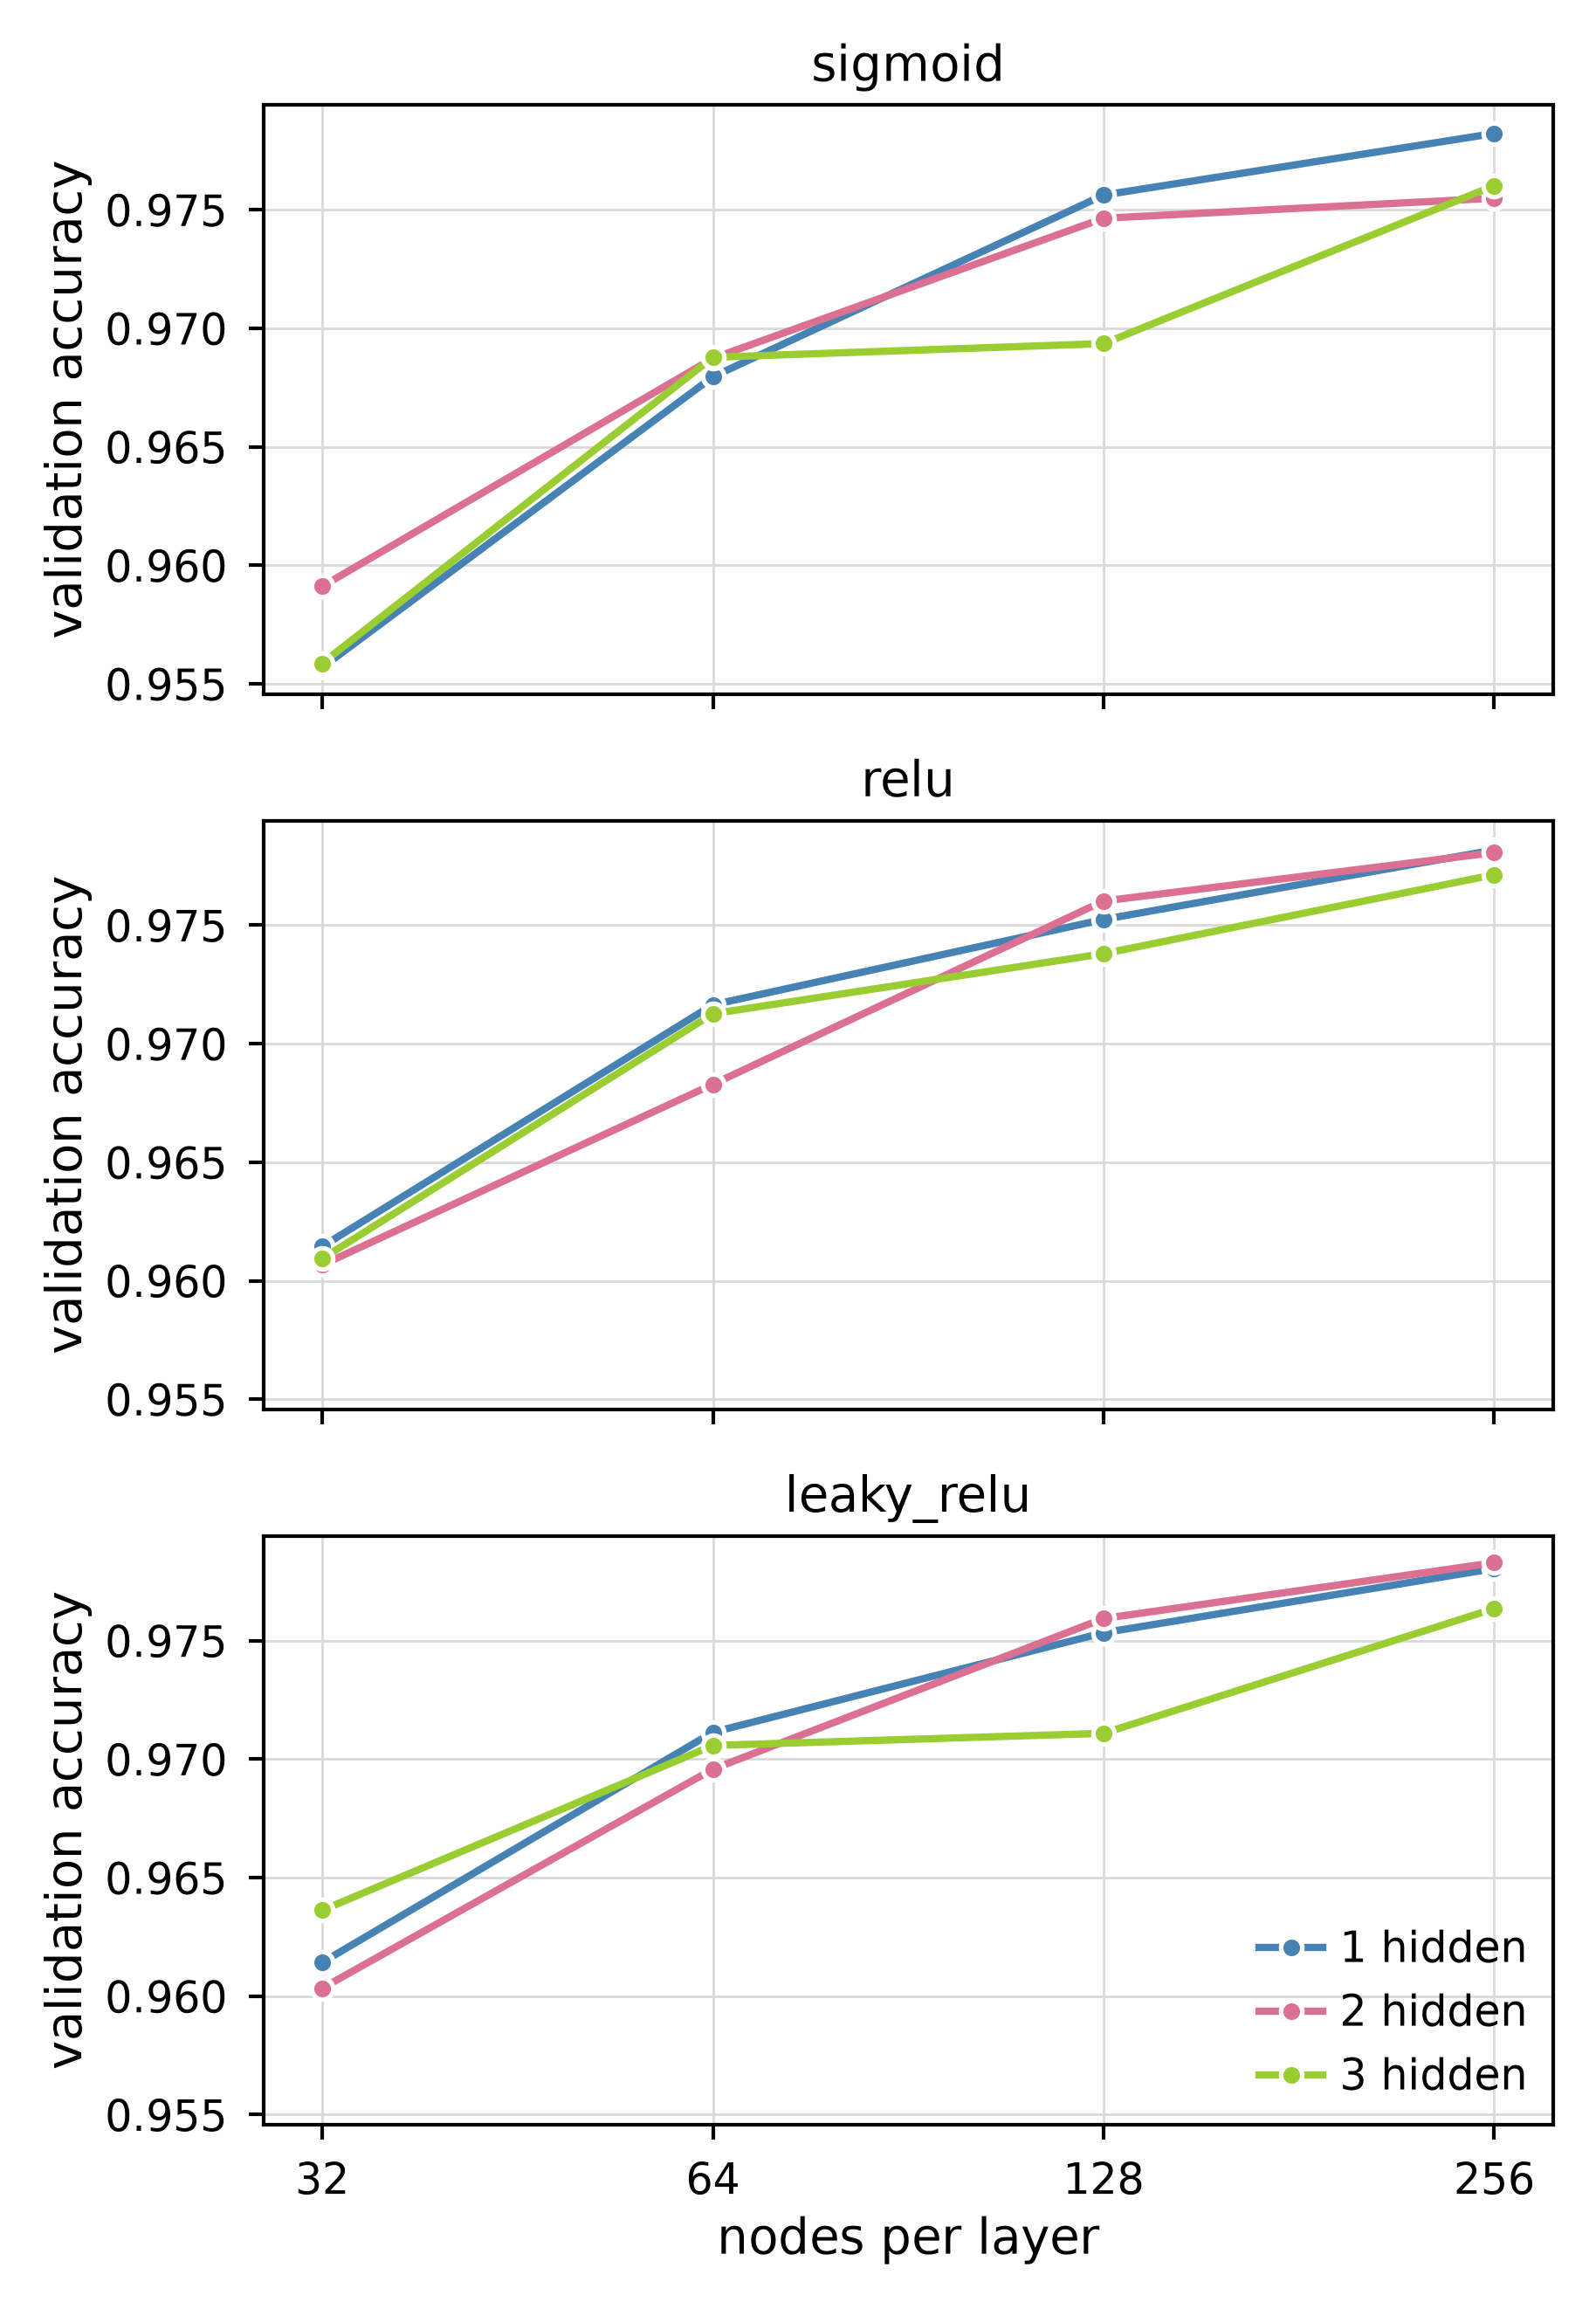

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(COL, 5.2), sharex=True, sharey=True)
for a, ax in enumerate(axes):
    for d, depth in enumerate(DEPTHS_E):
        sns.lineplot(x=WIDTHS_E, y=arch_accuracy_best[a, d], marker="o", label=f"{depth} hidden", ax=ax)
    #ax.axhline(baseline["val_accuracy"][0, -1], color="k", ls=":", label="no hidden layer")
    ax.set(ylabel="validation accuracy", title=ACTIVATIONS_E[a])
axes[-1].legend(loc="lower right")
axes[-1].set(xscale="log", xticks=WIDTHS_E, xticklabels=WIDTHS_E, xlabel="nodes per layer")
axes[-1].minorticks_off()
for ax in axes[:-1]:
    ax.get_legend().remove()        # one legend is enough
fig.savefig(FIGURES_PATH / "E-width_curves.pdf")

<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part f)** Various algorithms

</div>

In [ ]:
import pandas as pd

def n_params(sizes):
    return sum((a + 1) * b for a, b in zip(sizes[:-1], sizes[1:]))

def time_it(fn, repeats=3):
    best = np.inf
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        best = min(best, time.perf_counter() - t0)
    return best

# Regression network from part C
R_ACT, R_DEPTH, R_WIDTH = best_c["activation"], best_c["depth"], best_c["width"]
R_SIZES = [1] + [R_WIDTH] * R_DEPTH + [1]

def time_nn(lam, gamma):
    def fit():
        net = NeuralNetwork(R_SIZES, [R_ACT] * R_DEPTH + ["identity"], "mse",
                            lmbd1=lam[0], lmbd2=lam[1], seed=SEED)
        with np.errstate(all="ignore"):
            train(net, runge_X_train, runge_Y_train, method="rmsprop",
                  gamma=gamma, epochs=EPOCHS_D, batch_size=10, seed=SEED)
    return time_it(fit, repeats=2)

# Tuning effort = numer of fits / training runs used choose hyperparameters
effort_b = len(OPTIMIZERS) * len(LEARNING_RATES) + len(ARCHITECTURES) * len(LEARNING_RATES)
effort_c = depth_width["val_mse"].size
effort_d = penalty_sweep["val_mse"][0].size
effort = {"OLS": MAX_DEGREE * K,
          "Ridge": MAX_DEGREE * len(ALPHAS_P1) * K,
          "Lasso": MAX_DEGREE * len(ALPHAS_P1) * K,
          "NN, no penalty": effort_b + effort_c,
          "NN, L2": effort_b + effort_c + effort_d,
          "NN, L1": effort_b + effort_c + effort_d}

rows = []
for name, Model, extra in [("OLS", LinearRegression, {}), ("Ridge", Ridge, {}),
                           ("Lasso", Lasso, {"max_iter": 100_000})]:
    info = benchmarks[name]
    kw = {} if name == "OLS" else {"alpha": info["alpha"]}
    t = time_it(lambda: u.poly_model(info["degree"], Model(**kw, **extra)).fit(runge_X_train, runge_y_train))
    hyper = f"degree {info['degree']}" + ("" if name == "OLS" else rf", $\alpha$={info['alpha']:.0e}")
    rows.append([name, hyper, info["degree"] + 1, rf"{info['test_mse']:.4f}", f"{1e3 * t:.1f}", effort[name]])
    
for name, (lam, gamma) in nn_settings.items():
    mean, std, _ = nn_results[name]
    hyper = rf"{R_DEPTH}$\times${R_WIDTH} {R_ACT}, $\lambda$={max(lam):.0e}, $\gamma$={gamma:.0e}"
    rows.append([name, hyper, n_params(R_SIZES), rf"{mean:.4f} $\pm$ {std:.4f}",
    f"{1e3 * time_nn(lam, gamma):.1f}", effort[name]])
    
reg_df = pd.DataFrame(rows, columns=["Model", "Settings", "Parameters", "Test MSE", "Train time (ms)", "Tuning fits"])
print(reg_df.to_string(index=False))
print("noise floor sigma^2 = ", 0.1 ** 2)
reg_df.to_latex(RESULTS_PATH / "f_regression_table.tex", index=False, escape=False)

         Model                                          Settings  Parameters            Test MSE Train time (ms)  Tuning fits
           OLS                                         degree 12          13              0.0093             0.7          100
         Ridge                         degree 14, $\alpha$=4e-07          15              0.0105             0.6          600
         Lasso                         degree 14, $\alpha$=1e-08          15              0.0085            47.7          600
NN, no penalty 4$\times$25 relu, $\lambda$=0e+00, $\gamma$=1e-03        2026 0.0165 $\pm$ 0.0006           265.3          648
        NN, L2 4$\times$25 relu, $\lambda$=1e-03, $\gamma$=3e-04        2026 0.0074 $\pm$ 0.0009           267.1          816
        NN, L1 4$\times$25 relu, $\lambda$=3e-04, $\gamma$=3e-04        2026 0.0078 $\pm$ 0.0009           266.0          816
noise floor sigma^2 =  0.010000000000000002


In [ ]:
macro = lambda pred: precision_recall_f1(confusion_matrix(y_test, pred))[3]
se = lambda a: np.sqrt(a * (1 - a) / len(y_test))
sizes_nn = [x_train.shape[1], *FINAL["hidden"], 10]

# Tuning effort for the NN
effort_e = (optimizer["val_accuracy"].size + architecture["val_accuracy"].size
            + penalty["val_accuracy"].size + batch["val_accuracy"].size
            + int(np.prod(finalist_curves["val_accuracy"].shape[:2])))
sk_hidden = FINAL["hidden"]

rows = [
    ["Logistic, own code", acc_lr.mean(), macro(preds_lr[0]), n_params([x_train.shape[1], 10]),
     final_lr["seconds"].mean(), 0],
    ["Logistic, scikit-learn", accuracy(y_test, logreg_predictions), macro(logreg_predictions),
     n_params([x_train.shape[1], 10]), np.nan, 10],
    ["NN, own code", acc_nn.mean(), macro(preds_nn[0]), n_params(sizes_nn),
     final_nn["seconds"].mean(), effort_e],
    ["MLP, scikit-learn", accuracy(y_test, sk_mlp["probs"]), macro(sk_mlp["probs"]),
     n_params(sizes_nn), float(sk_mlp["seconds"]), 0]
]
cls_df = pd.DataFrame(rows, columns=["Model", "Accuracy", "Macro F1", "Parameters", "Train time (s)", "Tuning fits"])
cls_df["Accuracy"] = [rf"{a:.4f} $\pm$ {se(a):.4f}" for a in cls_df["Accuracy"]]
cls_df["Macro F1"] = cls_df["Macro F1"].map(":.4f".format)
cls_df["Train time (s)"] = cls_df["Train time (s)"].map(lambda t: "n/a" if np.isnan(t) else f"{t:.0f}")
print(cls_df.to_string(index=False))
cls_df.to_latex(RESULTS_PATH / "f_classification_table.tex", index=False, escape=False)

                 Model            Accuracy Macro F1  Parameters Train time (s)  Tuning fits
    Logistic, own code 0.9267 $\pm$ 0.0026     :.4f        7850              2            0
Logistic, scikit-learn 0.9257 $\pm$ 0.0026     :.4f        7850            n/a           10
          NN, own code 0.9768 $\pm$ 0.0015     :.4f      203530             23          621
     MLP, scikit-learn 0.9830 $\pm$ 0.0013     :.4f      203530             43            0


Comparison with jax

In [ ]:
net = NeuralNetwork([1, 8, 8, 1], ["sigmoid", "sigmoid", "identity"], "mse", lmbd2=1e-3, seed=SEED)
def cost_jax(params):
    a = jnp.asarray(runge_X_fit)
    for (W, b), name in zip(params, net.activation_names):
        z = a @ W + b
        a = jax.nn.sigmoid(z) if name == "sigmoid" else z
    return jnp.mean((a - runge_Y_fit) ** 2) + net.lmbd2 * sum(jnp.sum(W ** 2) for W, _ in params)

auto = jax.grad(cost_jax)([(jnp.asarray(W), jnp.asarray(b)) for W, b in net.layers])
ours = net.compute_gradient(runge_X_fit, runge_Y_fit)
for l, ((dW, db), (gW, gb)) in enumerate(zip(ours, auto), 1):
    print(l, np.abs(dW - gW).max(), np.abs(db - gb).max())
    
# linear network (no hidden layer) should land on the OLS solution
lin = NeuralNetwork([1, 1], ["identity"], "mse", seed=SEED)
train(lin, runge_X_train, runge_Y_train, method="plain", gamma=0.1, epochs=3000)
theta = u.closed_form(np.column_stack([np.ones(len(runge_x_train)), runge_x_train]), runge_y_train)
print(theta, lin.layers[0][1], lin.layers[0][0].ravel())

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


1 1.951563910473908e-18 1.3877787807814457e-17
2 2.7755575615628914e-17 5.551115123125783e-17
3 2.220446049250313e-16 2.220446049250313e-16
[-0.02589666  0.02235106] [-0.02589666] [0.02235106]
